# HMM experiments: Gaussian, GMM, and two spline-flow emissions

Compare **four emissions** on the **exact saved observations** used by the existing
Gaussian/GMM experiments: Gaussian, three-component GMM, RQ-NSF with a Gaussian base,
and RQ-NSF with a Student-t base.

Both **mean-separated** and **volatility-only** regimes use three states with
self-transition probability **0.995**. The saved runs contain four generating
families: Gaussian, Student-t, trimodal, and skewed Gamma.

## Settings and recovered source runs

These are the saved **0.995** runs, rather than the older 0.9-persistence runs.
The mean-separated run uses seed 42 and means $(-2,0,2)$ with variance 1. The
volatility-only run uses seed 31, zero means, and standard deviations $(1,2,4)$.
Each has 10 replicates, 20,000 training observations, 5,000 independent test
observations, 10 starts, and a 1,000-update maximum. Pair models **within** each
regime/family/replicate.

In [1]:
from dataclasses import asdict
from pathlib import Path
import itertools
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

project_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "src/flexible_emission_hmm").is_dir()
)
for path in (project_root / "src", project_root / "notebooks"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import nf_hmmlearn_comparison as experiment

plt.rcParams.update({"font.size": 10, "axes.grid": False})
pd.set_option("display.max_columns", 20)

SOURCES = dict(experiment.SOURCES)
DEVICE = "cpu" 
DTYPE = "float64"
N_JOBS = 8  # Independent CPU worker processes. Set 1 for sequential fits.
TORCH_THREADS = 1  # PyTorch/BLAS threads per worker.
EMISSION_BATCH_SIZE = 2048  # None uses full-data gradient updates.
CONVERGENCE_PATIENCE = 5  # Consecutive small post-update likelihood changes.
BASE_FLOW = experiment.FlowSettings(
    bound=5.0, base_df=5.0, m_step_steps=10, batch_size=EMISSION_BATCH_SIZE,
    device=DEVICE, dtype=DTYPE, convergence_patience=CONVERGENCE_PATIENCE
)
TUNING = experiment.TuningSettings(
    count_bins=(4, 8, 16),
    num_layers=(1, 2, 3),
    m_step_steps=(10, 20),
    learning_rates=(1e-3,),
    student_dfs=(5.0,),  # Fixed Student-t degrees of freedom.
    replicates=(0, 1, 2),
    train_fraction=0.8,
    n_starts=3,  # Tuning only; final fits inherit 10 starts.
    max_iter=300,
)

# Reuse the completed sweep. To retune, choose a new TUNING_RUN_NAME first.
TUNING_RUN_NAME = (
    "four_emissions_p995_hmmlearn_m10_l2_b8-16_s2_i150"
    "_batch2048_float64_cpu8x1_v2"
)
RUN_NAME = f"{TUNING_RUN_NAME}_patience{CONVERGENCE_PATIENCE}_v2"
experiment_dir = project_root / "data/synthetic/nf_spline_experiments"
tuning_dir = experiment_dir / TUNING_RUN_NAME / "tuning"
run_dir = experiment_dir / RUN_NAME
RUN_TUNING = True  # The completed sweep already selected the hyperparameters.
RUN_FINAL = True
REPORT_EXISTING = False

sources = experiment.load_sources(project_root, SOURCES)
display(pd.DataFrame([
    dict(regime=regime, source=str(source.path.relative_to(project_root)),
         persistence=source.transitions[0, 0], **source.settings)
    for regime, source in sources.items()
]).drop(columns=["quad_epsabs", "quad_epsrel", "quad_limit"], errors="ignore"))
print(f"Emission device: {DEVICE}; dtype: {DTYPE}")
print("Flow backend: hmmlearn; tuning M-step steps:", TUNING.m_step_steps)
print("Emission batch size:", EMISSION_BATCH_SIZE or "full dataset")
print("Convergence patience:", CONVERGENCE_PATIENCE)
print("Saved tuning:", tuning_dir)
print("Final output:", run_dir)
print(f"CPU workers: {N_JOBS}; threads per worker: {TORCH_THREADS}")
print("Tuning enabled:", RUN_TUNING, "Final training enabled:", RUN_FINAL)

,regime,source,persistence,master_seed,train_sizes,n_test,n_density,n_replicates,n_starts,n_components,max_iter,tol_per_observation,min_variance,include_wide,bootstrap_samples,state_stds,self_transition,noise_levels
0,mean,data/synthetic/gmm_synthetic_experiments/20261...,0.995,42,[20000],5000,10000,10,10,3,1000,0.000001,0.000001,False,2000,NaN,NaN,NaN
1,volatility,data/synthetic/volatility_markov_experiments/2...,0.995,31,[20000],5000,10000,10,10,3,1000,0.000001,0.000001,False,2000,"[1.0, 2.0, 4.0]",0.995,"[0.1, 0.25, 0.5]"


Emission device: cpu; dtype: float64
Flow backend: hmmlearn; tuning M-step steps: (10, 20)
Emission batch size: 2048
Convergence patience: 5
Saved tuning: /Users/leoyang/Desktop/School/CSCD94/data/synthetic/nf_spline_experiments/four_emissions_p995_hmmlearn_m10_l2_b8-16_s2_i150_batch2048_float64_cpu8x1_v2/tuning
Final output: /Users/leoyang/Desktop/School/CSCD94/data/synthetic/nf_spline_experiments/four_emissions_p995_hmmlearn_m10_l2_b8-16_s2_i150_batch2048_float64_cpu8x1_v2_patience5_v2
CPU workers: 8; threads per worker: 1
Tuning enabled: True Final training enabled: True


## Model and metric definitions

All models use the same HMM equations and expected-count transition updates.
The two flow models now use `hmmlearn_flow_hmm.FlowHMM` with compiled CPU
forward–backward, filtering, and Viterbi. Their chain initialization remains uniform
to match the previous experiment; Gaussian/GMM baselines are still restored.
Flows use generalized Baum–Welch with gradient-based emission M-steps. For a flow
mapping observations to base variables,

$$
\log p_k(x)=\log p_{\mathrm{base}}(f_k(x))+\log|f_k'(x)|.
$$

The normal base has unit variance. The Student-t base is also standardized to unit
variance using scale $\sqrt{(\nu-2)/\nu}$; $\nu>2$ ensures finite emission variance.
Its degrees of freedom are fixed at **5** for tuning and final fitting. The spline
bound is fixed at **5**, so its normalized transformation interval is $[-5,5]$.
Identity spline tails retain Gaussian or Student-t tail
behavior, respectively. Both variants retain the same trainable location/scale.

| Metric group | Metrics retained from the reference experiments |
|---|---|
| State classification | Accuracy; macro/weighted precision, recall, F1; balanced accuracy; MCC; ARI; NMI; per-state reports and confusion matrices |
| State probabilities | Capped state log loss and cap/zero fractions; Brier score; mean true-state posterior |
| Switching | Switch precision, recall, F1; rates; signed and absolute switch-count errors |
| Density and parameter recovery | Test NLL per observation; clean-target emission KL; mean RMSE; variance RMSE; quadrature errors |
| Reliability and cost | Start failures; convergence; iterations; likelihood decreases; selected and total fit times |


## Training-only hyperparameter tuning

For each regime, generating family, and flow base, fit on the first 80% of each
configured training replicate. Choose each fold's restart by prefix training
likelihood, then score its remaining 20% using conditional predictive NLL.

`TUNING` defines the bin/layer grids, Adam updates per M-step, validation
replicates, restart count, and outer-iteration cap. `BASE_FLOW.batch_size` is fixed
across candidates and inherited by both bases and final fits. A batch size of
2,048 draws that many observations uniformly with replacement per gradient
update, using their fixed E-step weights. `m_step_steps` counts sampled-batch
updates per state, not complete passes through the data. None or a batch size at
least as large as the fitted dataset uses the full-batch method.

In [2]:
common_candidates = (len(TUNING.count_bins) * len(TUNING.num_layers)
                     * len(TUNING.m_step_steps) * len(TUNING.learning_rates))
family_groups = sum(len(source.families) for source in sources.values())
tuning_fits = (family_groups * common_candidates * (1 + len(TUNING.student_dfs))
               * len(TUNING.replicates) * TUNING.n_starts)
final_fits = sum(
    len(source.families) * len(source.settings["train_sizes"])
    * source.settings["n_replicates"] * source.settings["n_starts"] * 2
    for source in sources.values()
)
display(pd.DataFrame([
    {"stage": "Training-only tuning", "maximum fitting attempts": tuning_fits},
    {"stage": "Final fits: both flow bases", "maximum fitting attempts": final_fits},
    {"stage": "Gaussian/GMM refits", "maximum fitting attempts": 0},
]))

if RUN_TUNING:
    torch.set_num_threads(TORCH_THREADS)
    selections, tuning_rows = experiment.tune_flows(
        sources, tuning_dir, BASE_FLOW, TUNING,
        n_jobs=N_JOBS, torch_threads=TORCH_THREADS,
    )
else:
    print("Tuning disabled; no hyperparameters have been selected by this cell.")

,stage,maximum fitting attempts
0,Training-only tuning,2592
1,Final fits: both flow bases,1600
2,Gaussian/GMM refits,0


Validation mean / Gaussian / candidate 0 / replicate 0: ok
Validation mean / Gaussian / candidate 0 / replicate 1: ok
Validation mean / Gaussian / candidate 0 / replicate 2: ok
Validation mean / Gaussian / candidate 1 / replicate 0: ok
Validation mean / Gaussian / candidate 1 / replicate 1: ok
Validation mean / Gaussian / candidate 1 / replicate 2: ok
Validation mean / Gaussian / candidate 2 / replicate 0: ok
Validation mean / Gaussian / candidate 2 / replicate 1: ok
Validation mean / Gaussian / candidate 2 / replicate 2: ok
Validation mean / Gaussian / candidate 3 / replicate 0: ok
Validation mean / Gaussian / candidate 3 / replicate 1: ok
Validation mean / Gaussian / candidate 3 / replicate 2: ok
Validation mean / Gaussian / candidate 4 / replicate 0: ok
Validation mean / Gaussian / candidate 4 / replicate 1: ok
Validation mean / Gaussian / candidate 4 / replicate 2: ok
Validation mean / Gaussian / candidate 5 / replicate 0: ok
Validation mean / Gaussian / candidate 5 / replicate 1: 

Model is not converging.  Current: -30606.352068212975 is not greater than -30606.352068196324. Delta is -1.665102900005877e-08


Validation volatility / Trimodal / candidate 1 / replicate 2: ok
Validation volatility / Trimodal / candidate 2 / replicate 0: ok
Validation volatility / Trimodal / candidate 2 / replicate 1: ok
Validation volatility / Trimodal / candidate 2 / replicate 2: ok


Model is not converging.  Current: -30606.352068212975 is not greater than -30606.352068196324. Delta is -1.665102900005877e-08


Validation volatility / Trimodal / candidate 3 / replicate 0: ok
Validation volatility / Trimodal / candidate 3 / replicate 1: ok
Validation volatility / Trimodal / candidate 3 / replicate 2: ok
Validation volatility / Trimodal / candidate 4 / replicate 0: ok
Validation volatility / Trimodal / candidate 4 / replicate 1: ok
Validation volatility / Trimodal / candidate 4 / replicate 2: ok
Validation volatility / Trimodal / candidate 5 / replicate 0: ok
Validation volatility / Trimodal / candidate 5 / replicate 1: ok
Validation volatility / Trimodal / candidate 5 / replicate 2: ok
Validation volatility / Trimodal / candidate 6 / replicate 0: ok
Validation volatility / Trimodal / candidate 6 / replicate 1: ok
Validation volatility / Trimodal / candidate 6 / replicate 2: ok
Validation volatility / Trimodal / candidate 7 / replicate 0: ok
Validation volatility / Trimodal / candidate 7 / replicate 1: ok
Validation volatility / Trimodal / candidate 7 / replicate 2: ok
Validation volatility / T

### Review validation scores and selected settings

In [3]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display

# Read the completed sweep independently after restarting the kernel.
if "tuning_dir" not in globals():
    project_root = next(
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "src/flexible_emission_hmm").is_dir()
    )
    review_run_name = globals().get("TUNING_RUN_NAME", (
        "four_emissions_p995_hmmlearn_m10_l2_b8-16_s2_i150"
        "_batch2048_float64_cpu8x1_v2"
    ))
    tuning_dir = (
        project_root / "data/synthetic/nf_spline_experiments"
        / review_run_name / "tuning"
    )

print(f"Reviewing saved tuning: {tuning_dir.parent.name}")
selection_path = tuning_dir / "selected_settings.json"
tuning_path = tuning_dir / "tuning_results.json"
if selection_path.exists() and tuning_path.exists():
    selections = json.loads(selection_path.read_text())
    tuning_rows = json.loads(tuning_path.read_text())
    tuning_table = pd.json_normalize(tuning_rows)
    selection_table = pd.json_normalize(selections)
    winning_settings = selection_table.rename(columns={
        "regime": "Regime",
        "family": "Data family",
        "settings.base_distribution": "Flow base",
        "settings.count_bins": "Bins",
        "settings.num_layers": "Layers",
        "settings.m_step_steps": "M-step updates",
        "validation_nll": "Minimum validation NLL",
    })[[
        "Regime", "Data family", "Flow base", "Bins", "Layers",
        "M-step updates", "Minimum validation NLL",
    ]].sort_values(["Regime", "Data family", "Flow base"])
    print("Selected hyperparameters: lowest mean validation NLL in each group")
    display(winning_settings.style.format({
        "Minimum validation NLL": "{:.6f}",
    }).hide(axis="index"))
    validation_summary = tuning_table.groupby([
        "regime", "family", "settings.base_distribution", "candidate"
    ]).agg(folds=("status", "size"),
           successful=("status", lambda s: s.eq("ok").sum()),
           validation_nll=("validation_nll", "mean"))
    print("All candidates and validation fold coverage:")
    display(validation_summary)
else:
    print("No saved tuning results found. Complete tuning before reviewing them.")

Reviewing saved tuning: four_emissions_p995_hmmlearn_m10_l2_b8-16_s2_i150_batch2048_float64_cpu8x1_v2
Selected hyperparameters: lowest mean validation NLL in each group


Regime,Data family,Flow base,Bins,Layers,M-step updates,Minimum validation NLL
mean,Gaussian,normal,4,1,20,1.463144
mean,Gaussian,student_t,4,1,20,1.465660
mean,Skewed Gamma,normal,8,2,20,1.368160
mean,Skewed Gamma,student_t,4,3,20,1.370520
mean,Student-t,normal,8,3,20,1.092132
mean,Student-t,student_t,4,2,20,1.078477
mean,Trimodal,normal,8,3,20,1.177735
mean,Trimodal,student_t,8,2,20,1.183606
volatility,Gaussian,normal,4,1,20,2.200688
volatility,Gaussian,student_t,4,1,20,2.184839


All candidates and validation fold coverage:


folds  successful  \
regime     family   settings.base_distribution candidate                      
mean       Gaussian normal                     0              3           3   
                                               1              3           3   
                                               2              3           3   
                                               3              3           3   
                                               4              3           3   
...                                                         ...         ...   
volatility Trimodal student_t                  13             3           3   
                                               14             3           3   
                                               15             3           3   
                                               16             3           3   
                                               17             3           3   

                                                          validation_nll  
regime     family   settings.base_distribution candidate                  
mean       Gaussian normal                     0                1.463262  
                                               1                1.463144  
                                               2                1.463986  
                                               3                1.463614  
                                               4                1.464076  
...                                                                  ...  
volatility Trimodal student_t                  13               2.017408  
                                               14               2.007883  
                                               15               2.013847  
                                               16               2.020572  
                                               17               1.909202  

[288 rows x 3 columns]

## Final four-model experiments on recovered datasets

In [4]:
if RUN_FINAL:
    if not selection_path.exists():
        raise RuntimeError("Run training-only tuning before enabling final fitting.")
    torch.set_num_threads(TORCH_THREADS)
    # Apply patient stopping to the existing sweep's chosen hyperparameters.
    selections = [
        {**row, "settings": {
            **row["settings"], "convergence_patience": CONVERGENCE_PATIENCE,
        }}
        for row in experiment.read_json(selection_path)
    ]
    run = experiment.run_comparison(
        sources, run_dir, selections, n_jobs=N_JOBS, torch_threads=TORCH_THREADS
    )
else:
    print("Final fitting disabled; no models trained or evaluated.")

report_ready = RUN_FINAL or REPORT_EXISTING
if REPORT_EXISTING and not RUN_FINAL:
    names = ["results", "attempts", "per_state", "confusion", "baseline_replay",
             "parameters", "coverage"]
    missing = [name for name in names if not (run_dir / f"{name}.csv").exists()]
    if missing:
        raise RuntimeError(f"Missing output tables: {missing}")
    run = {name: pd.read_csv(run_dir / f"{name}.csv") for name in names}


def show_and_save(fig, name):
    """Save a report figure beside the run tables and display it."""
    fig.savefig(run_dir / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

/Users/leoyang/Desktop/School/CSCD94/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Model is not converging.  Current: -29191.265856980783 is not greater than -29191.265856963815. Delta is -1.696753315627575e-08
Model is not converging.  Current: -29191.298384454683 is not greater than -29191.298384439597. Delta is -1.5086698113009334e-08


Completed mean_Gaussian_20000_0
Completed mean_Gaussian_20000_1


Model is not converging.  Current: -29083.52971889452 is not greater than -29083.52971887924. Delta is -1.5279510989785194e-08
Model is not converging.  Current: -29084.076655161673 is not greater than -29084.076655146757. Delta is -1.4915713109076023e-08
Model is not converging.  Current: -29081.21032254099 is not greater than -29081.21032252469. Delta is -1.6298145055770874e-08
Model is not converging.  Current: -29144.919379361738 is not greater than -29144.91937934533. Delta is -1.6407284419983625e-08


Completed mean_Gaussian_20000_2


Model is not converging.  Current: -29121.01873679733 is not greater than -29121.018736780403. Delta is -1.692751538939774e-08
Model is not converging.  Current: -29172.300371994537 is not greater than -29172.300371978185. Delta is -1.635271473787725e-08
Model is not converging.  Current: -29172.300371994537 is not greater than -29172.300371978185. Delta is -1.635271473787725e-08
Model is not converging.  Current: -29172.300371994537 is not greater than -29172.300371978185. Delta is -1.635271473787725e-08


Completed mean_Gaussian_20000_3


... (40 outputs left out)

Model is not converging.  Current: -39544.475652008616 is not greater than -39544.47565199227. Delta is -1.6349076759070158e-08


Completed volatility_Skewed_Gamma_20000_8


Model is not converging.  Current: -40298.956915696326 is not greater than -40298.95691567837. Delta is -1.7957063391804695e-08
Model is not converging.  Current: -40290.75870524658 is not greater than -40290.7587052266. Delta is -1.9979779608547688e-08


Completed volatility_Skewed_Gamma_20000_9


## Coverage and exact baseline replay

In [5]:
if report_ready:
    results = run["results"]
    clean = experiment.complete_groups(results, ["clean"])
    robust = experiment.complete_groups(results)
    coverage = results.assign(ok=results.evaluation_status.eq("ok")).groupby([
        "regime", "family", "model", "condition"
    ]).agg(evaluations=("ok", "size"), successful=("ok", "sum"))
    display(coverage)
    display(run["coverage"])
    replay = run["baseline_replay"]
    if replay.empty or not replay.passed.all():
        raise RuntimeError("Some baseline replays failed; inspect baseline_replay.csv.")
    print("Saved baseline metric replay checks:", len(replay))
    display(clean.groupby(["regime", "family", "model"]).replicate.nunique())
    errors = results[results.evaluation_status != "ok"]
    if not errors.empty:
        display(errors[["regime", "family", "replicate", "model", "condition", "error"]])
    numeric_metrics = [m for m in experiment.METRICS if m in results]
    summary = clean.groupby(["regime", "family", "n_train", "model"])[
        numeric_metrics
    ].agg(["mean", "std", "count"])
    summary.to_csv(run_dir / "clean_metric_summary.csv")
    display(summary)
else:
    print("No report computed: experiments have not been run.")

evaluations  successful
regime     family   model                 condition                          
mean       Gaussian GMM HMM               clean                10          10
                                          noise_0.1            10          10
                                          noise_0.25           10          10
                                          noise_0.5            10          10
                    Gaussian HMM          clean                10          10
...                                                           ...         ...
volatility Trimodal RQ-NSF Gaussian base  noise_0.5            10          10
                    RQ-NSF Student-t base clean                10          10
                                          noise_0.1            10          10
                                          noise_0.25           10          10
                                          noise_0.5            10          10

[128 rows x 2 columns]

,regime,family,n_train,replicate,split,length,state_visits,switches
0,mean,Gaussian,20000,0,train,20000,"[5139, 7266, 7595]",111
1,mean,Gaussian,20000,0,test,5000,"[2658, 1726, 616]",19
2,mean,Gaussian,20000,1,train,20000,"[7155, 8188, 4657]",96
3,mean,Gaussian,20000,1,test,5000,"[1826, 1741, 1433]",30
4,mean,Gaussian,20000,2,train,20000,"[7149, 6229, 6622]",103
...,...,...,...,...,...,...,...,...
155,volatility,Skewed Gamma,20000,7,test,5000,"[1569, 2247, 1184]",24
156,volatility,Skewed Gamma,20000,8,train,20000,"[7326, 7385, 5289]",98
157,volatility,Skewed Gamma,20000,8,test,5000,"[1803, 2016, 1181]",24
158,volatility,Skewed Gamma,20000,9,train,20000,"[6966, 6943, 6091]",125


Saved baseline metric replay checks: 15920


regime      family        model                
mean        Gaussian      GMM HMM                  10
                          Gaussian HMM             10
                          RQ-NSF Gaussian base     10
                          RQ-NSF Student-t base    10
            Skewed Gamma  GMM HMM                  10
                          Gaussian HMM             10
                          RQ-NSF Gaussian base     10
                          RQ-NSF Student-t base    10
            Student-t     GMM HMM                  10
                          Gaussian HMM             10
                          RQ-NSF Gaussian base     10
                          RQ-NSF Student-t base    10
            Trimodal      GMM HMM                  10
                          Gaussian HMM             10
                          RQ-NSF Gaussian base     10
                          RQ-NSF Student-t base    10
volatility  Gaussian      GMM HMM                  10
                          Gaussian

aligned_accuracy  \
                                                                  mean   
regime     family       n_train model                                    
mean       Gaussian     20000   GMM HMM                        0.99800   
                                Gaussian HMM                   0.99802   
                                RQ-NSF Gaussian base           0.99800   
                                RQ-NSF Student-t base          0.99790   
           Skewed Gamma 20000   GMM HMM                        0.99848   
                                Gaussian HMM                   0.99732   
                                RQ-NSF Gaussian base           0.99858   
                                RQ-NSF Student-t base          0.99852   
           Student-t    20000   GMM HMM                        0.99916   
                                Gaussian HMM                   0.99070   
                                RQ-NSF Gaussian base           0.99898   
                                RQ-NSF Student-t base          0.99918   
           Trimodal     20000   GMM HMM                        0.99852   
                                Gaussian HMM                   0.99756   
                                RQ-NSF Gaussian base           0.99862   
                                RQ-NSF Student-t base          0.99864   
volatility Gaussian     20000   GMM HMM                        0.98124   
                                Gaussian HMM                   0.98126   
                                RQ-NSF Gaussian base           0.86798   
                                RQ-NSF Student-t base          0.98034   
           Skewed Gamma 20000   GMM HMM                        0.98418   
                                Gaussian HMM                   0.87080   
                                RQ-NSF Gaussian base           0.98352   
                                RQ-NSF Student-t base          0.98282   
           Student-t    20000   GMM HMM                        0.95352   
                                Gaussian HMM                   0.56750   
                                RQ-NSF Gaussian base           0.95066   
                                RQ-NSF Student-t base          0.95498   
           Trimodal     20000   GMM HMM                        0.99410   
                                Gaussian HMM                   0.74838   
                                RQ-NSF Gaussian base           0.94380   
                                RQ-NSF Student-t base          0.92324   

                                                                       \
                                                            std count   
regime     family       n_train model                                   
mean       Gaussian     20000   GMM HMM                0.000869    10   
                                Gaussian HMM           0.000866    10   
                                RQ-NSF Gaussian base   0.000806    10   
                                RQ-NSF Student-t base  0.000963    10   
           Skewed Gamma 20000   GMM HMM                0.000725    10   
                                Gaussian HMM           0.001212    10   
                                RQ-NSF Gaussian base   0.000512    10   
                                RQ-NSF Student-t base  0.000543    10   
           Student-t    20000   GMM HMM                0.000572    10   
                                Gaussian HMM           0.002925    10   
                                RQ-NSF Gaussian base   0.000569    10   
                                RQ-NSF Student-t base  0.000529    10   
           Trimodal     20000   GMM HMM                0.000707    10   
                                Gaussian HMM           0.000947    10   
                                RQ-NSF Gaussian base   0.000553    10   
                                RQ-NSF Student-t base  0.000556    10   
volatility Gaussian     20000   GMM HMM                0.006739    10   
   

## Classification learning curves

Match the reference accuracy, macro precision, macro recall, and macro F1 panels.
Each panel shows replicate mean ± one sample SD.

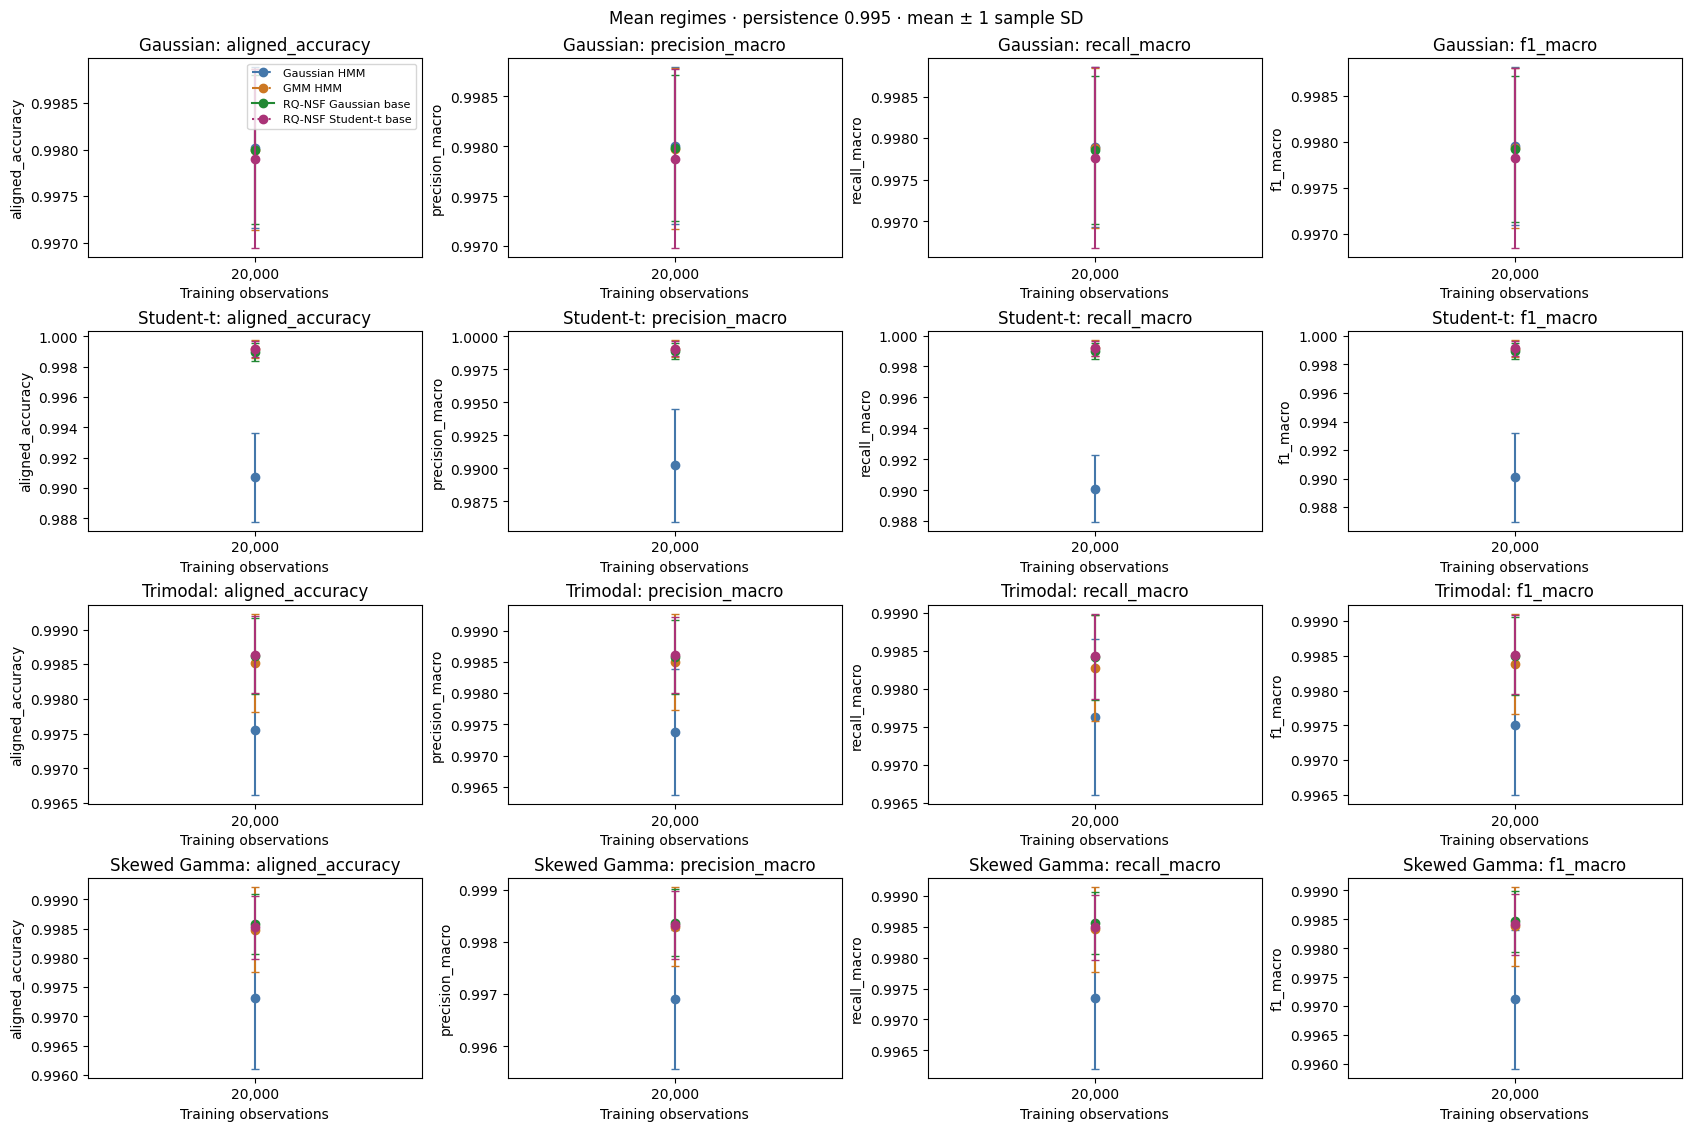

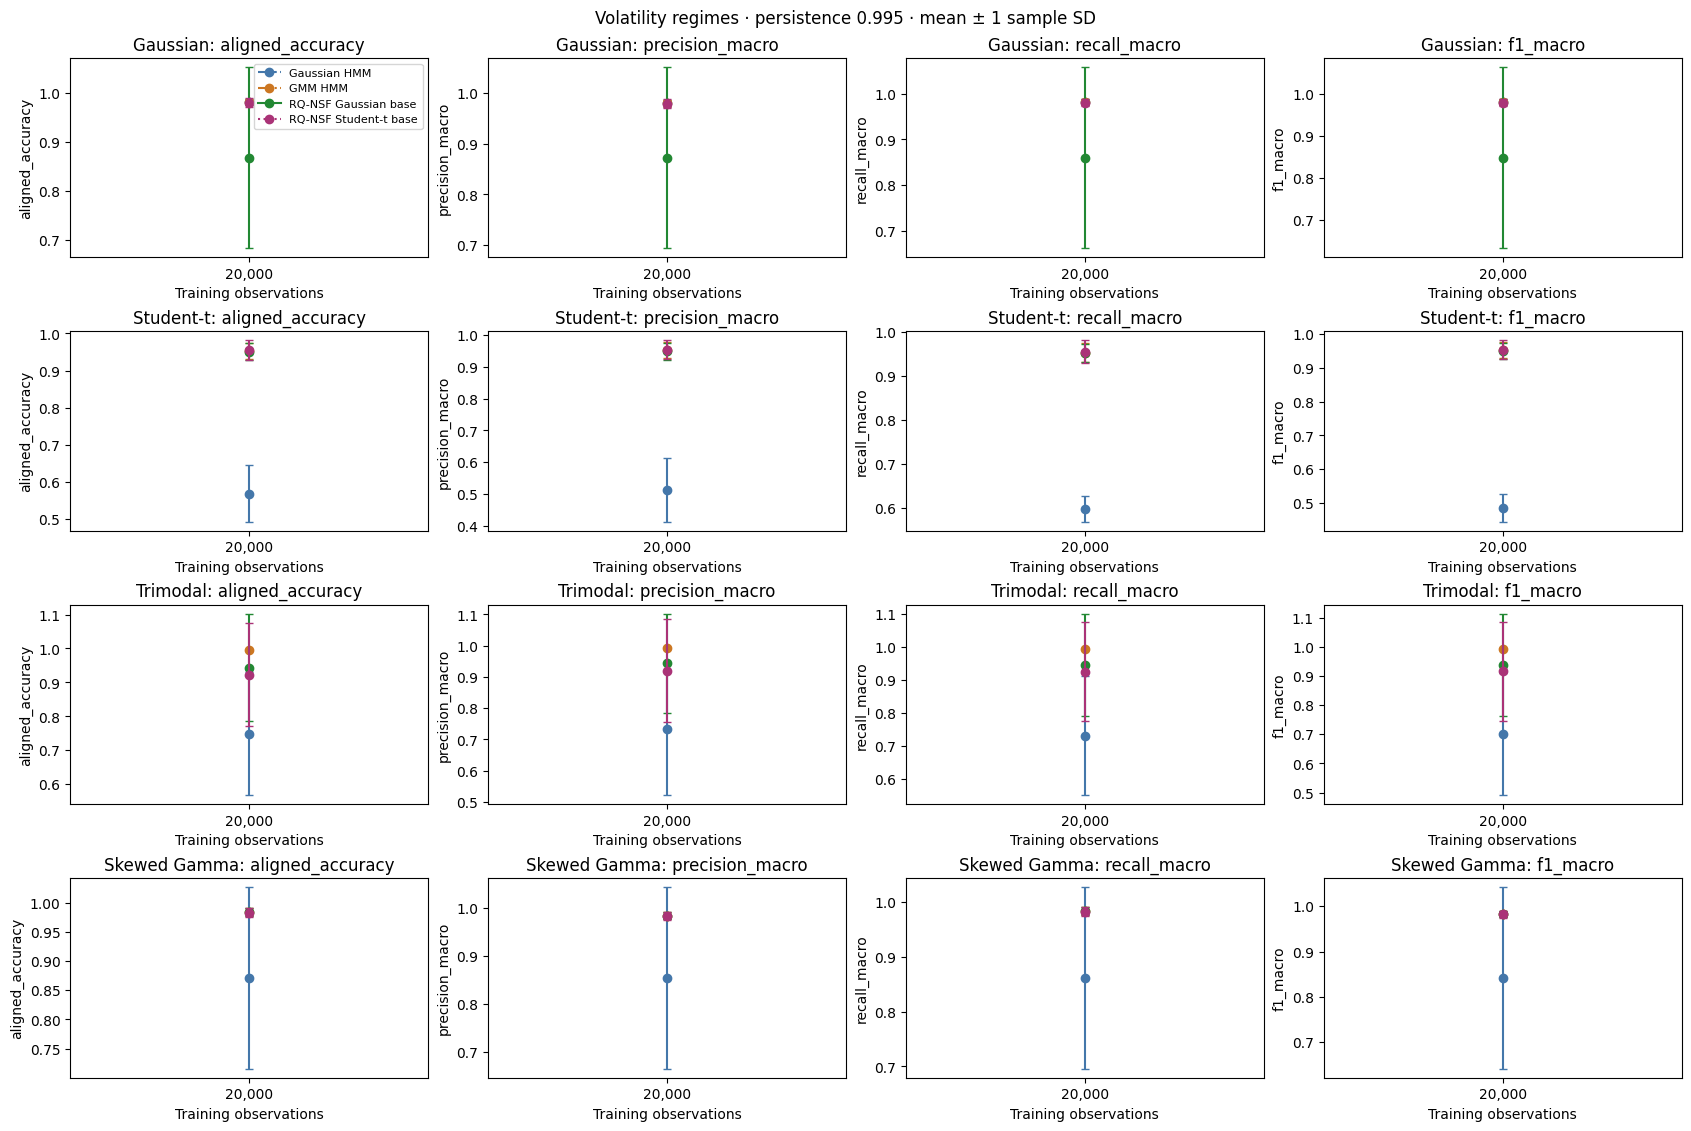

In [6]:
if report_ready and not clean.empty:
    for regime in sources:
        data = experiment.metric_groups(clean, [
            "aligned_accuracy", "precision_macro", "recall_macro", "f1_macro"
        ])
        if not data[data.regime == regime].empty:
            fig = experiment.plot_metrics(data, regime, [
                "aligned_accuracy", "precision_macro", "recall_macro", "f1_macro"
            ])
            show_and_save(fig, f"{regime}_classification_learning_curves")

## Density, probability, transition, and parameter recovery

Test NLL is the fitted model's sequence NLL per observation, compared only within
the same regime/family. Emission KL is $\mathrm{KL}(p_{\rm true}\|p_{\rm fitted})$
averaged equally across aligned states and targets the **clean** generating density.
It stays unchanged when only test measurement noise changes.

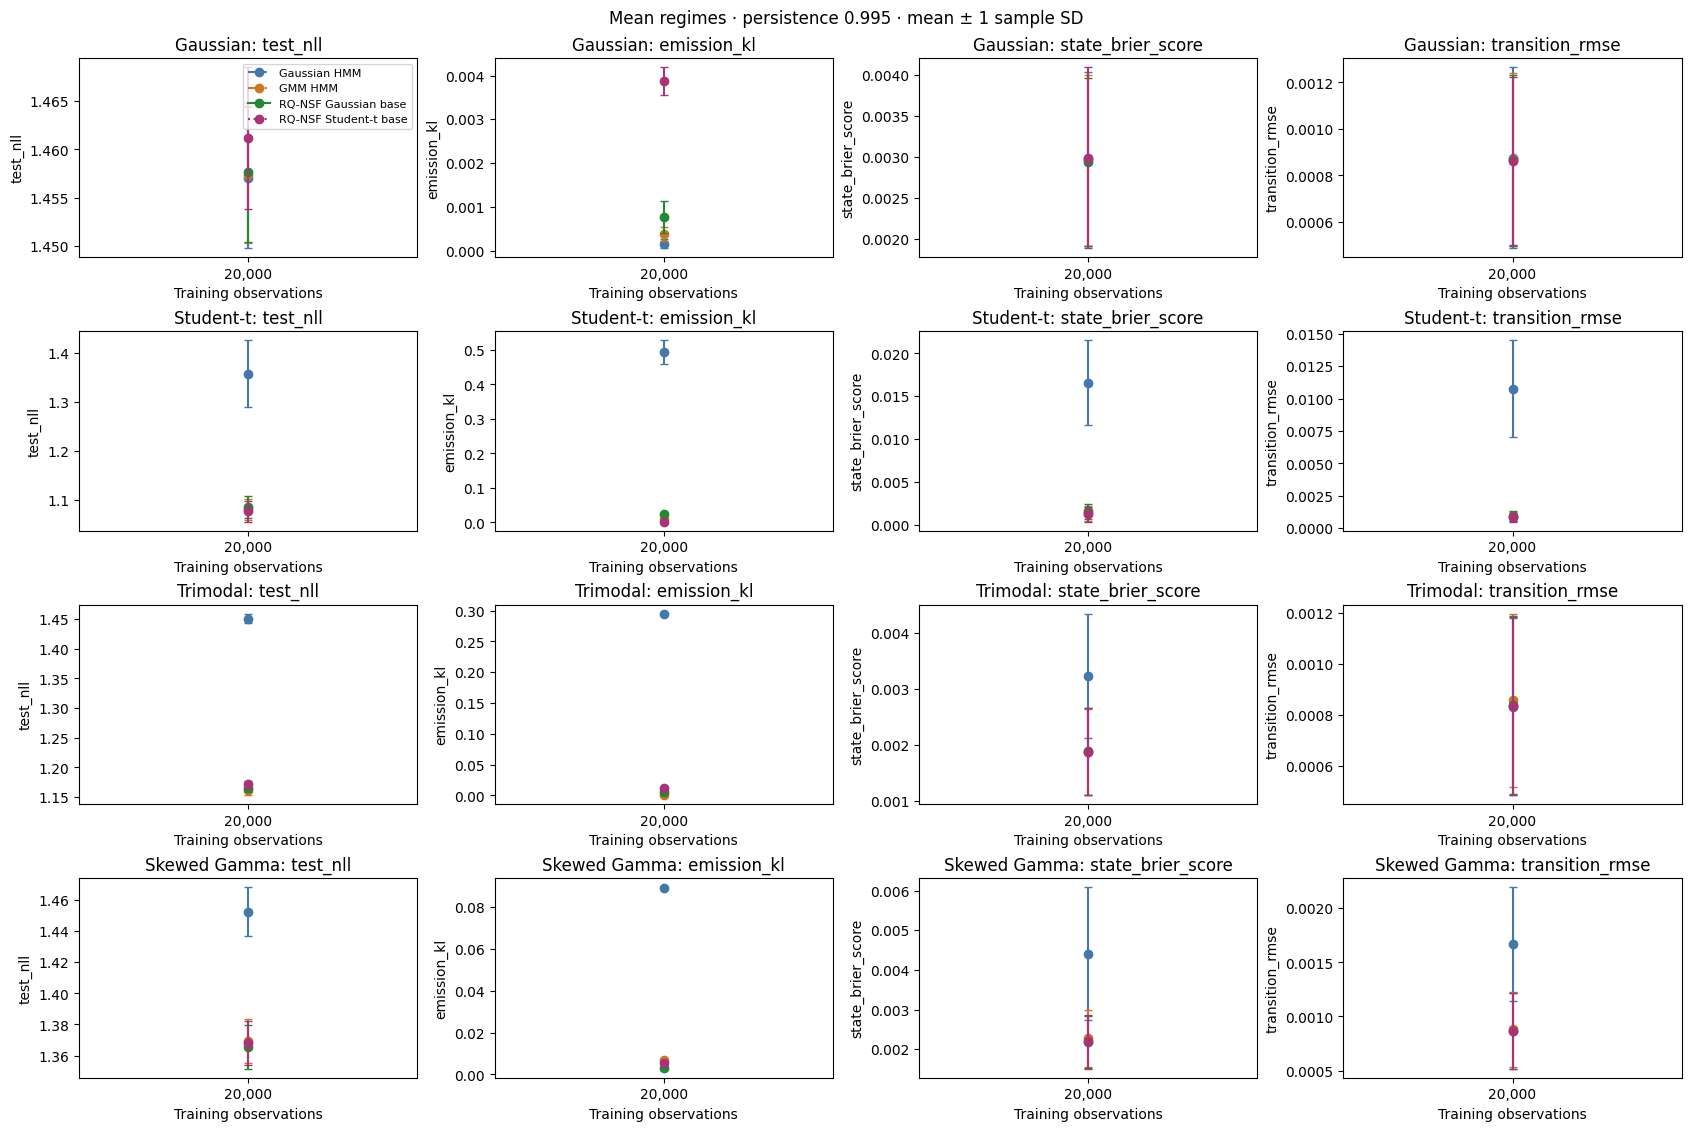

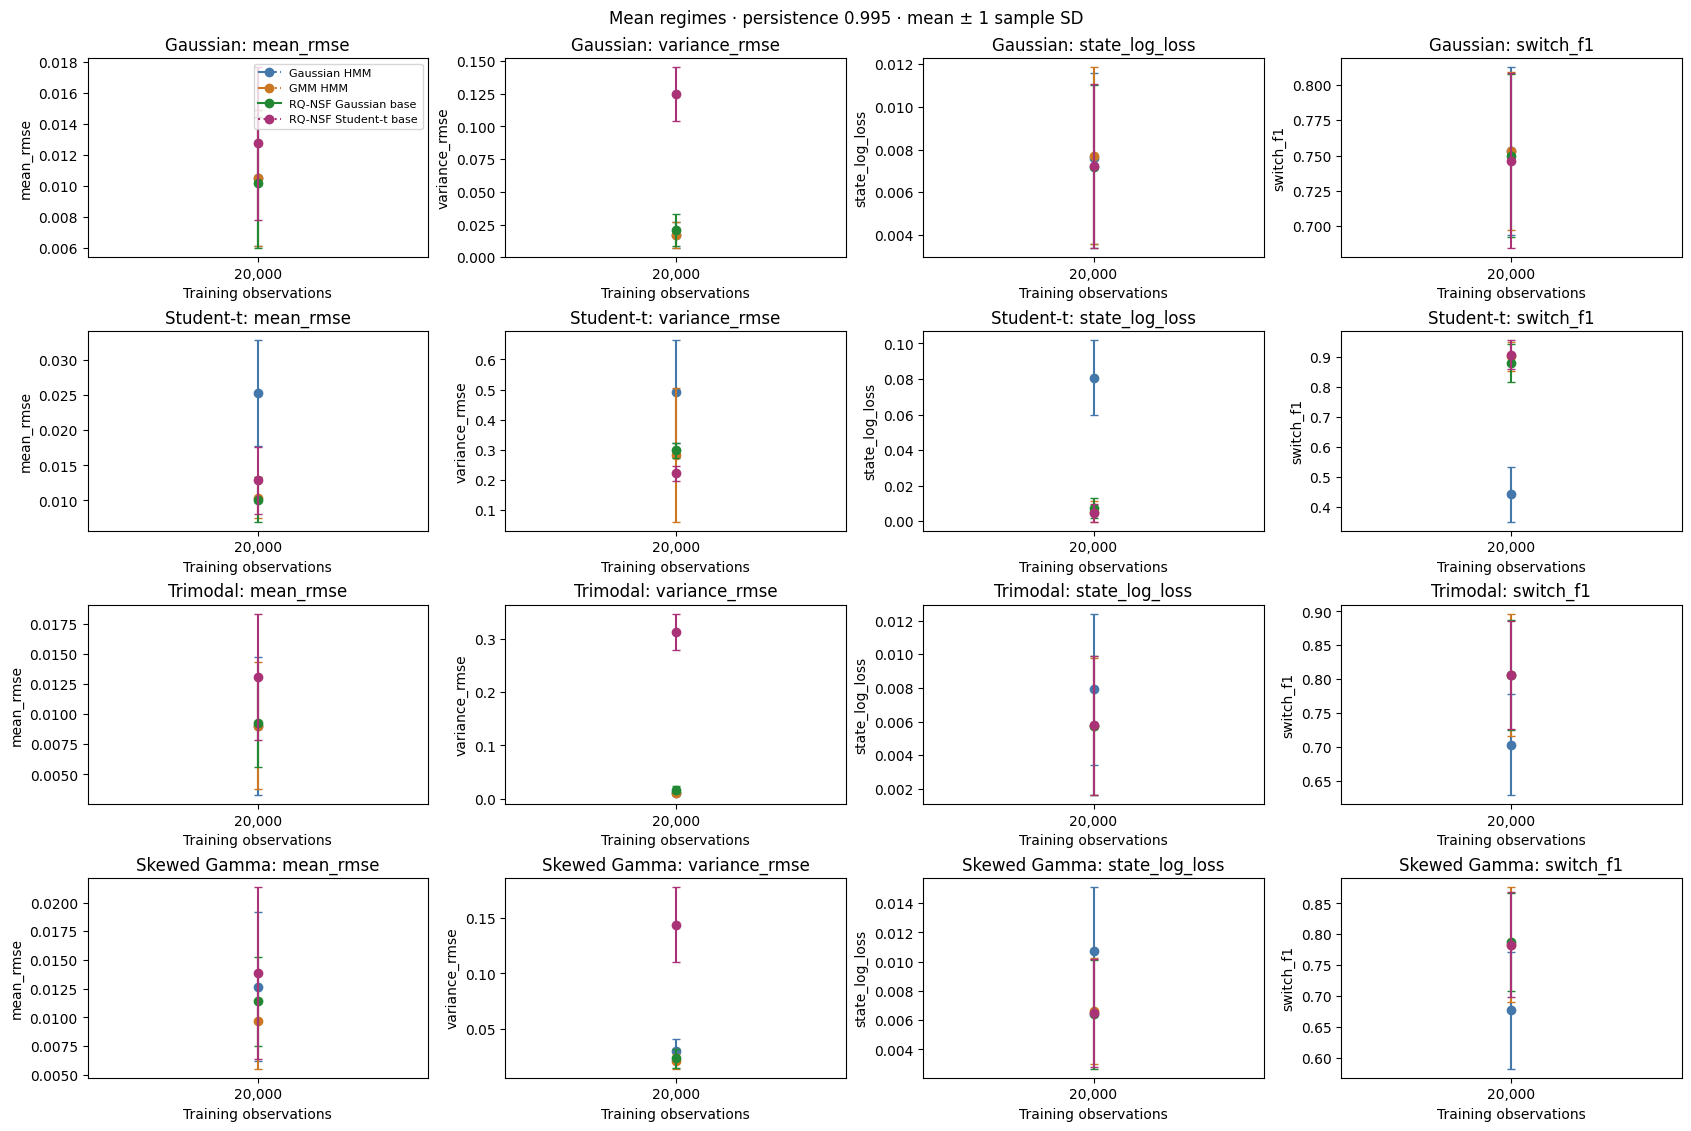

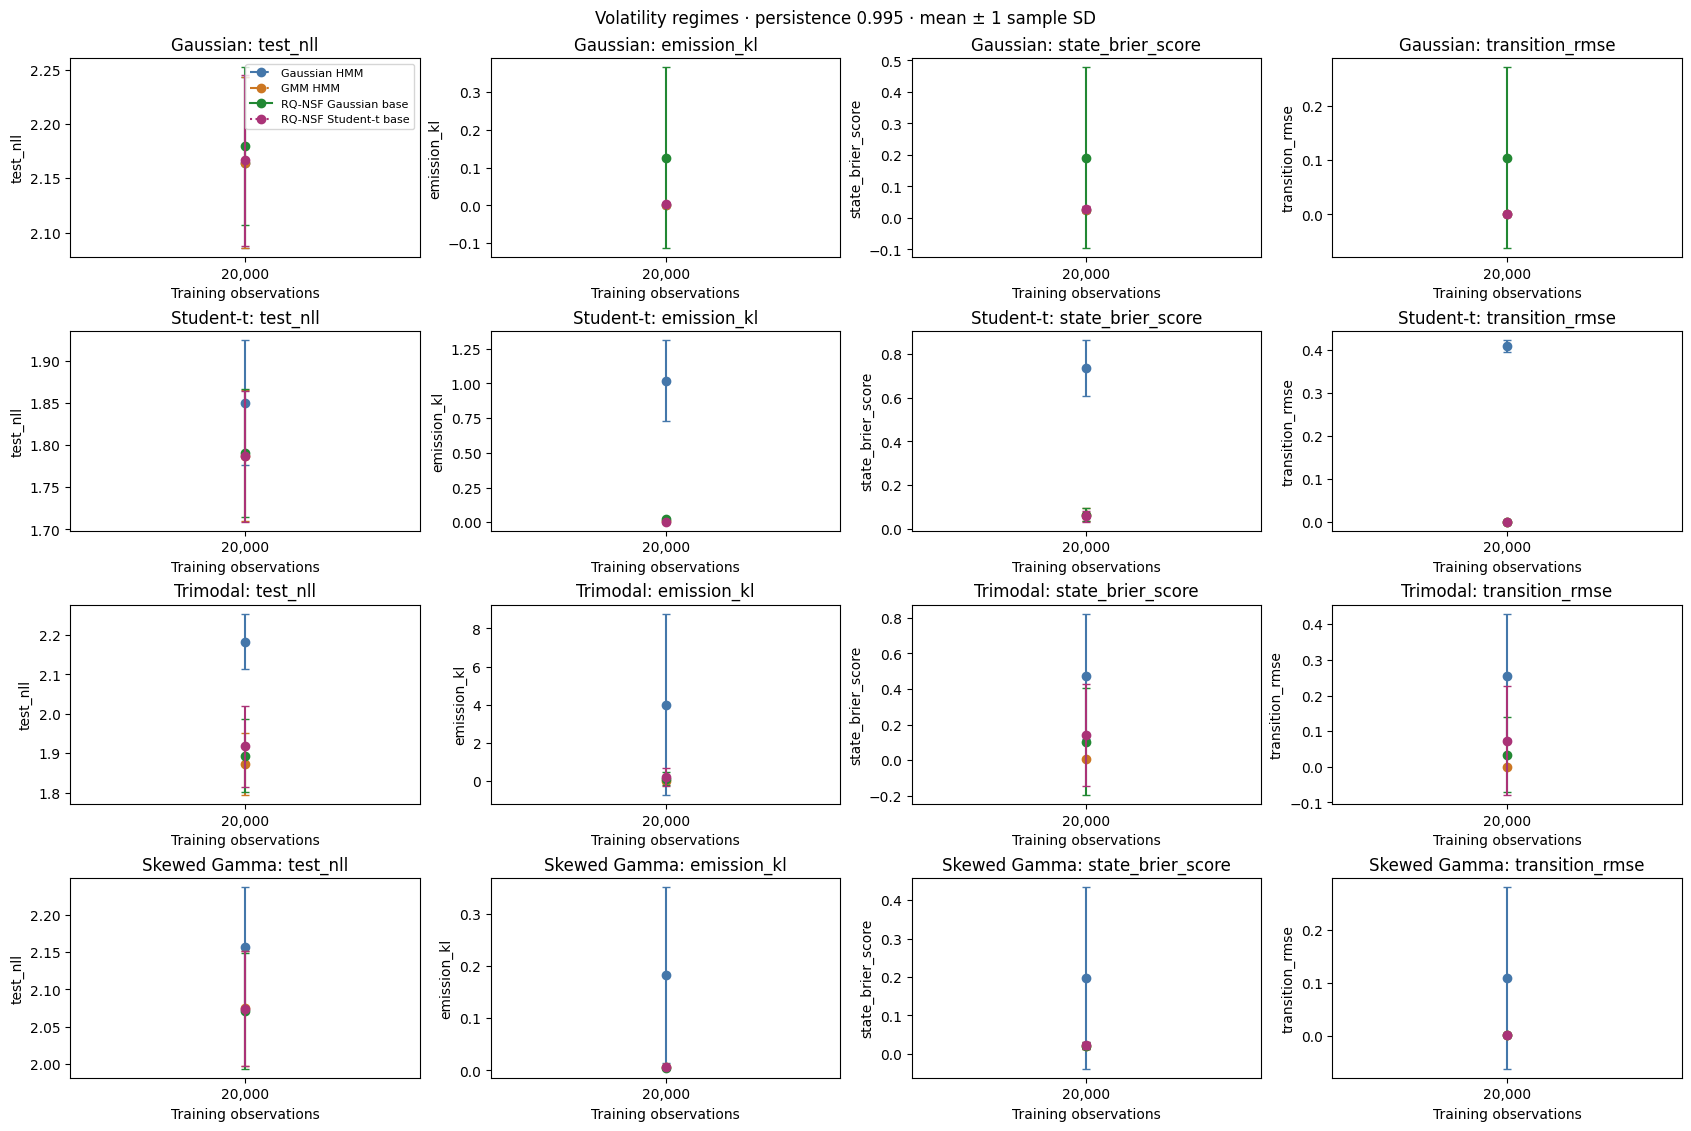

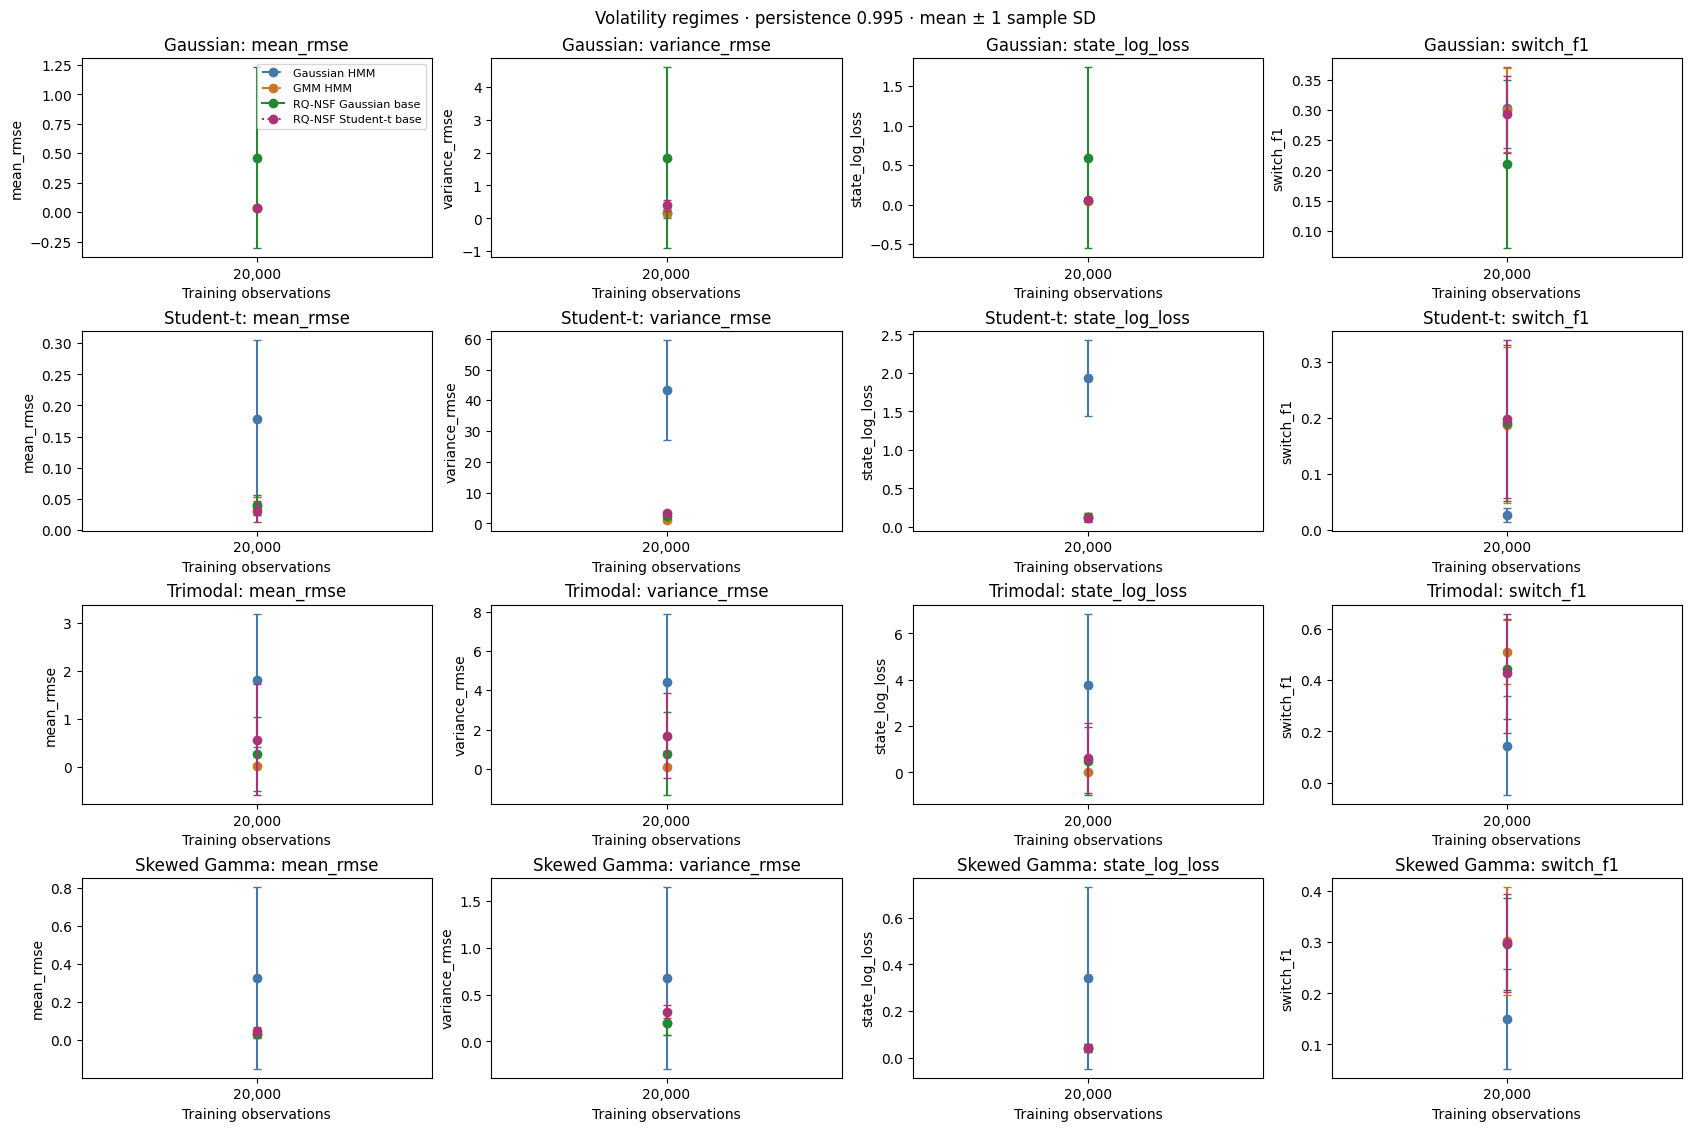

,regime,family,replicate,model,recovery_status,kl_quad_error_max,moment_quad_error_max,evaluation_warnings
0,mean,Gaussian,0,Gaussian HMM,NaN,7.328092e-10,NaN,[]
4,mean,Gaussian,0,GMM HMM,NaN,9.372105e-10,NaN,[]
8,mean,Gaussian,0,RQ-NSF Gaussian base,ok,2.014731e-09,5.684603e-10,[]
12,mean,Gaussian,0,RQ-NSF Student-t base,ok,1.988458e-09,6.161084e-10,[]
16,mean,Gaussian,1,Gaussian HMM,NaN,3.024968e-10,NaN,[]
...,...,...,...,...,...,...,...,...
1260,volatility,Skewed Gamma,8,RQ-NSF Student-t base,ok,3.736115e-09,1.856781e-09,[]
1264,volatility,Skewed Gamma,9,Gaussian HMM,NaN,5.180702e-10,NaN,[]
1268,volatility,Skewed Gamma,9,GMM HMM,NaN,8.679749e-10,NaN,[]
1272,volatility,Skewed Gamma,9,RQ-NSF Gaussian base,ok,2.220132e-09,1.618763e-09,[]


In [7]:
if report_ready and not clean.empty:
    for regime in sources:
        for label, metrics in [
            ("recovery", ["test_nll", "emission_kl", "state_brier_score", "transition_rmse"]),
            ("parameters", ["mean_rmse", "variance_rmse", "state_log_loss", "switch_f1"]),
        ]:
            data = experiment.metric_groups(clean, metrics)
            if not data[data.regime == regime].empty:
                show_and_save(experiment.plot_metrics(data, regime, metrics),
                              f"{regime}_{label}_learning_curves")
    diagnostic_columns = [c for c in [
        "regime", "family", "replicate", "model", "recovery_status",
        "kl_quad_error_max", "moment_quad_error_max", "evaluation_warnings"
    ] if c in results]
    display(results[results.condition == "clean"][diagnostic_columns])

## All six paired model differences

Subtract within a replicate before averaging. Intervals are 95% percentile
bootstrap intervals for the mean difference, resampling independent replicates
2,000 times.

Difference-plot abbreviations: NSF-N = Gaussian-base spline flow; NSF-t = Student-t-base spline flow.

,regime,family,n_train,condition,first,second,metric,n_pairs,mean_delta,ci_low,ci_high
0,mean,Gaussian,20000,clean,Gaussian HMM,GMM HMM,f1_macro,10,-0.000023,-0.000117,0.000053
1,mean,Gaussian,20000,clean,Gaussian HMM,GMM HMM,test_nll,10,0.000287,0.000045,0.000634
2,mean,Gaussian,20000,clean,Gaussian HMM,GMM HMM,emission_kl,10,0.000225,0.000155,0.000294
3,mean,Gaussian,20000,clean,Gaussian HMM,GMM HMM,total_fit_seconds,10,90.185232,70.980704,113.792919
4,mean,Gaussian,20000,clean,Gaussian HMM,RQ-NSF Gaussian base,f1_macro,10,-0.000030,-0.000147,0.000058
...,...,...,...,...,...,...,...,...,...,...,...
187,volatility,Trimodal,20000,clean,GMM HMM,RQ-NSF Student-t base,total_fit_seconds,10,58.968597,21.025655,100.170182
188,volatility,Trimodal,20000,clean,RQ-NSF Gaussian base,RQ-NSF Student-t base,f1_macro,10,-0.022168,-0.172455,0.136167
189,volatility,Trimodal,20000,clean,RQ-NSF Gaussian base,RQ-NSF Student-t base,test_nll,10,0.023704,-0.025906,0.075153
190,volatility,Trimodal,20000,clean,RQ-NSF Gaussian base,RQ-NSF Student-t base,emission_kl,10,0.103009,-0.264947,0.506012


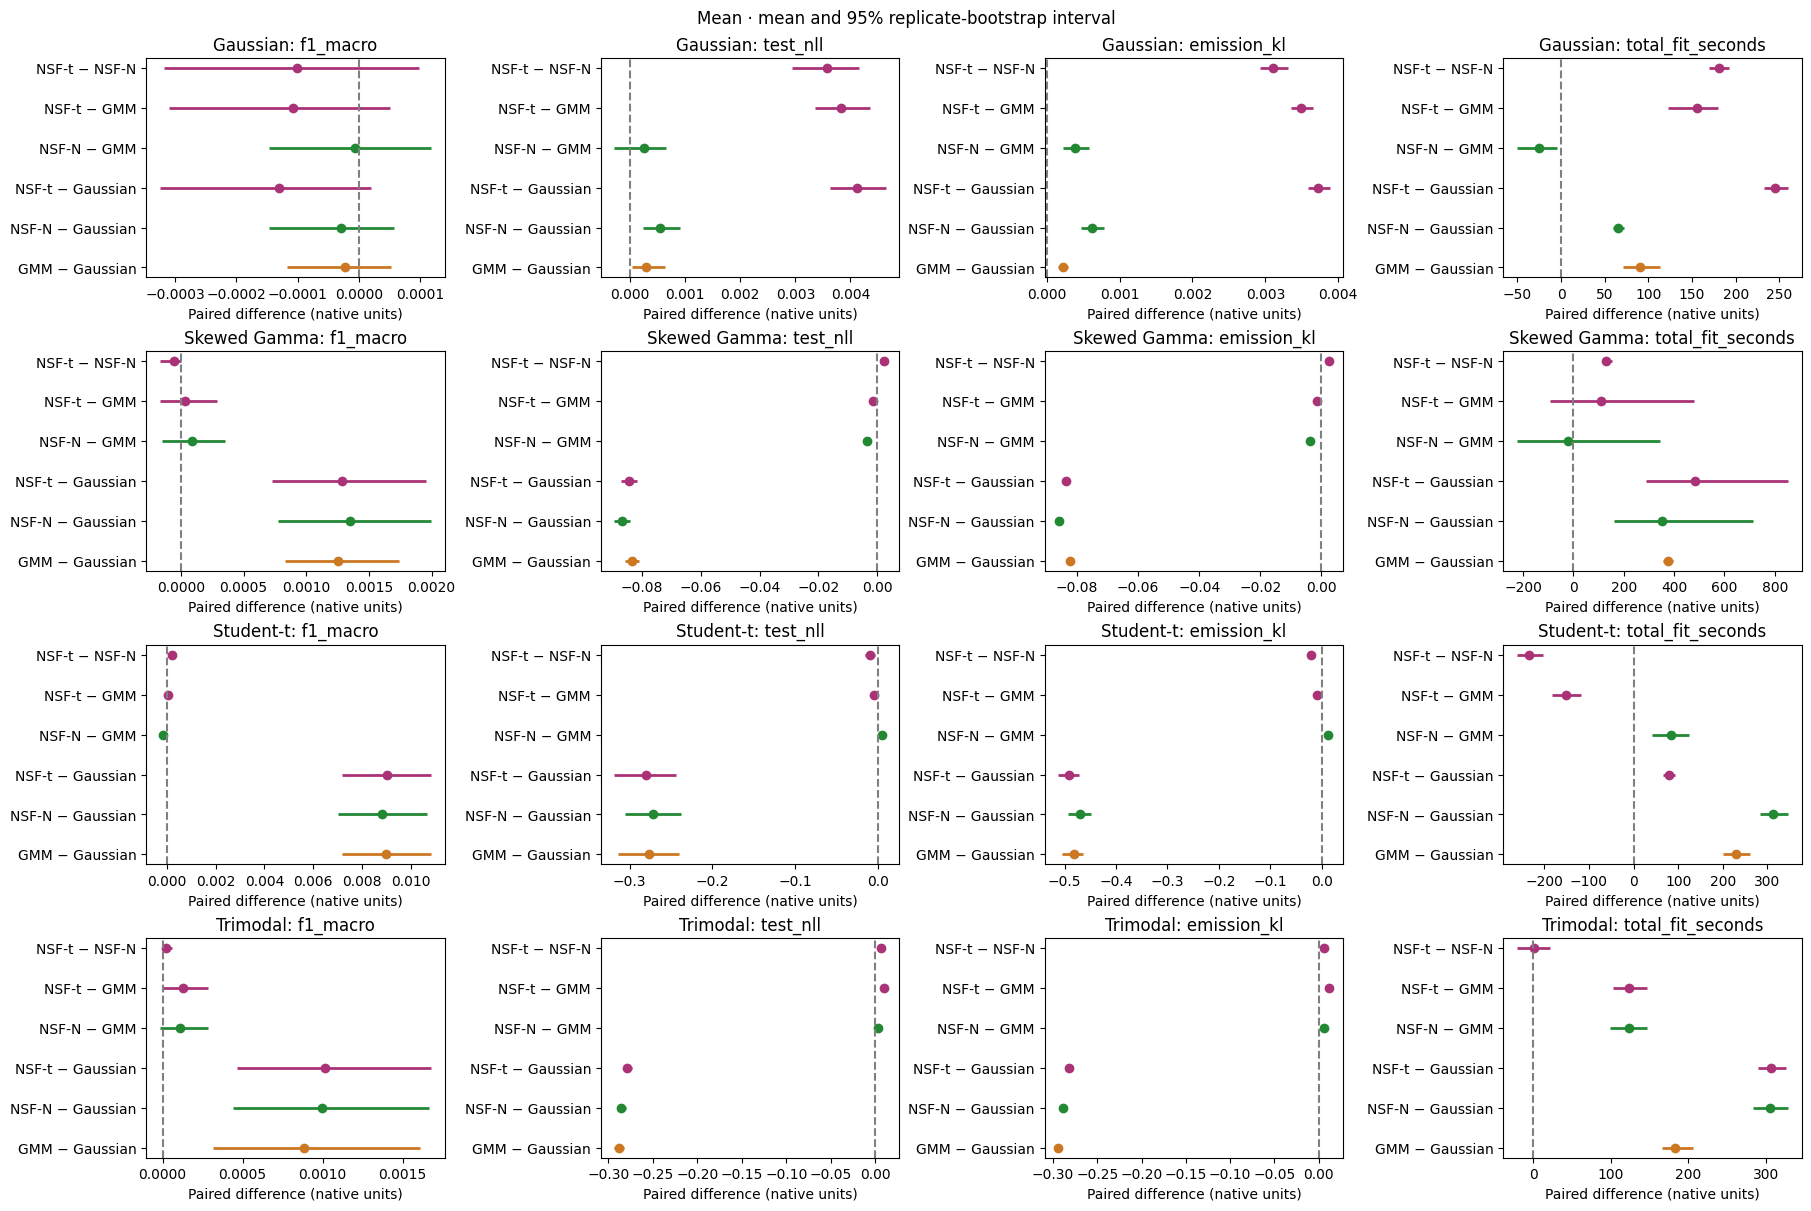

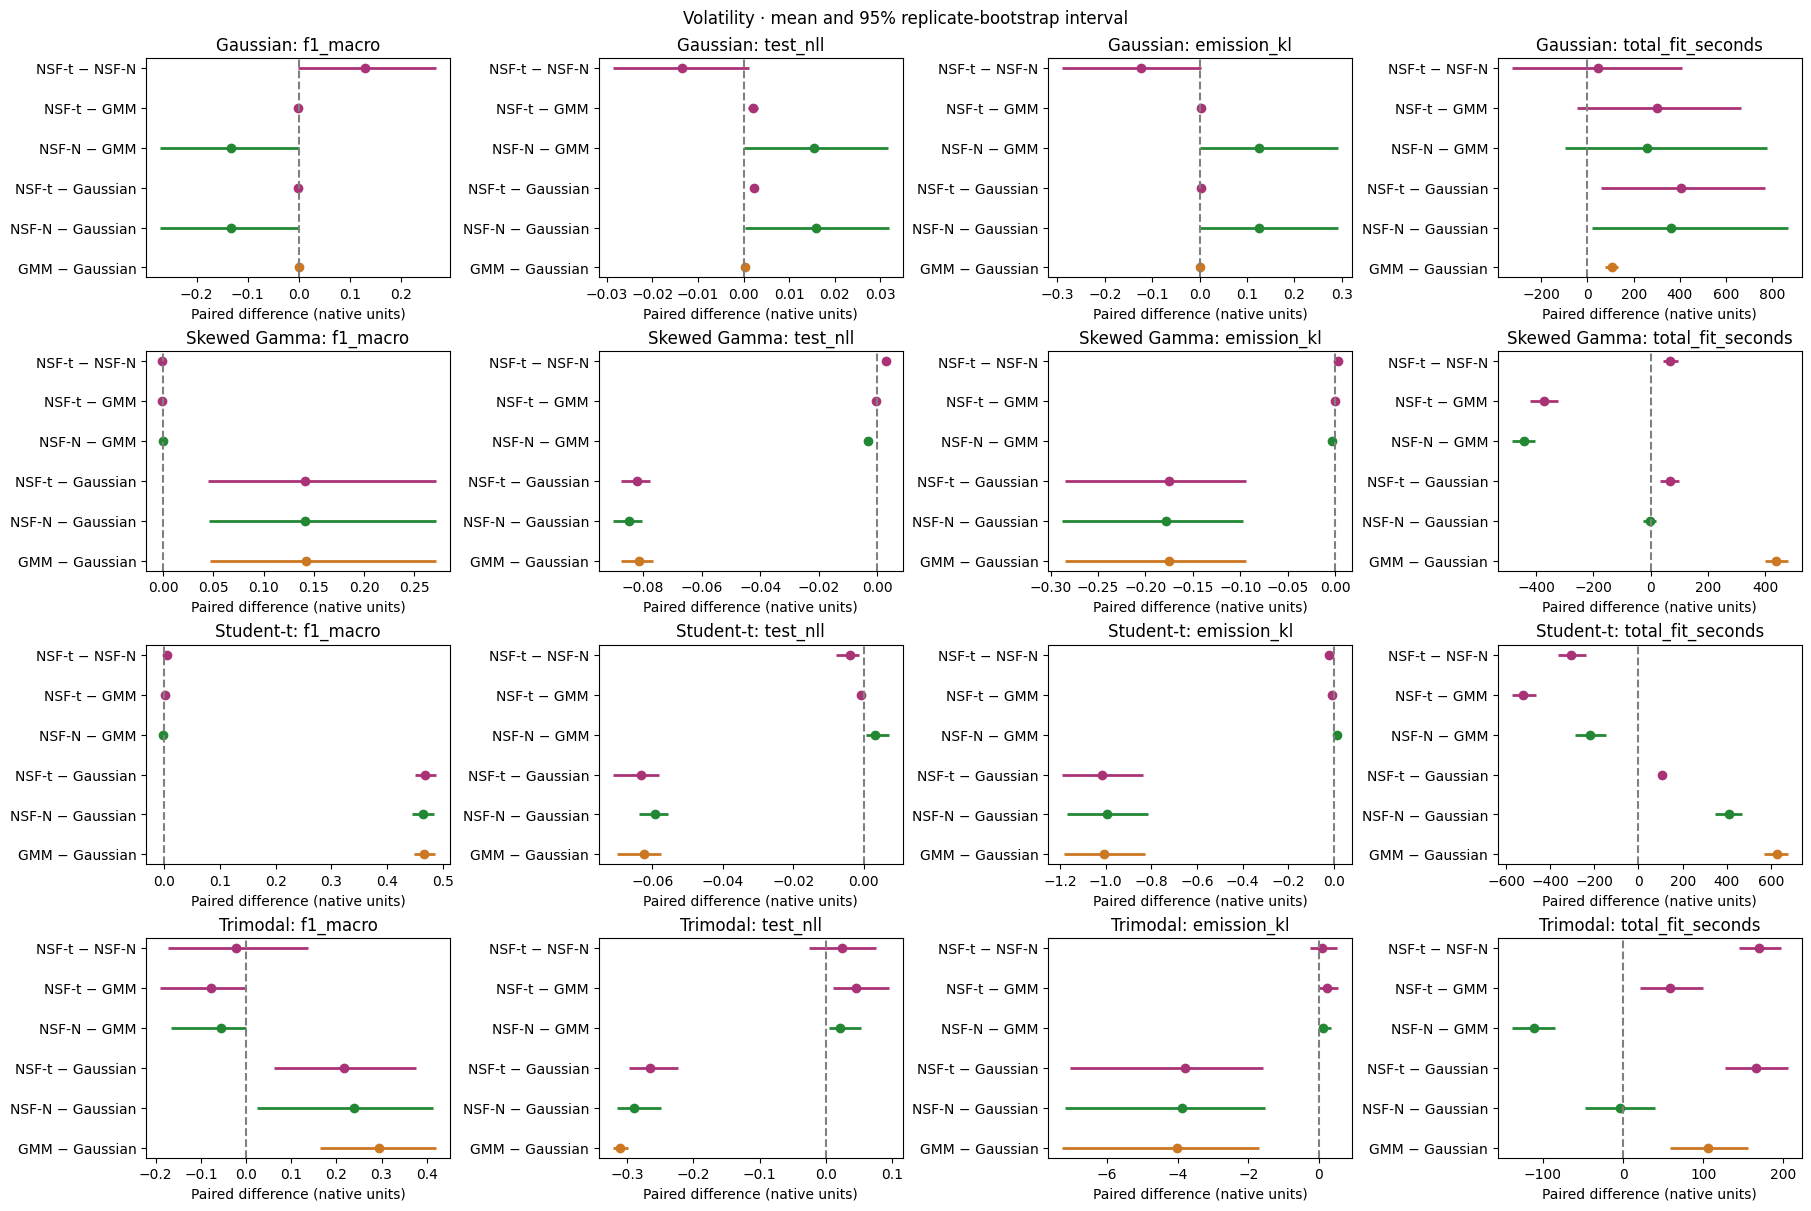

In [8]:
if report_ready and not clean.empty:
    delta_metrics = ["f1_macro", "test_nll", "emission_kl", "total_fit_seconds"]
    deltas = experiment.paired_differences(clean, delta_metrics)
    deltas.to_csv(run_dir / "paired_model_differences.csv", index=False)
    display(deltas)
    for regime in sources:
        if not deltas[deltas.regime == regime].empty:
            show_and_save(experiment.plot_differences(deltas, regime, delta_metrics),
                          f"{regime}_paired_model_differences")

## Confusion matrices and per-state classification

Each matrix pools the same complete four-model replicate groups. Rows are true
states, columns are aligned predicted states. Tiles show counts and row percentages
on a common 0–100% color scale. Per-state precision/recall/F1 use the same groups.

precision            \
                                                             mean       std   
regime     family   n_train model                 state                       
mean       Gaussian 20000   GMM HMM               0      0.997598  0.001959   
                                                  1      0.997798  0.001219   
                                                  2      0.998535  0.001121   
                            Gaussian HMM          0      0.997676  0.001797   
                                                  1      0.997756  0.001239   
...                                                           ...       ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  1      0.940506  0.163847   
                                                  2      0.997593  0.002414   
                            RQ-NSF Student-t base 0      0.943843  0.141946   
                                                  1      0.846314  0.332028   
                                                  2      0.967215  0.097386   

                                                           recall            \
                                                             mean       std   
regime     family   n_train model                 state                       
mean       Gaussian 20000   GMM HMM               0      0.998375  0.002064   
                                                  1      0.997059  0.001901   
                                                  2      0.998204  0.001275   
                            Gaussian HMM          0      0.998489  0.002124   
                                                  1      0.996992  0.001822   
...                                                           ...       ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  1      0.994515  0.004358   
                                                  2      0.943844  0.149263   
                            RQ-NSF Student-t base 0      0.996791  0.002600   
                                                  1      0.876458  0.313752   
                                                  2      0.900532  0.207191   

                                                               f1            \
                                                             mean       std   
regime     family   n_train model                 state                       
mean       Gaussian 20000   GMM HMM               0      0.997986  0.001726   
                                                  1      0.997427  0.001086   
                                                  2      0.998369  0.000919   
                            Gaussian HMM          0      0.998081  0.001703   
                                                  1      0.997372  0.001066   
...                                                           ...       ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  1      0.958134  0.110574   
                                                  2      0.963099  0.098248   
                            RQ-NSF Student-t base 0      0.963461  0.092198   
                                                  1      0.858394  0.322153   
                                                  2      0.926570  0.166355   

                                                        support              
                                                           mean         std  
regime     family   n_train model                 state                      
mean       Gaussian 20000   GMM HMM               0      1791.9  430.944557  
                                                  1      1753.3  424.968247  
                                                  2      1454.8  376.900458  
                            Gaussian HMM          0      1791.9  430.944557  
                                                  1      1753.3  424.968247  
...                                                         ...         ...  
volatility Trimodal 20000   RQ-NS

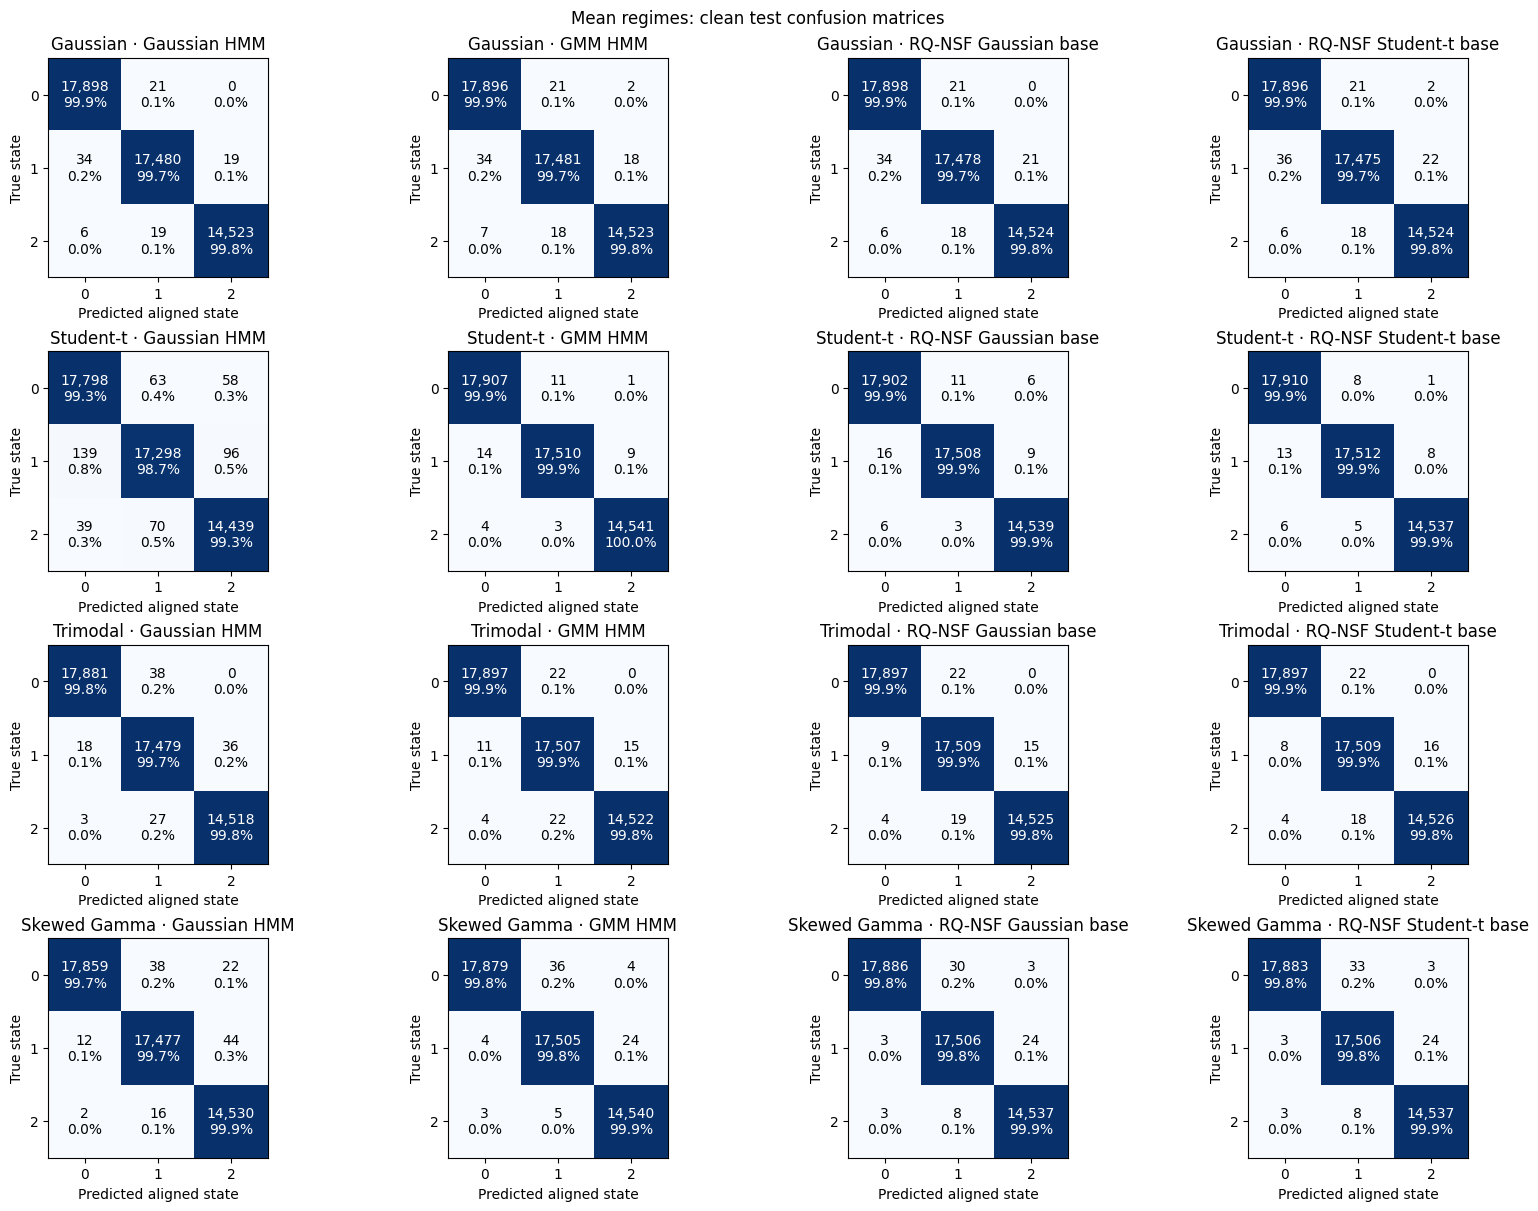

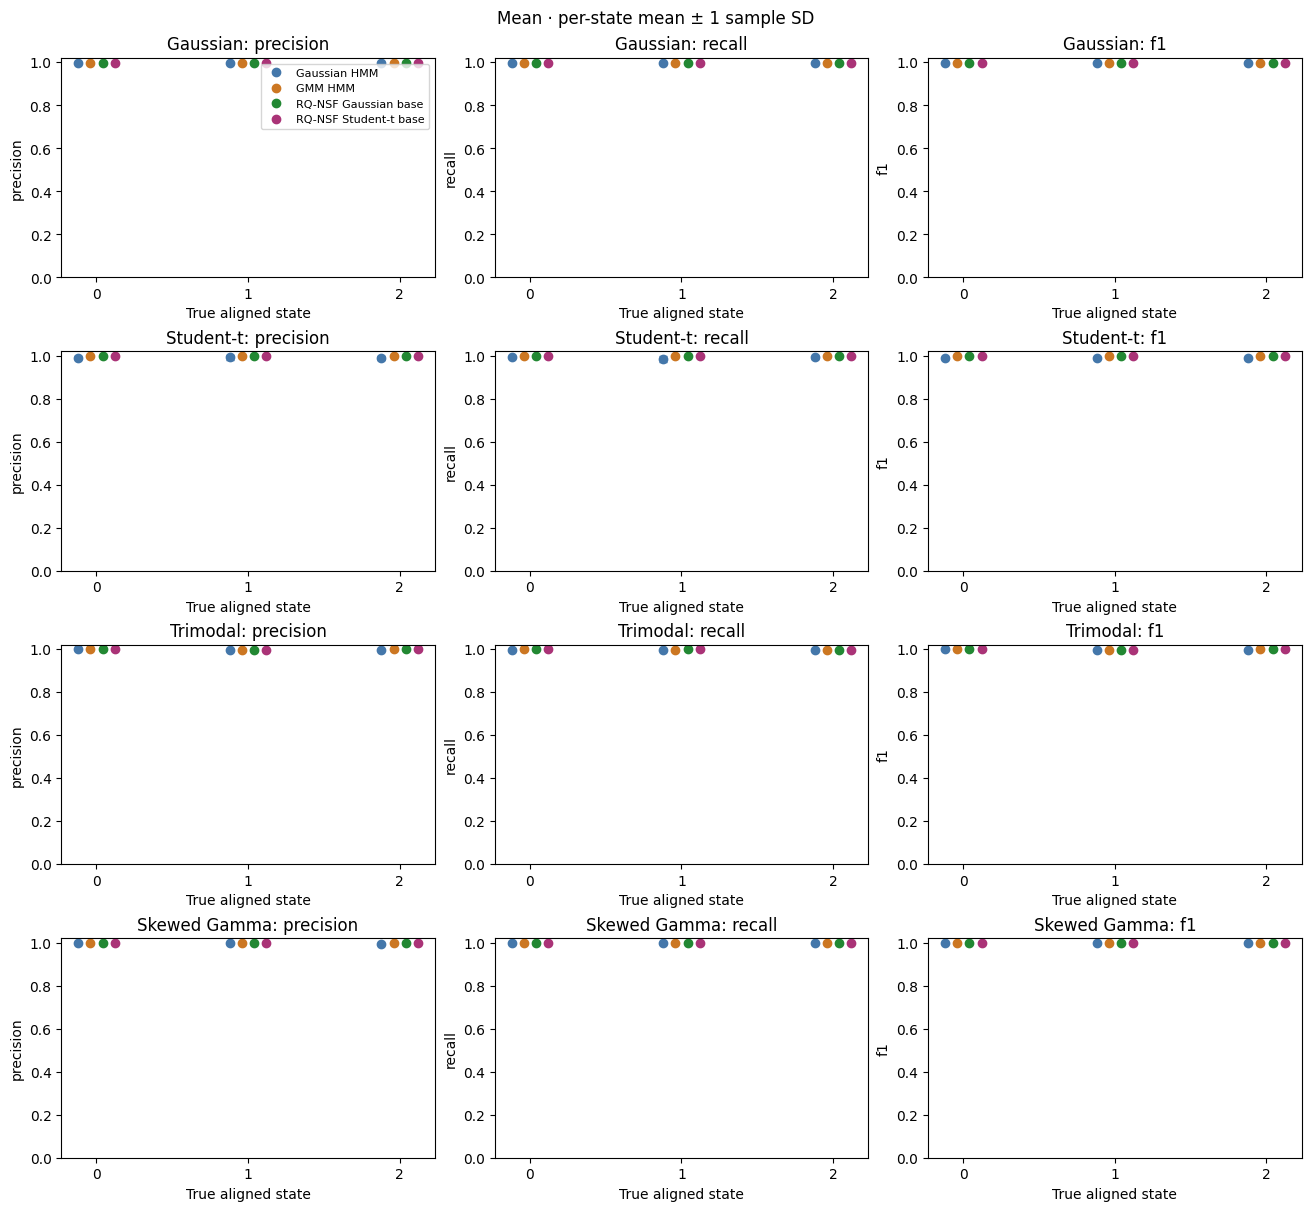

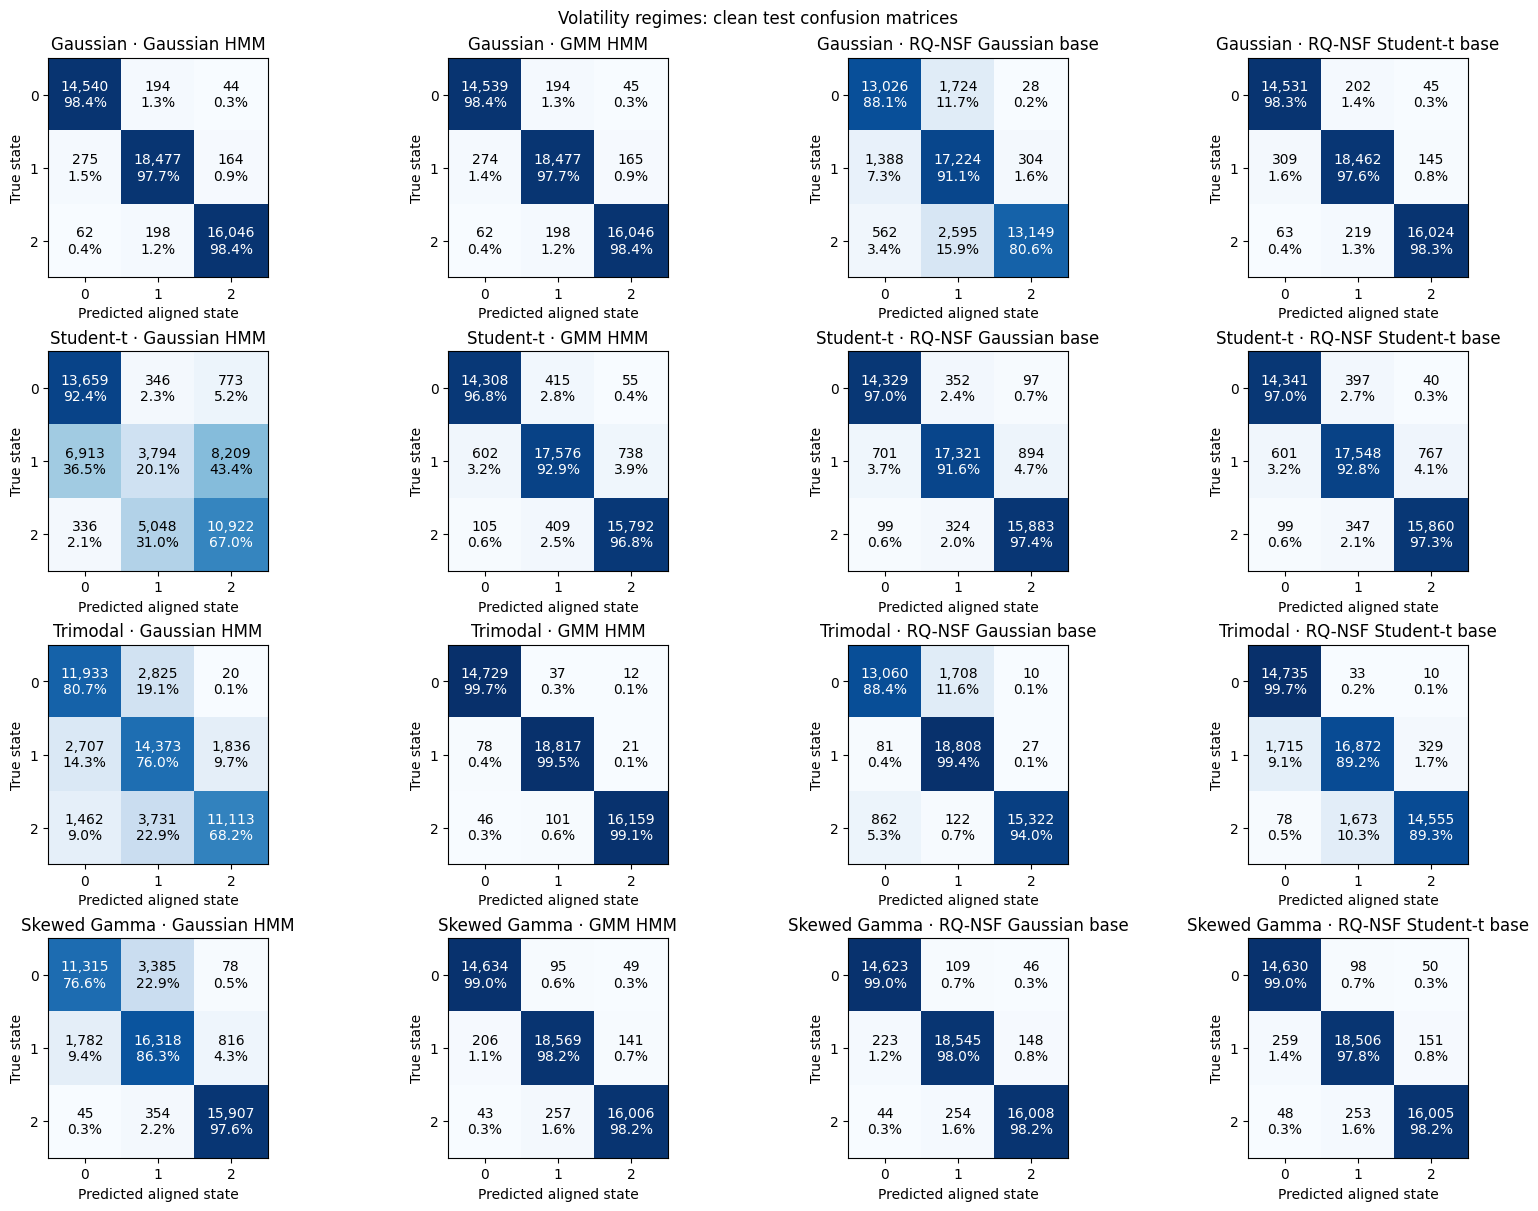

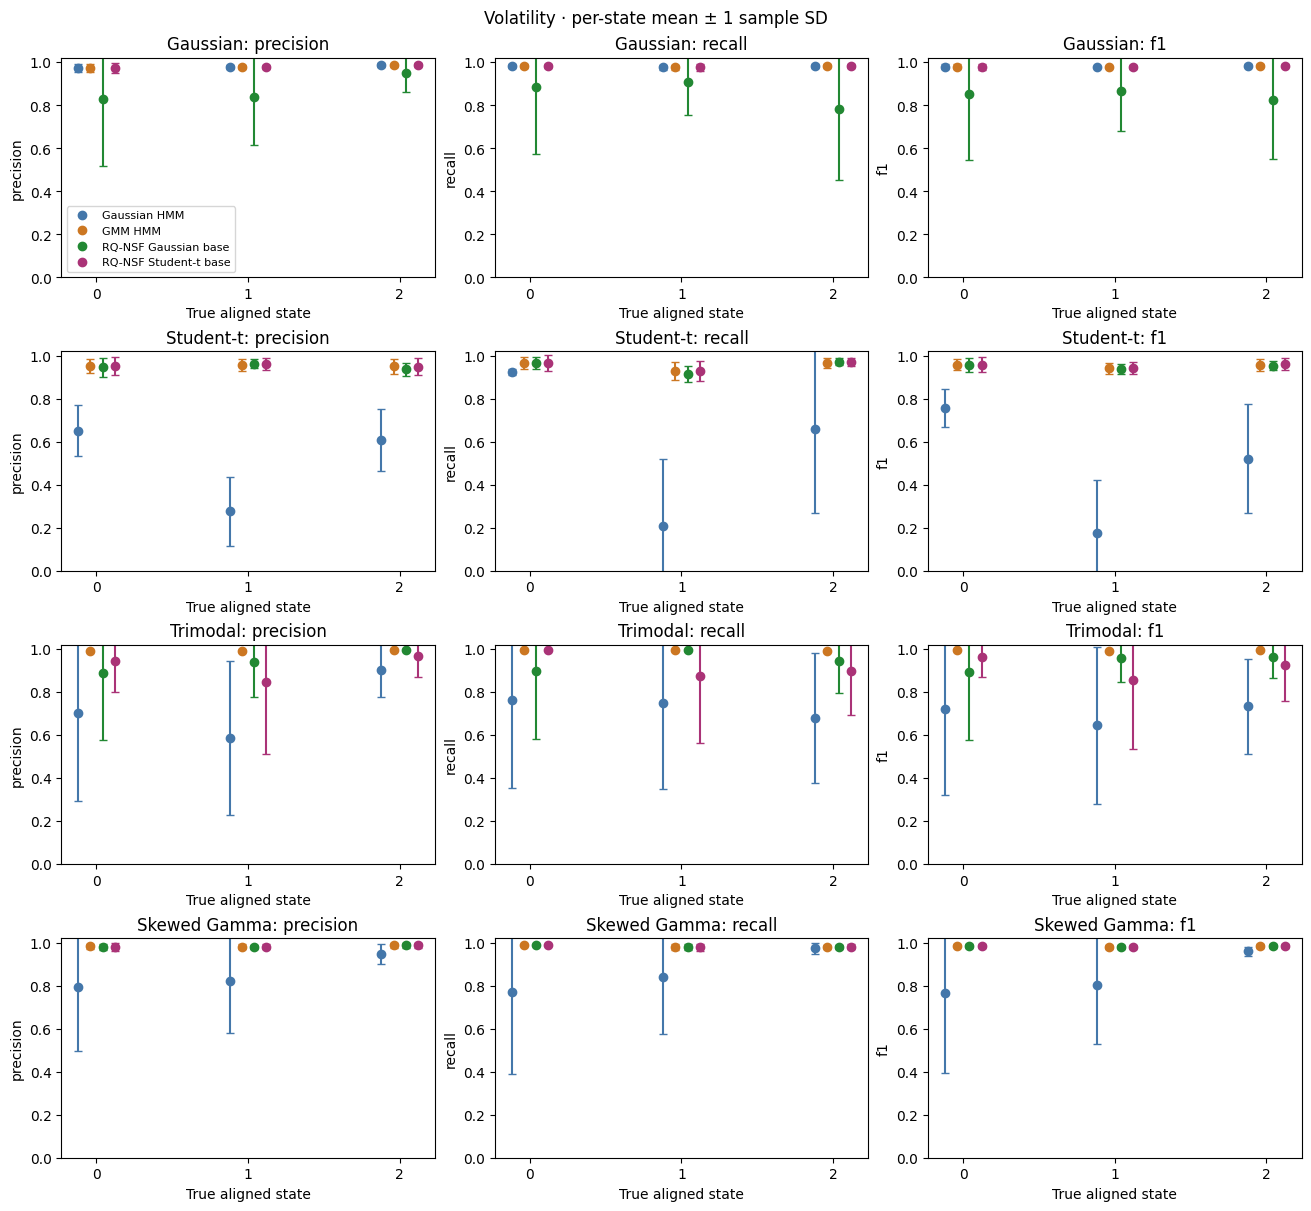

In [9]:
if report_ready and not clean.empty:
    keys = experiment.KEYS + ["model", "condition"]
    state_rows = run["per_state"].merge(clean[keys], on=keys, validate="many_to_one")
    state_summary = state_rows.groupby([
        "regime", "family", "n_train", "model", "state"
    ])[["precision", "recall", "f1", "support"]].agg(["mean", "std"])
    state_summary.to_csv(run_dir / "per_state_summary.csv")
    display(state_summary)
    for regime in sources:
        if not clean[clean.regime == regime].empty:
            show_and_save(experiment.plot_confusions(run["confusion"], clean, regime),
                          f"{regime}_confusion_matrices")
            show_and_save(experiment.plot_per_state(run["per_state"], clean, regime),
                          f"{regime}_per_state_classification")

## True and fitted emission densities

Always show replicate 0 at the largest saved training size, rather than selecting
the best test outcome. The density window is ±5 true standard deviations around
each state's mean.

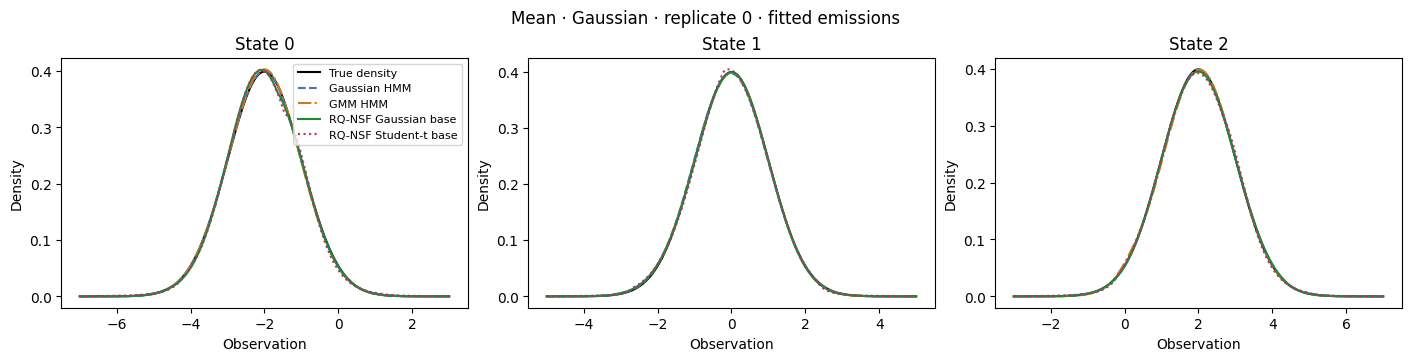

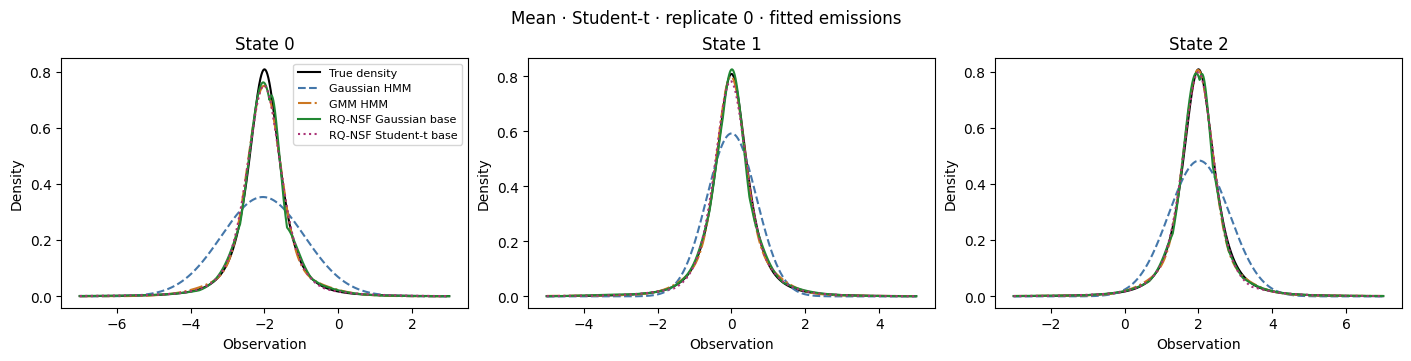

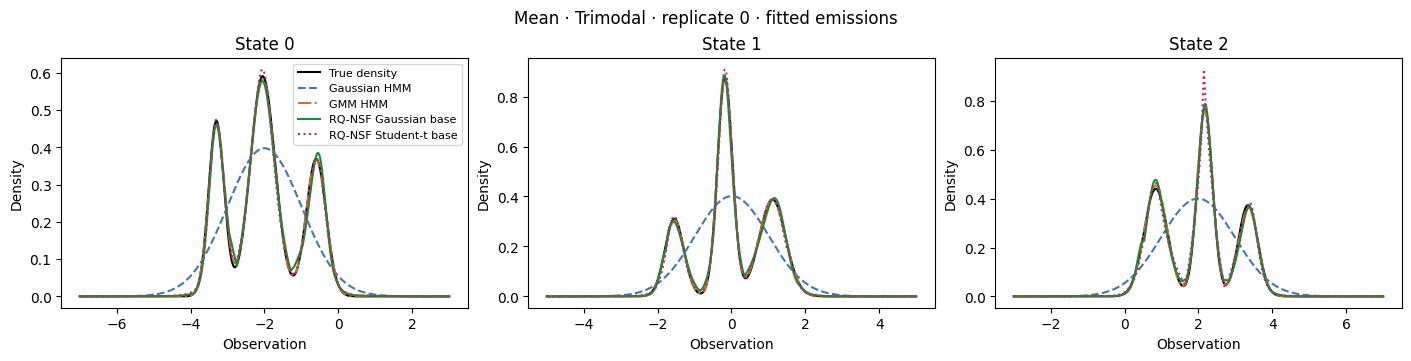

Model is not converging.  Current: -27312.53527668524 is not greater than -27312.535276669973. Delta is -1.526859705336392e-08
Model is not converging.  Current: -27310.065306751854 is not greater than -27310.0653067338. Delta is -1.805528881959617e-08
Model is not converging.  Current: -27307.678173850953 is not greater than -27307.67817383461. Delta is -1.6341800801455975e-08


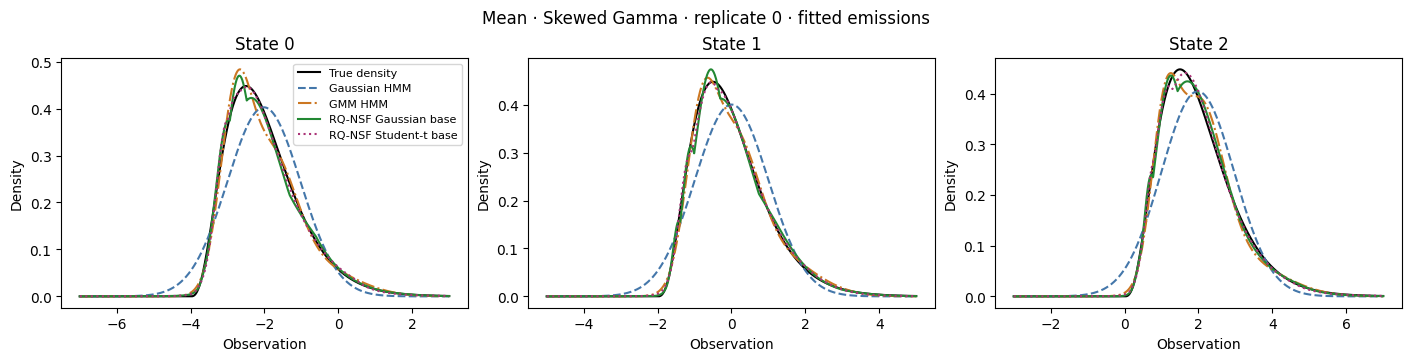

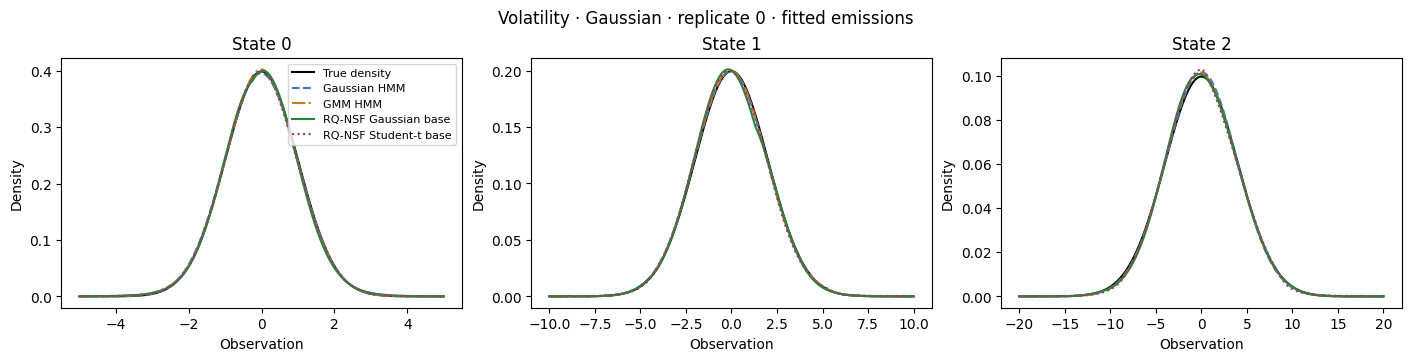

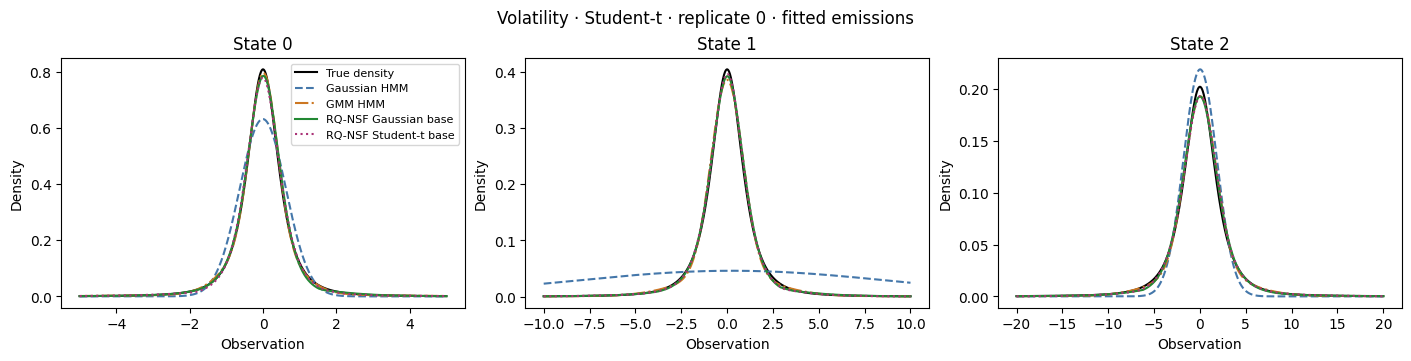

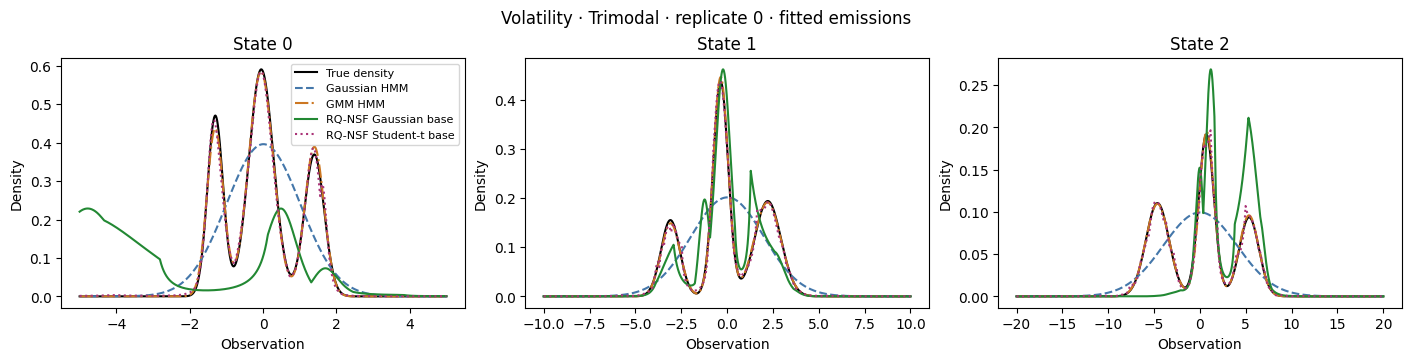

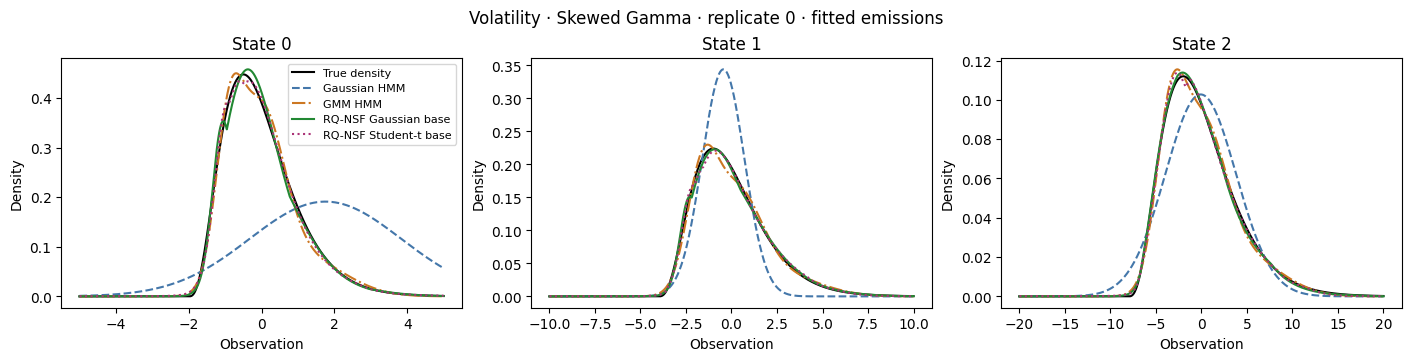

In [10]:
if report_ready:
    for regime, source in sources.items():
        for family in source.families:
            eligible = clean[(clean.regime == regime) & (clean.family == family)
                             & (clean.replicate == 0)]
            if not eligible.empty:
                show_and_save(experiment.plot_emissions(source, run_dir, family),
                              f"{regime}_{family}_fitted_emissions")

## True and fitted flow emission densities

Compare the true density with both fitted flow densities for the replicate set by `EMISSION_DENSITY_REPLICATE` in the next cell. The same setting selects the saved models and identifies the output files. 

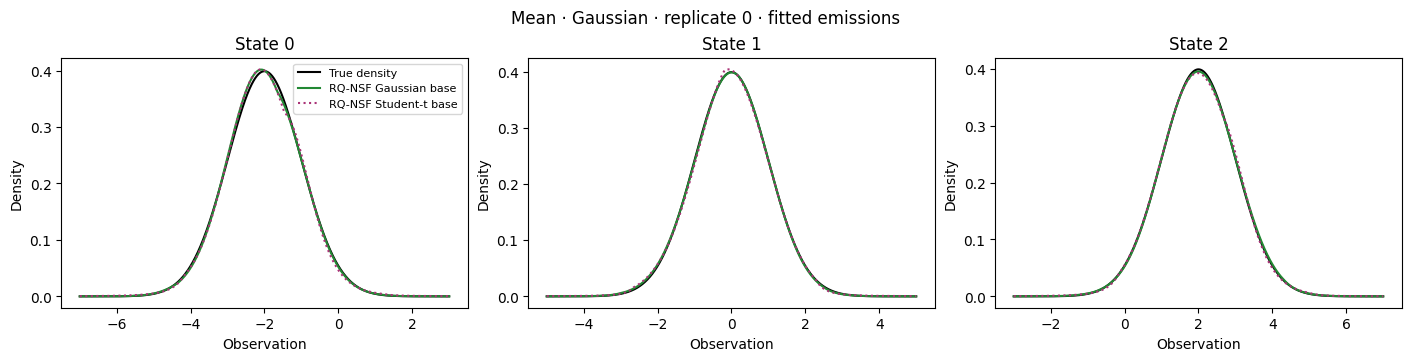

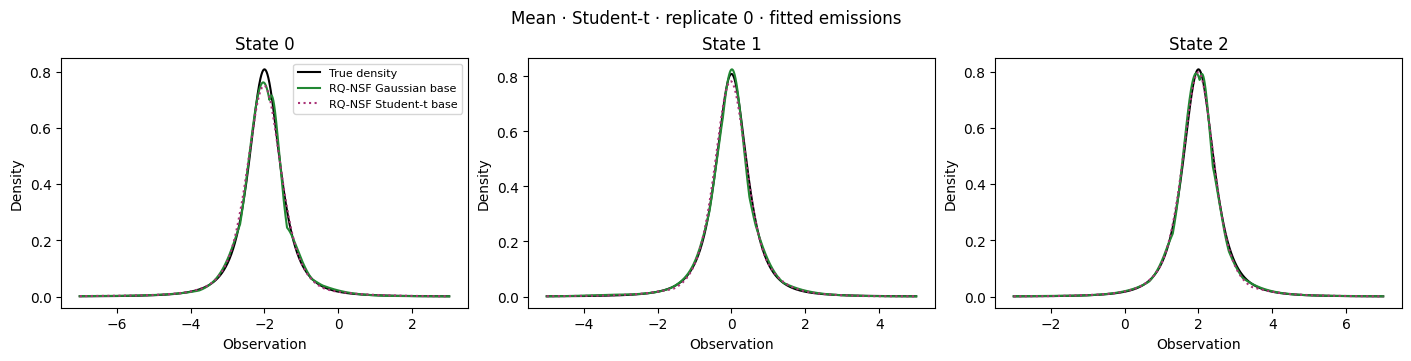

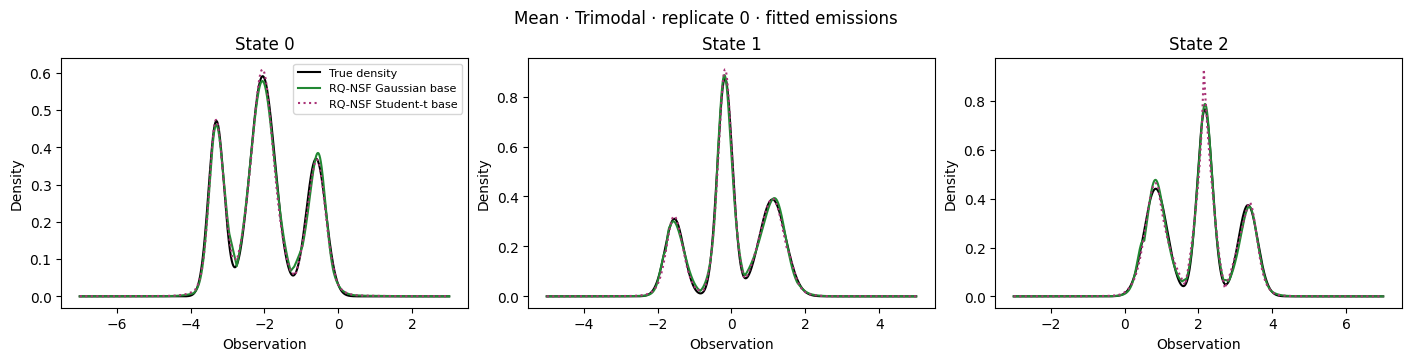

Model is not converging.  Current: -27312.53527668524 is not greater than -27312.535276669973. Delta is -1.526859705336392e-08
Model is not converging.  Current: -27310.065306751854 is not greater than -27310.0653067338. Delta is -1.805528881959617e-08
Model is not converging.  Current: -27307.678173850953 is not greater than -27307.67817383461. Delta is -1.6341800801455975e-08


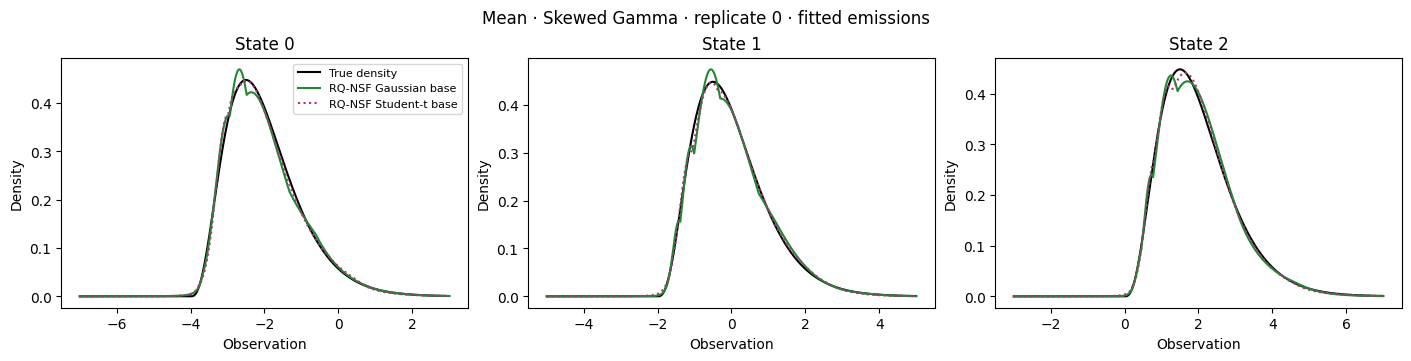

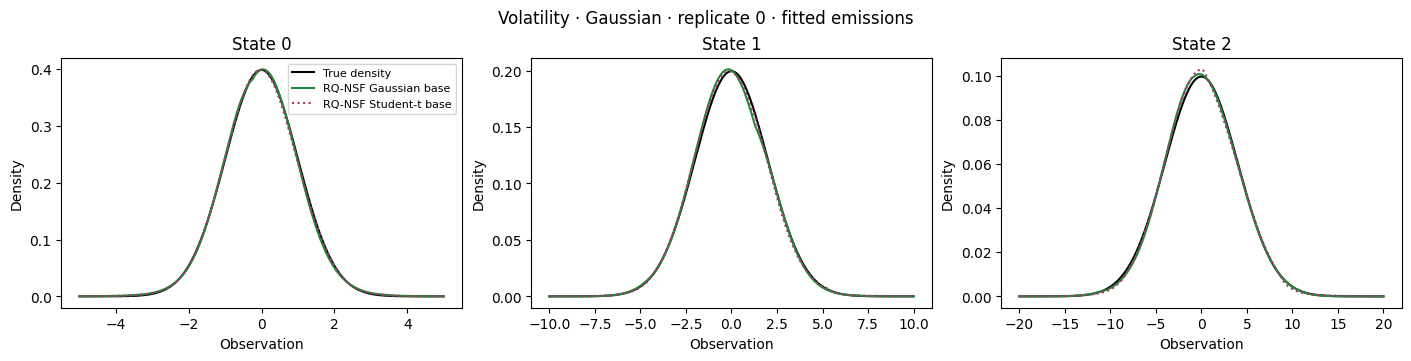

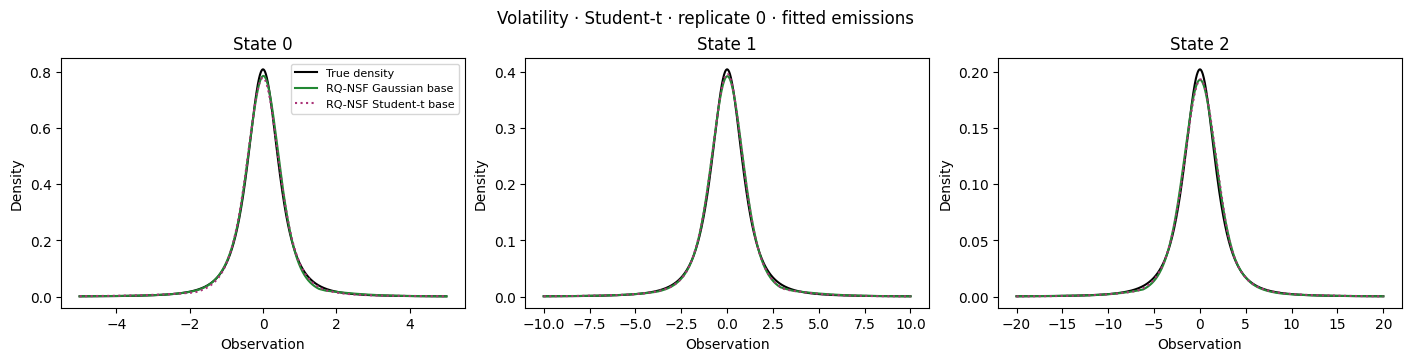

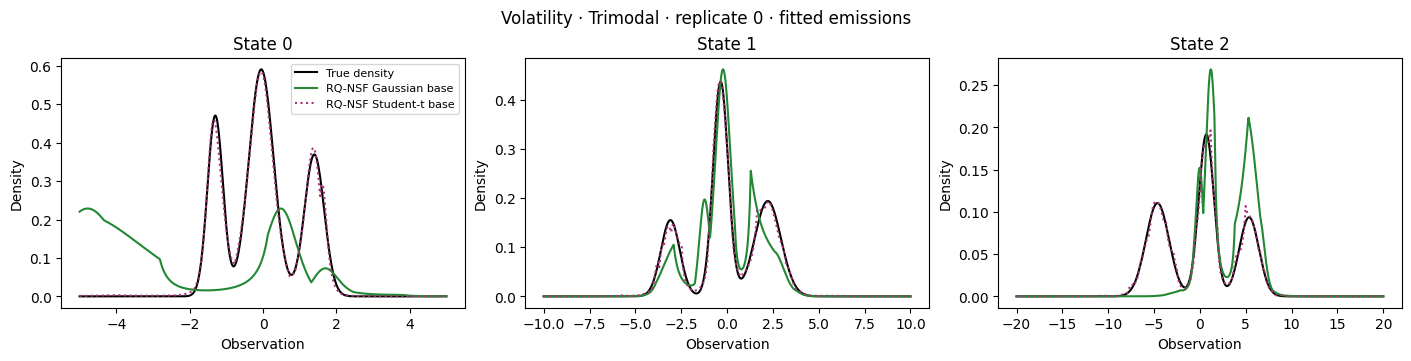

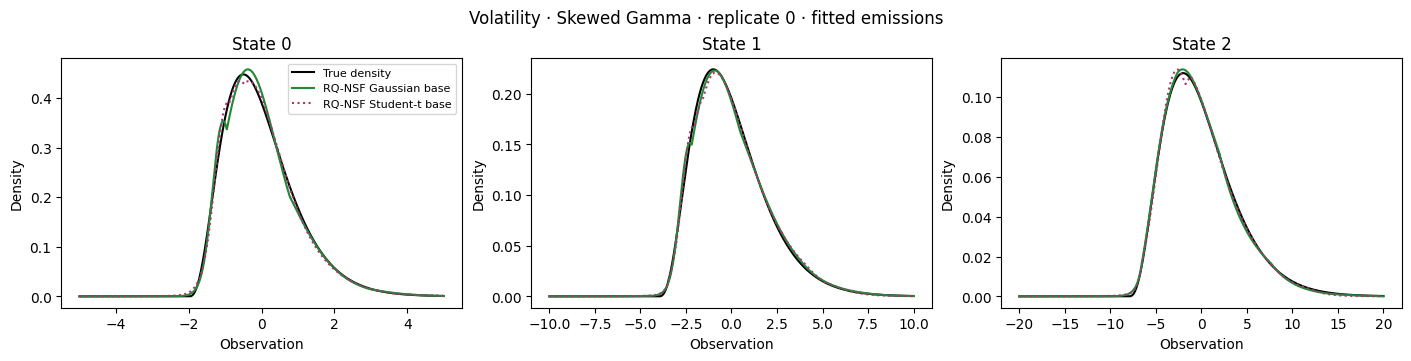

In [30]:
import importlib

experiment = importlib.reload(experiment)
EMISSION_DENSITY_REPLICATE = 0

if report_ready:
    for regime, source in sources.items():
        for family in source.families:
            eligible = clean[(clean.regime == regime)
                             & (clean.family == family)
                             & (clean.replicate == EMISSION_DENSITY_REPLICATE)]
            if not eligible.empty:
                fig = experiment.plot_emissions(
                    source, run_dir, family, flow_only=True,
                    replicate=EMISSION_DENSITY_REPLICATE,
                )
                show_and_save(
                    fig,
                    f"{regime}_{family}_replicate_{EMISSION_DENSITY_REPLICATE}"
                    "_fitted_flow_emissions",
                )


## Decoded state paths
Families: "Gaussian", "Student-t", "Trimodal", "Skewed Gamma"

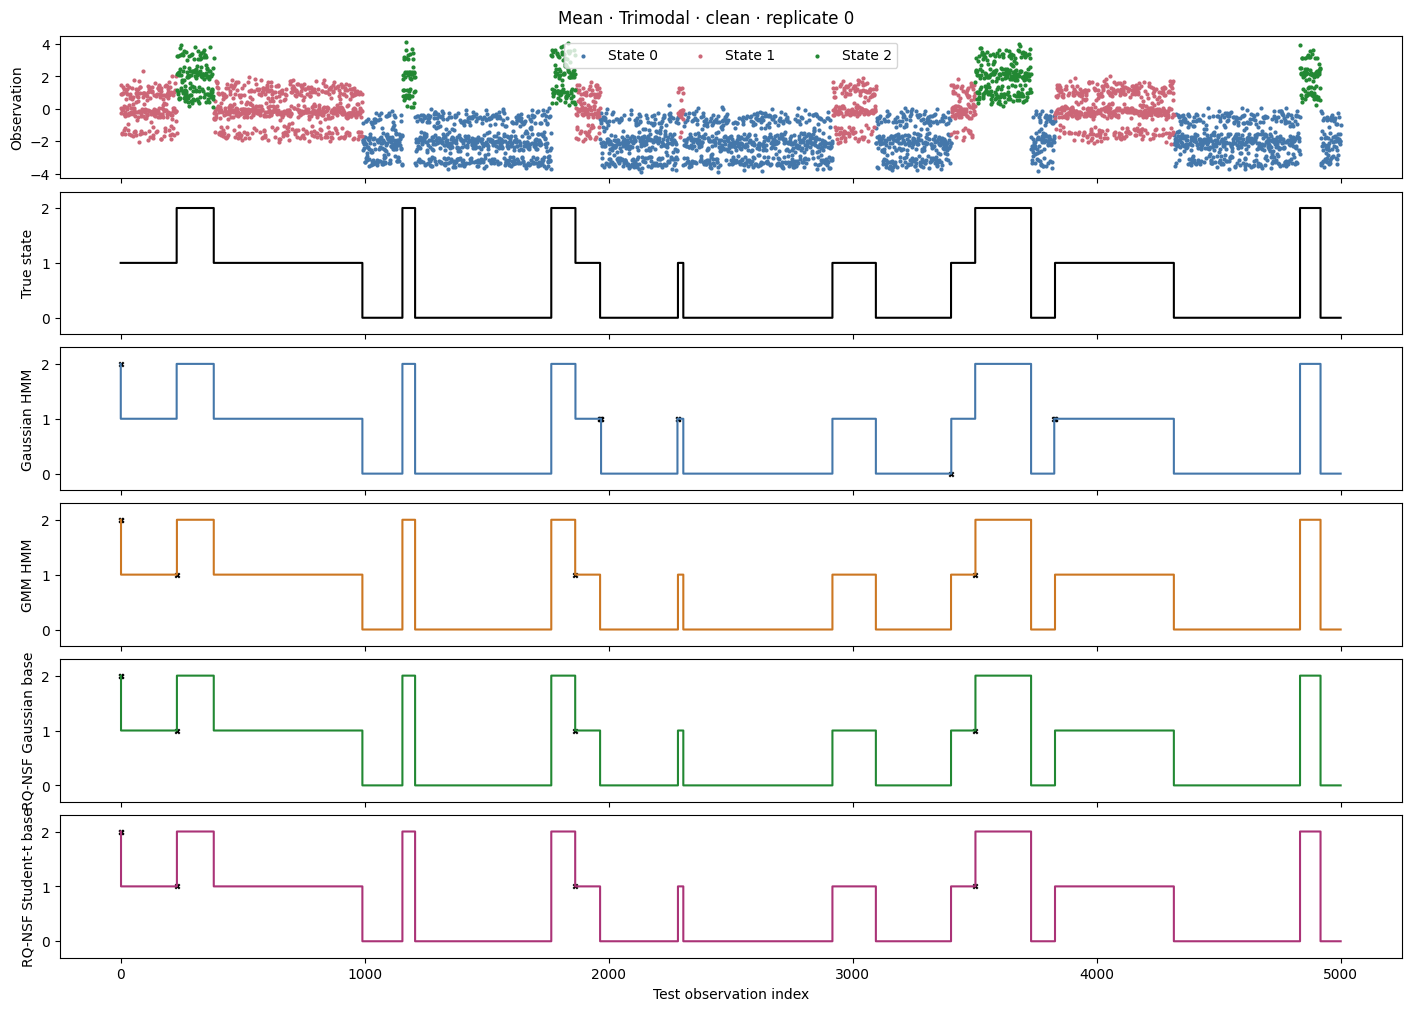

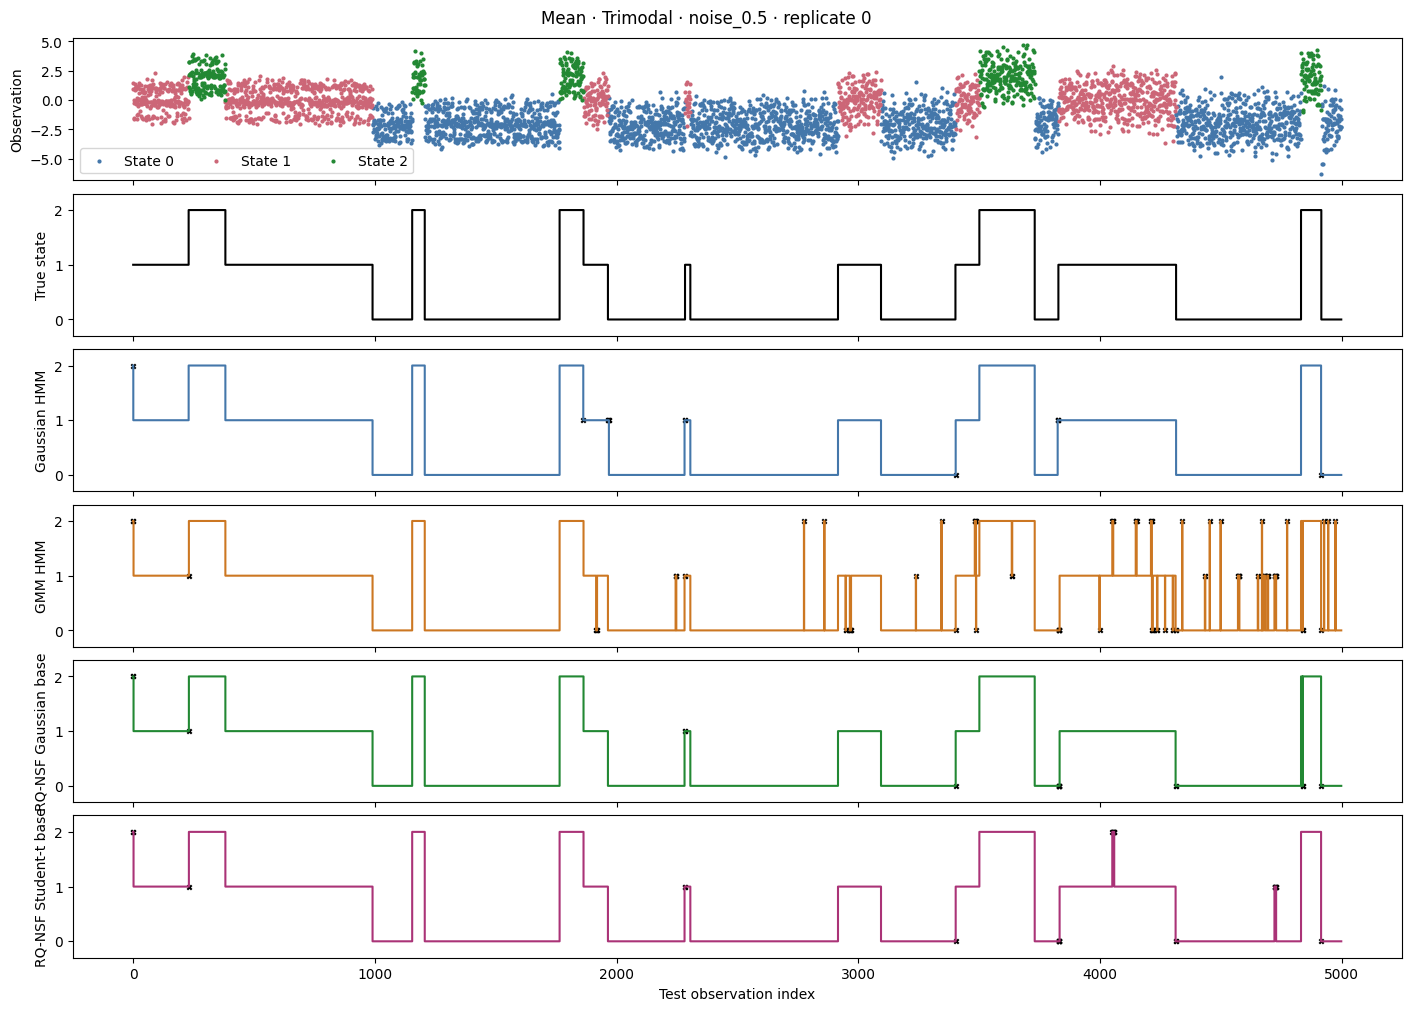

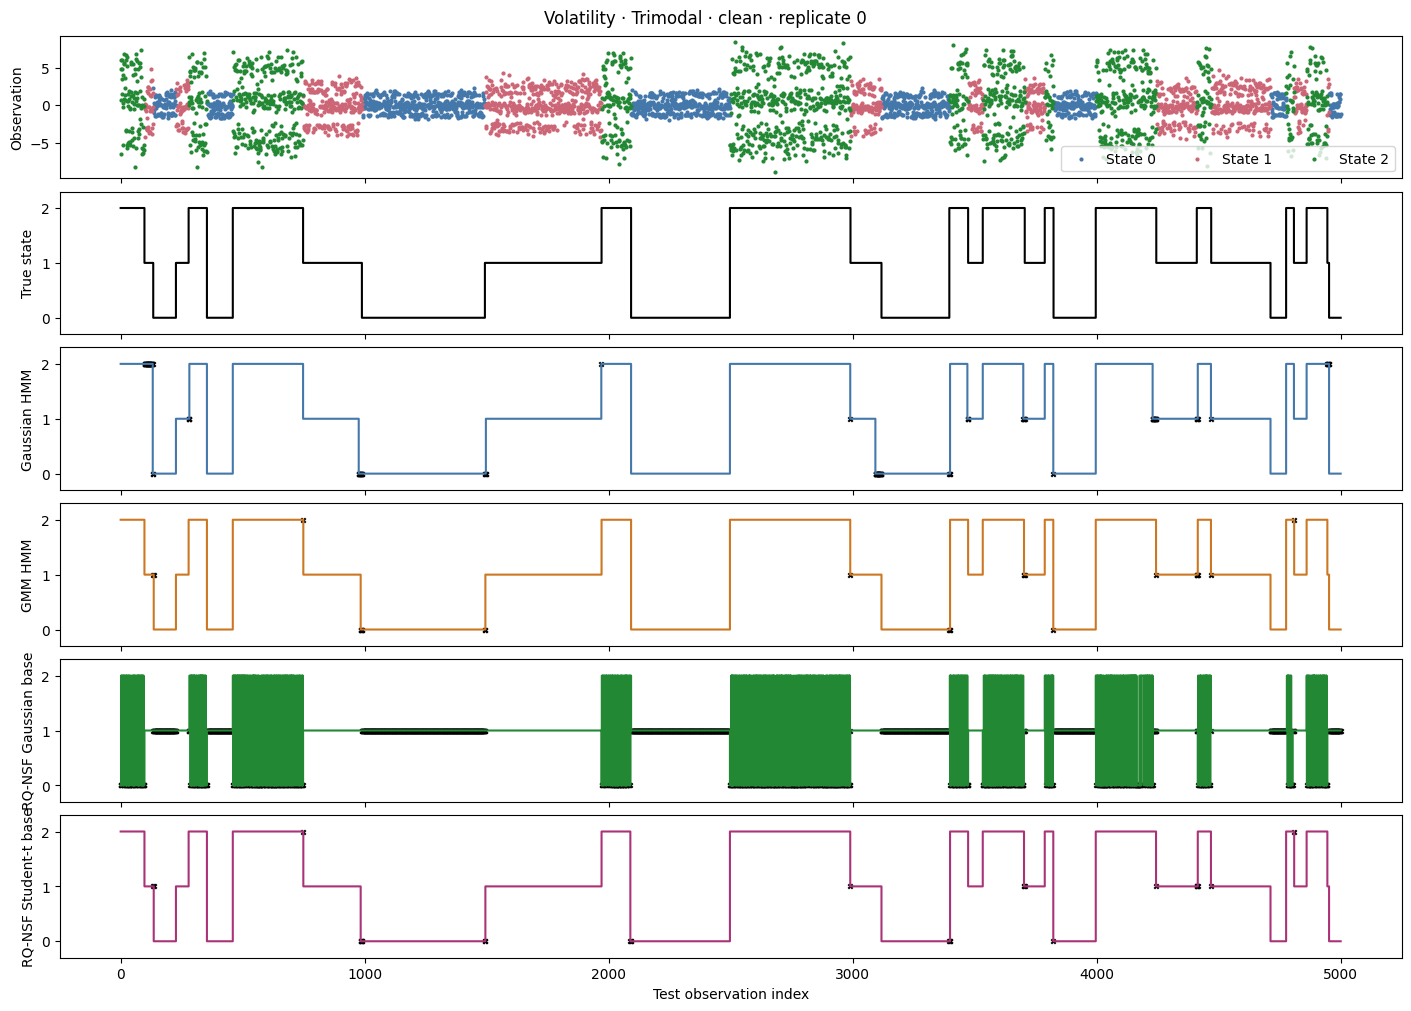

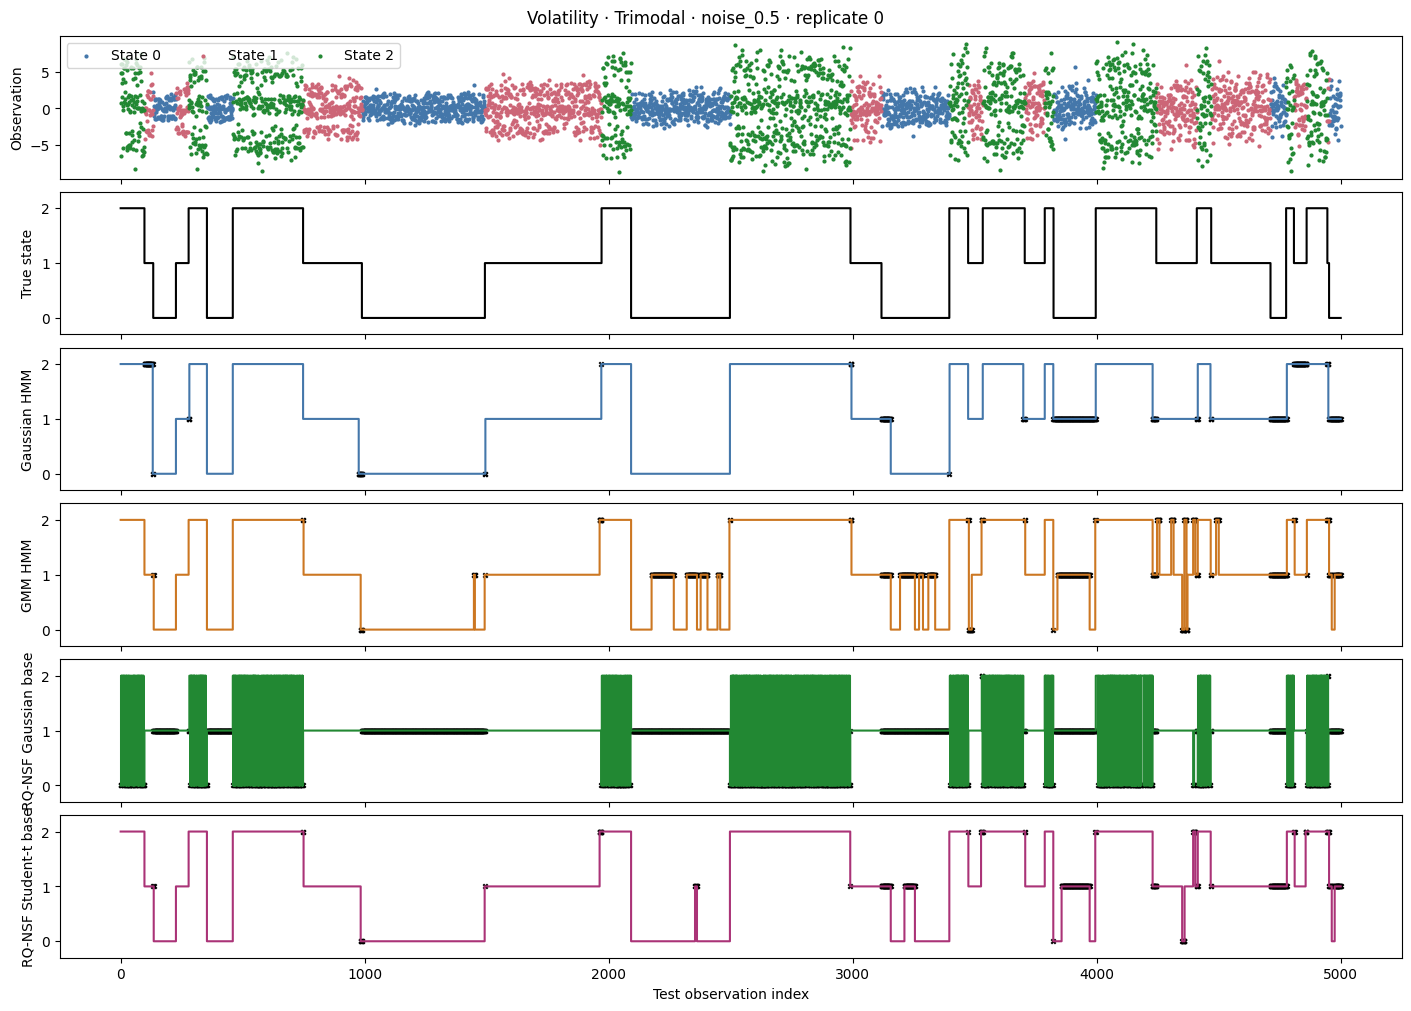

In [37]:
DECODED_PATH_FAMILY = "Trimodal"
DECODED_PATH_REPLICATE = 0

if report_ready:
    for regime, source in sources.items():
        if DECODED_PATH_FAMILY not in source.families:
            raise ValueError(
                f"Unknown family {DECODED_PATH_FAMILY!r} for {regime}. "
                f"Choose from {list(source.families)}."
            )
        eligible = clean[(clean.regime == regime)
                         & (clean.family == DECODED_PATH_FAMILY)
                         & (clean.replicate == DECODED_PATH_REPLICATE)]
        if not eligible.empty:
            for condition in ("clean", "noise_0.5"):
                fig = experiment.plot_decoding(
                    source, run_dir, family=DECODED_PATH_FAMILY,
                    condition=condition, points=source.settings["n_test"],
                    replicate=DECODED_PATH_REPLICATE,
                )
                show_and_save(
                    fig,
                    f"{regime}_{DECODED_PATH_FAMILY}_{condition}"
                    f"_replicate_{DECODED_PATH_REPLICATE}_decoded_example",
                )


## Noise robustness for mean and volatility regimes

f1_macro  \
                                                                  mean   
regime     family   n_train model                 condition              
mean       Gaussian 20000   GMM HMM               clean       0.997927   
                                                  noise_0.1   0.998037   
                                                  noise_0.25  0.998262   
                                                  noise_0.5   0.996689   
                            Gaussian HMM          clean       0.997950   
...                                                                ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  noise_0.5   0.836402   
                            RQ-NSF Student-t base clean       0.916142   
                                                  noise_0.1   0.915251   
                                                  noise_0.25  0.903297   
                                                  noise_0.5   0.834317   

                                                                              \
                                                                   std count   
regime     family   n_train model                 condition                    
mean       Gaussian 20000   GMM HMM               clean       0.000868    10   
                                                  noise_0.1   0.000607    10   
                                                  noise_0.25  0.000398    10   
                                                  noise_0.5   0.001211    10   
                            Gaussian HMM          clean       0.000859    10   
...                                                                ...   ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  noise_0.5   0.139616    10   
                            RQ-NSF Student-t base clean       0.168933    10   
                                                  noise_0.1   0.168255    10   
                                                  noise_0.25  0.165803    10   
                                                  noise_0.5   0.137309    10   

                                                             state_brier_score  \
                                                                          mean   
regime     family   n_train model                 condition                      
mean       Gaussian 20000   GMM HMM               clean               0.002956   
                                                  noise_0.1           0.002832   
                                                  noise_0.25          0.002922   
                                                  noise_0.5           0.005156   
                            Gaussian HMM          clean               0.002972   
...                                                                        ...   
volatility Trimodal 20000   RQ-NSF Gaussian base  noise_0.5           0.271189   
                            RQ-NSF Student-t base clean               0.142120   
                                                  noise_0.1           0.143080   
                                                  noise_0.25          0.160945   
                                                  noise_0.5           0.276261   

                                                                              \
                                                                   std count   
regime     family   n_train model                 condition                    
mean       Gaussian 20000   GMM HMM               clean       0.001041    10   
                                                  noise_0.1   0.000924    10   
                                                  noise_0.25  0.000814    10   
                                                  noise_0.5   0.001587    10   
                            Gaussian HMM          clean       0.001064    10   
...                                                                ...   ...   
volatility Trimodal 20000   RQ-NSF 

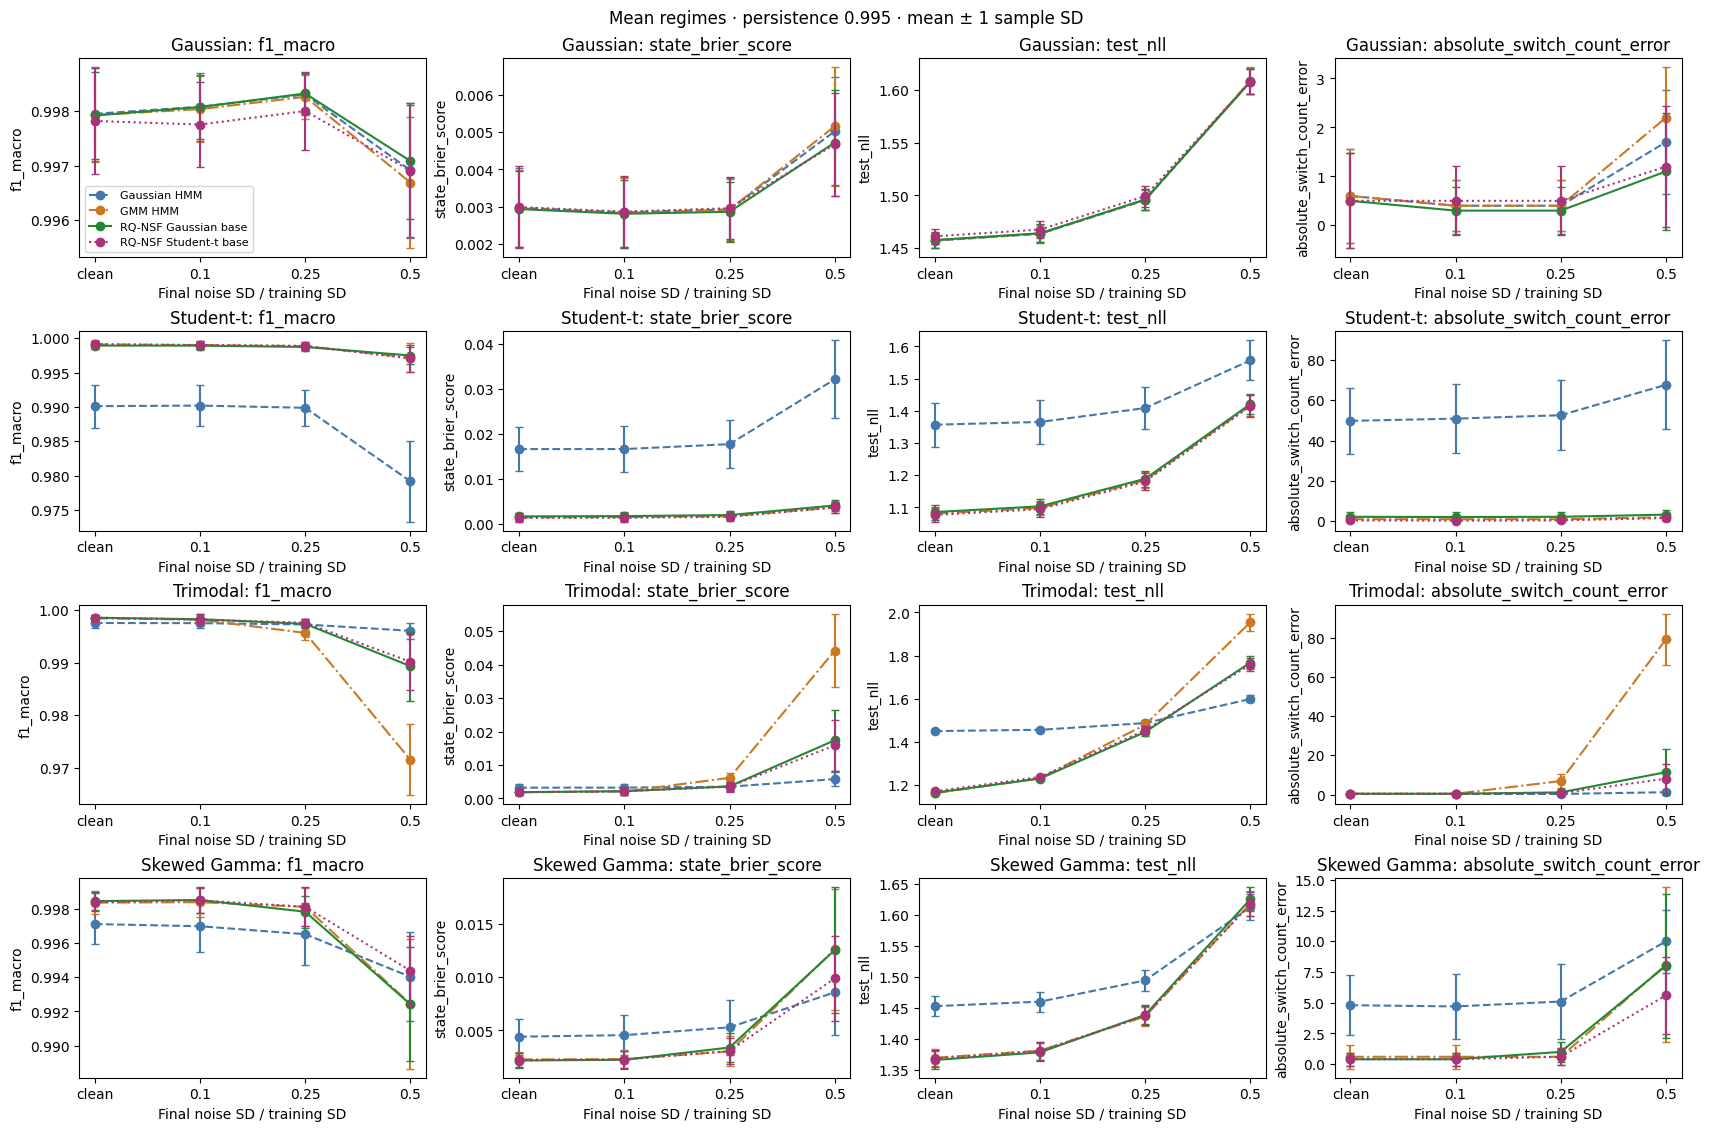

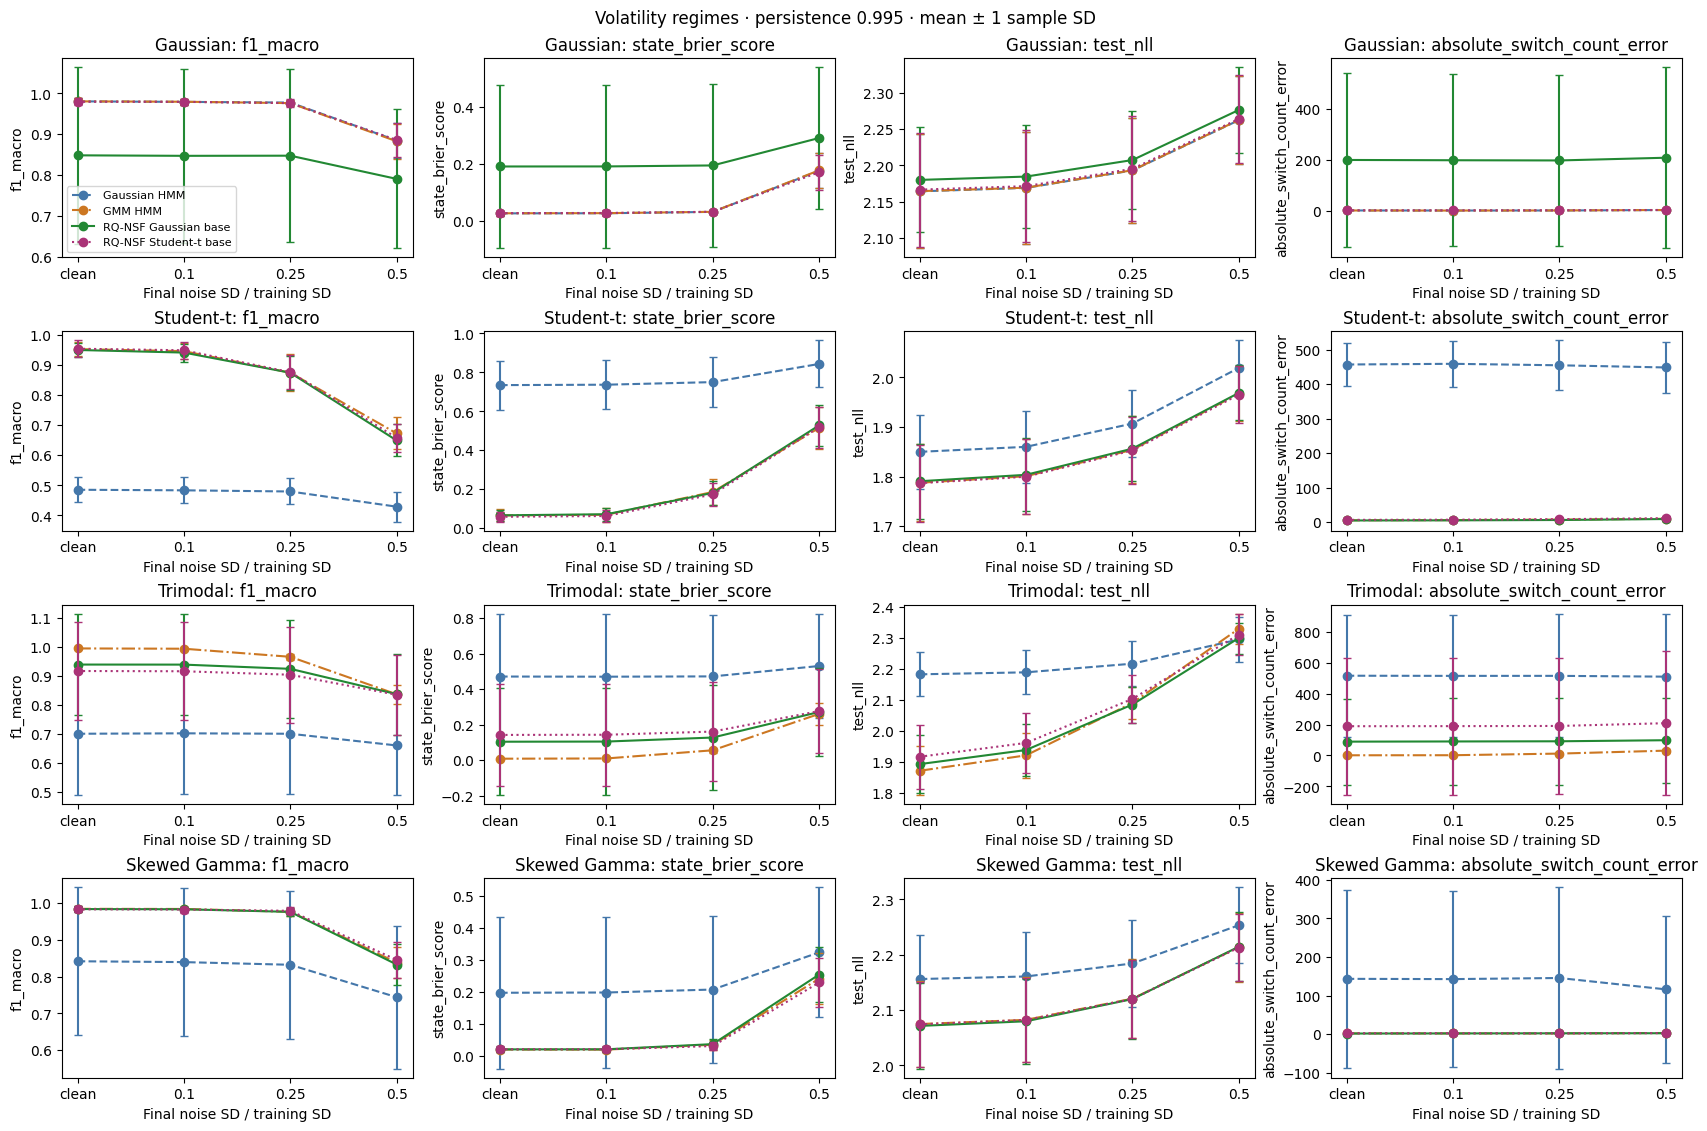

In [12]:
if report_ready and not robust.empty:
    noise_metrics = ["f1_macro", "state_brier_score", "test_nll",
                     "absolute_switch_count_error"]
    robustness_summary = robust.groupby([
        "regime", "family", "n_train", "model", "condition"
    ])[noise_metrics + ["aligned_accuracy", "state_log_loss",
                       "mean_true_state_posterior", "switch_f1"]].agg(["mean", "std", "count"])
    robustness_summary.to_csv(run_dir / "noise_robustness_summary.csv")
    display(robustness_summary)
    noise_deltas = experiment.paired_differences(robust, noise_metrics)
    noise_deltas.to_csv(run_dir / "noise_paired_model_differences.csv", index=False)
    for regime in sources:
        if not robust[robust.regime == regime].empty:
            show_and_save(experiment.plot_metrics(robust, regime, noise_metrics, noise=True),
                          f"{regime}_noise_robustness")
    clean_scores = robust[robust.condition == "clean"]
    key = experiment.KEYS + ["model"]
    perturbation_deltas = robust.merge(clean_scores[key + noise_metrics],
                                      on=key, suffixes=("", "_clean"), validate="many_to_one")
    for metric in noise_metrics:
        perturbation_deltas[f"{metric}_noisy_minus_clean"] = (
            perturbation_deltas[metric] - perturbation_deltas[f"{metric}_clean"]
        )
    perturbation_deltas.to_csv(run_dir / "noisy_minus_clean.csv", index=False)

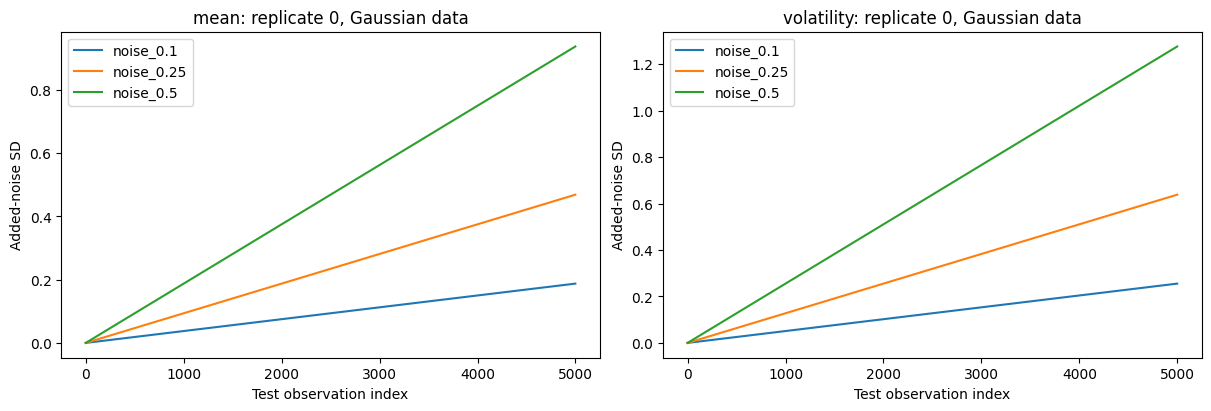

In [13]:
if report_ready:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for ax, (regime, source) in zip(axes, sources.items()):
        data = source.data(0, "Gaussian")
        n_train = max(source.settings["train_sizes"])
        variants = source.variants(data["train"].iloc[:n_train], data["test"],
                                   0, "Gaussian", n_train)
        for condition, frame in variants.items():
            if condition != "clean":
                ax.plot(frame.time, frame.noise_std, label=condition)
        ax.set(title=f"{regime}: replicate 0, Gaussian data",
               xlabel="Test observation index", ylabel="Added-noise SD")
        ax.legend()
    show_and_save(fig, "measurement_noise_schedules")

## Fit reliability and computation

starts  failures  \
regime     family       n_train model                                     
mean       Gaussian     20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   
           Skewed Gamma 20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   
           Student-t    20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   
           Trimodal     20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   
volatility Gaussian     20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   
           Skewed Gamma 20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   
           Student-t    20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   
           Trimodal     20000   GMM HMM                   100         0   
                                Gaussian HMM              100         0   
                                RQ-NSF Gaussian base      100         0   
                                RQ-NSF Student-t base     100         0   

                                                       converged_starts  \
regime     family       n_train model                                     
mean       Gaussian     20000   GMM HMM                             100   
                                Gaussian HMM                        100   
                                RQ-NSF Gaussian base                100   
                                RQ-NSF Student-t base               100   
           Skewed Gamma 20000   GMM HMM                             100   
                                Gaussian HMM                        100   
                                RQ-NSF Gaussian base                100   
                                RQ-NSF Student-t base               100   
           Student-t    20000   GMM HMM                             100   
                                Gaussian HMM                        100   
                                RQ-NSF Gaussian base                100   
                                RQ-NSF Student-t base               100   
           Trimodal     20000   GMM HMM                             100   
                                Gaussian HMM                        100   
                                RQ-NSF Gaussian base                100   
                                RQ-NSF Student-t base               100   
volatility Gaussian     20000   GMM HMM                             100   
                                Gaussian HMM                        100   
    

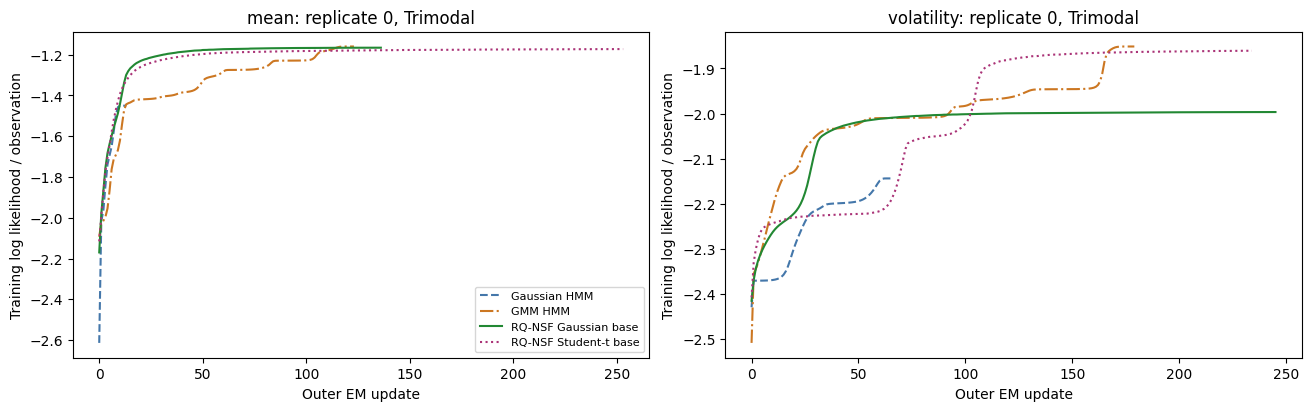

In [22]:
if report_ready:
    attempts = run["attempts"]
    fit_diagnostics = attempts.assign(failed=attempts.status.ne("ok")).groupby([
        "regime", "family", "n_train", "model"
    ]).agg(starts=("status", "size"), failures=("failed", "sum"),
           converged_starts=("converged", "sum"),
           mean_iterations=("iterations", "mean"),
           total_fit_seconds=("fit_seconds", "sum"),
           likelihood_decreases=("likelihood_decreases", "sum"))
    fit_diagnostics.to_csv(run_dir / "fit_diagnostics.csv")
    display(fit_diagnostics)
    history_fig, history_axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
    for ax, regime in zip(history_axes, sources):
        for model in experiment.MODELS:
            selected = attempts[(attempts.regime == regime)
                                & (attempts.family == "Trimodal")
                                & (attempts.replicate == 0)
                                & (attempts.model == model) & attempts.selected]
            if not selected.empty:
                history = selected.iloc[0]["history"]
                if isinstance(history, str):
                    import ast
                    history = ast.literal_eval(history)
                ax.plot(np.arange(len(history)), np.asarray(history) / 20000,
                        color=experiment.COLORS[model], linestyle=experiment.STYLES[model],
                        label=model)
        ax.set(title=f"{regime}: replicate 0, Trimodal", xlabel="Outer EM update",
               ylabel="Training log likelihood / observation")
    history_axes[0].legend(fontsize=8)
    show_and_save(history_fig, "selected_training_histories")

## Reference Gaussian KL floor

The Gaussian matching each true state's mean and variance minimizes
$\mathrm{KL}(p_{\rm true}\|q_{\rm Gaussian})$.

In [15]:
if report_ready:
    floors = experiment.gaussian_floors(sources)
    floors.to_csv(run_dir / "gaussian_kl_floors.csv", index=False)
    display(floors)

,regime,family,state,gaussian_kl_floor,quad_error
0,mean,Gaussian,0,0.000000e+00,0.000000e+00
1,mean,Gaussian,1,0.000000e+00,0.000000e+00
2,mean,Gaussian,2,0.000000e+00,0.000000e+00
3,mean,Student-t,0,3.758974e-01,2.823534e-10
4,mean,Student-t,1,3.758974e-01,8.335582e-11
5,mean,Student-t,2,3.758974e-01,2.823534e-10
6,mean,Trimodal,0,2.590785e-01,6.915789e-11
7,mean,Trimodal,1,3.202311e-01,8.834569e-10
8,mean,Trimodal,2,3.045005e-01,4.735515e-10
9,mean,Skewed Gamma,0,8.867925e-02,4.300524e-10


## One representative volatility replicate

In [ ]:
import importlib

experiment = importlib.reload(experiment)

if report_ready:
    representative_metrics = [
        "f1_macro", "emission_kl", "transition_rmse", "absolute_switch_count_error",
    ]
    volatility_source = sources["volatility"]
    representative_n_train = max(volatility_source.settings["train_sizes"])
    representative_data = run["results"].loc[
        (run["results"].regime == "volatility")
        & (run["results"].condition == "clean")
        & (run["results"].n_train == representative_n_train)
        & (run["results"].evaluation_status == "ok")
    ].copy()
    feature_columns = pd.MultiIndex.from_product([
        representative_metrics, volatility_source.families, experiment.MODELS,
    ])
    features = representative_data.pivot(
        index="replicate", columns=["family", "model"],
        values=representative_metrics,
    ).reindex(columns=feature_columns).sort_index()
    features = features.loc[np.isfinite(features.to_numpy()).all(axis=1)]
    if len(features) < 2:
        raise ValueError("Need at least two complete replicates across all families.")
    centers = features.median()
    scales = features.quantile(0.75) - features.quantile(0.25)
    fallback_scales = (features.max() - features.min()).replace(0, 1.0)
    scales = scales.mask(scales.eq(0), fallback_scales)
    scores = features.sub(centers).abs().div(scales).mean(axis=1)
    representative_replicate = int(scores.idxmin())
    representative_selection = pd.DataFrame([{
        "replicate": representative_replicate,
        "representativeness_score": float(scores.loc[representative_replicate]),
        "complete_replicates": len(features),
        "families": len(volatility_source.families),
        "models": len(experiment.MODELS),
    }])
    representative_scores = scores.rename("representativeness_score").reset_index()
    representative_details = representative_data.loc[
        representative_data.replicate == representative_replicate
    ].copy()
    representative_selection.to_csv(
        run_dir / "representative_volatility_replicates.csv", index=False,
    )
    representative_scores.to_csv(
        run_dir / "representative_volatility_scores.csv", index=False,
    )
    print(f"All representative plots below use replicate {representative_replicate}.")
    print("Selection averages median-distance scores across all families and models.")
    display(representative_selection.round(4))
    representative_display = representative_details.assign(
        macro_f1_percent=100 * representative_details.f1_macro,
    )[[
        "family", "replicate", "model", "macro_f1_percent", "emission_kl",
        "transition_rmse", "inferred_switches", "true_switches",
    ]].sort_values(["family", "model"])
    display(representative_display.round({
        "macro_f1_percent": 2, "emission_kl": 5, "transition_rmse": 6,
    }))
else:
    print("Load the completed results before selecting a representative replicate.")


All representative plots below use replicate 8.
Selection averages median-distance scores across all families and models.


replicate,representativeness_score,complete_replicates,families,models
8,0.4708,10,4,4


family,replicate,model,macro_f1_percent,emission_kl,transition_rmse,inferred_switches,true_switches
Gaussian,8,GMM HMM,98.49,0.00043,0.000739,22,24
Gaussian,8,Gaussian HMM,98.49,0.00029,0.000736,22,24
Gaussian,8,RQ-NSF Gaussian base,54.89,0.14274,0.347234,471,24
Gaussian,8,RQ-NSF Student-t base,98.49,0.00399,0.000741,22,24
Skewed Gamma,8,GMM HMM,98.80,0.00697,0.000870,22,24
Skewed Gamma,8,Gaussian HMM,95.01,0.08983,0.002764,41,24
Skewed Gamma,8,RQ-NSF Gaussian base,98.87,0.00410,0.000870,22,24
Skewed Gamma,8,RQ-NSF Student-t base,98.80,0.00698,0.000840,22,24
Student-t,8,GMM HMM,97.64,0.00856,0.000810,24,24
Student-t,8,Gaussian HMM,53.21,0.63490,0.408622,402,24


### Representative volatility: true and fitted flow emission densities

Show the true density and both flow densities for every generating family, all using the single selected replicate ID. Use the same state alignment and density windows as the original plots.

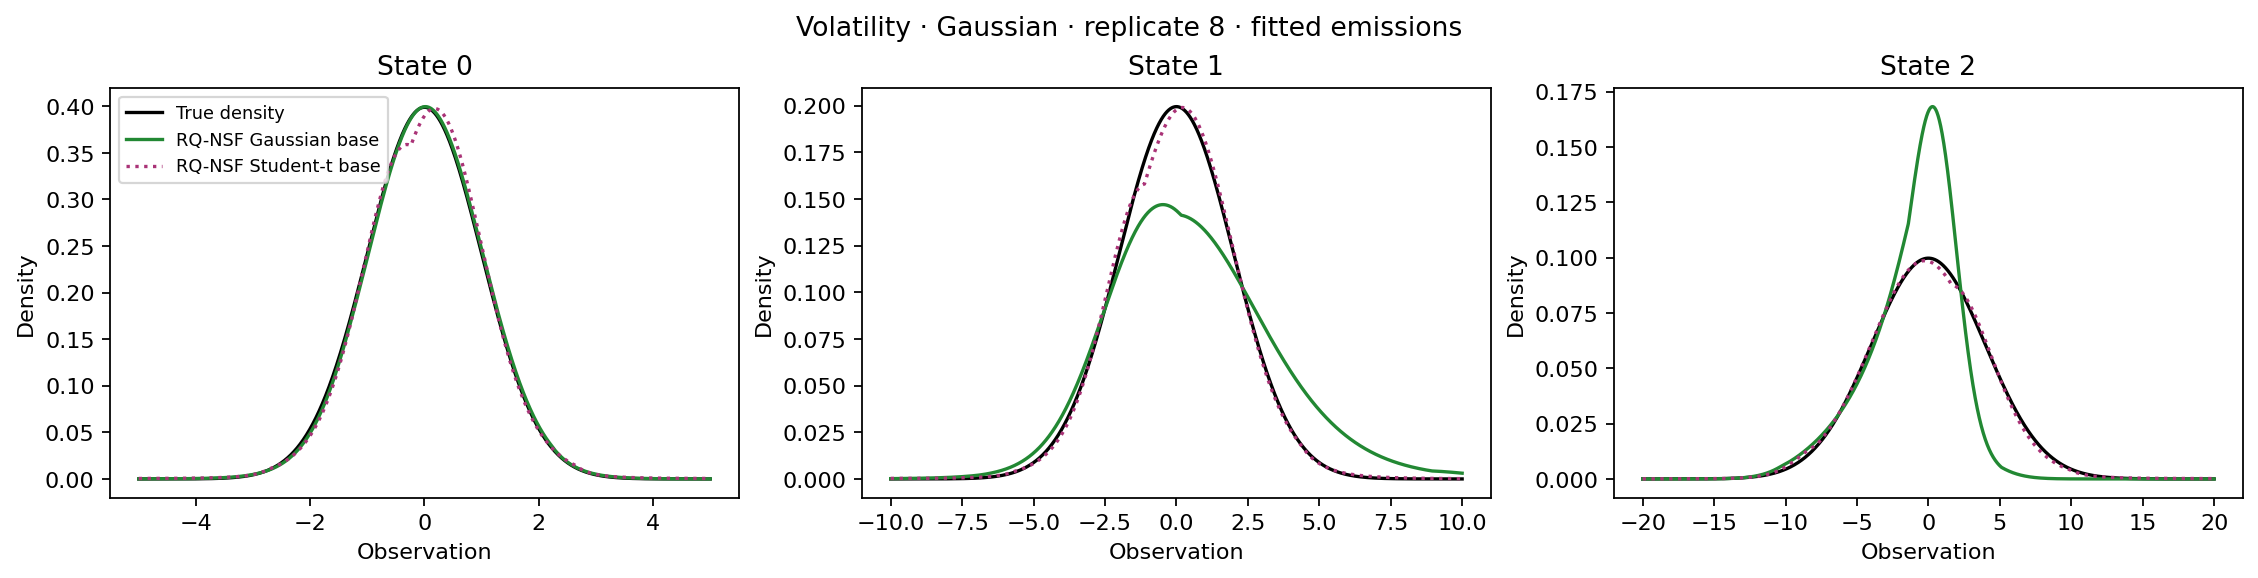

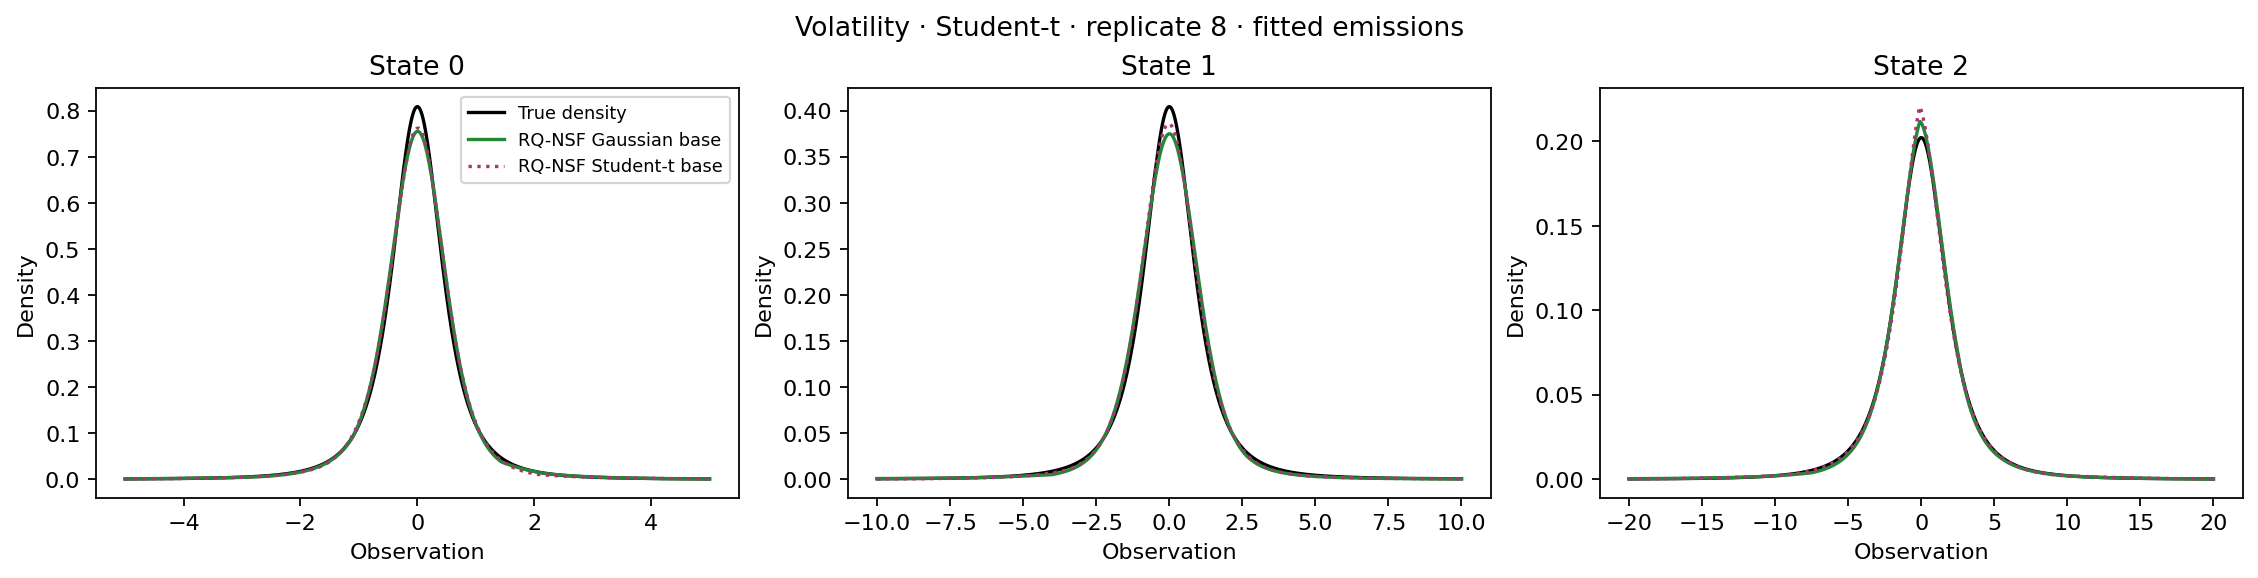

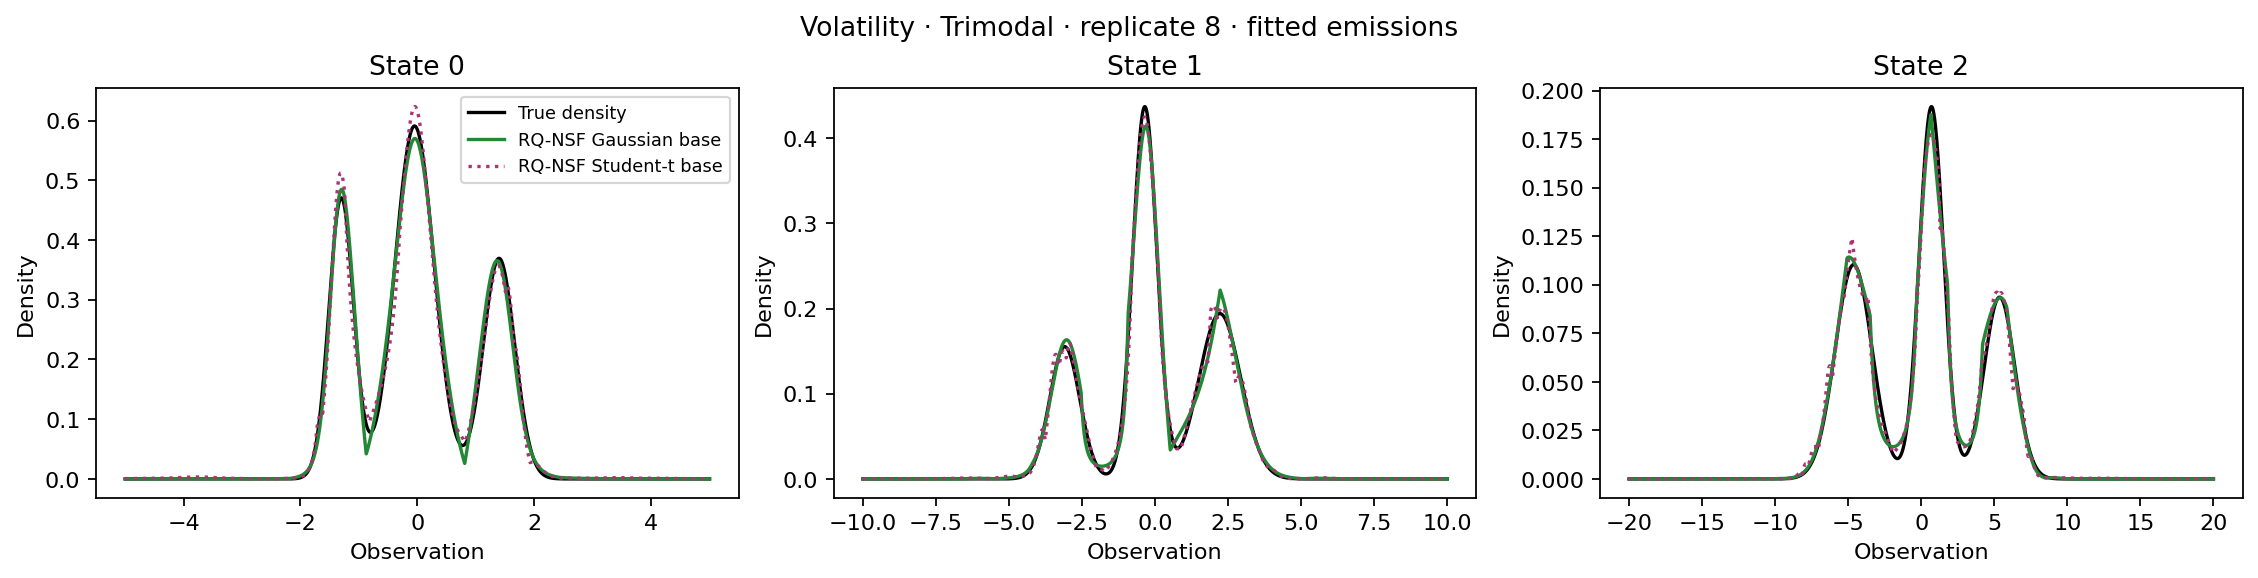

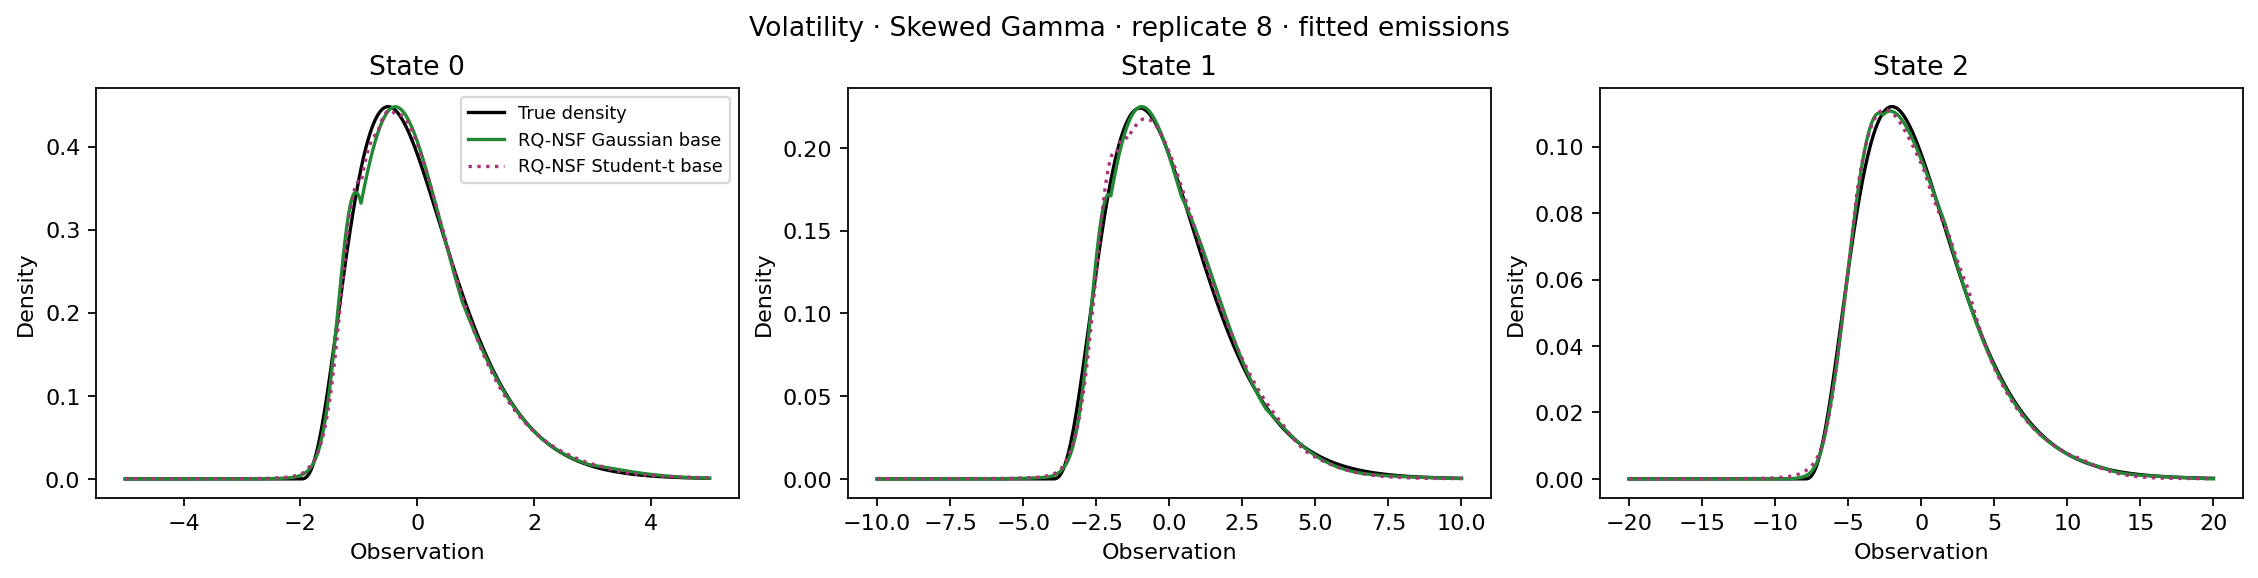

In [ ]:
if report_ready:
    for family in volatility_source.families:
        fig = experiment.plot_emissions(
            volatility_source, run_dir, family,
            flow_only=True, replicate=representative_replicate,
        )
        show_and_save(
            fig,
            f"volatility_{family}_replicate_{representative_replicate}"
            "_representative_flow_emissions",
        )


### Representative volatility: decoded state paths

Show observations, true states, and all four models' decoded states for every family using the same single replicate ID as all the density plots above. Crosses mark incorrect decoded states.

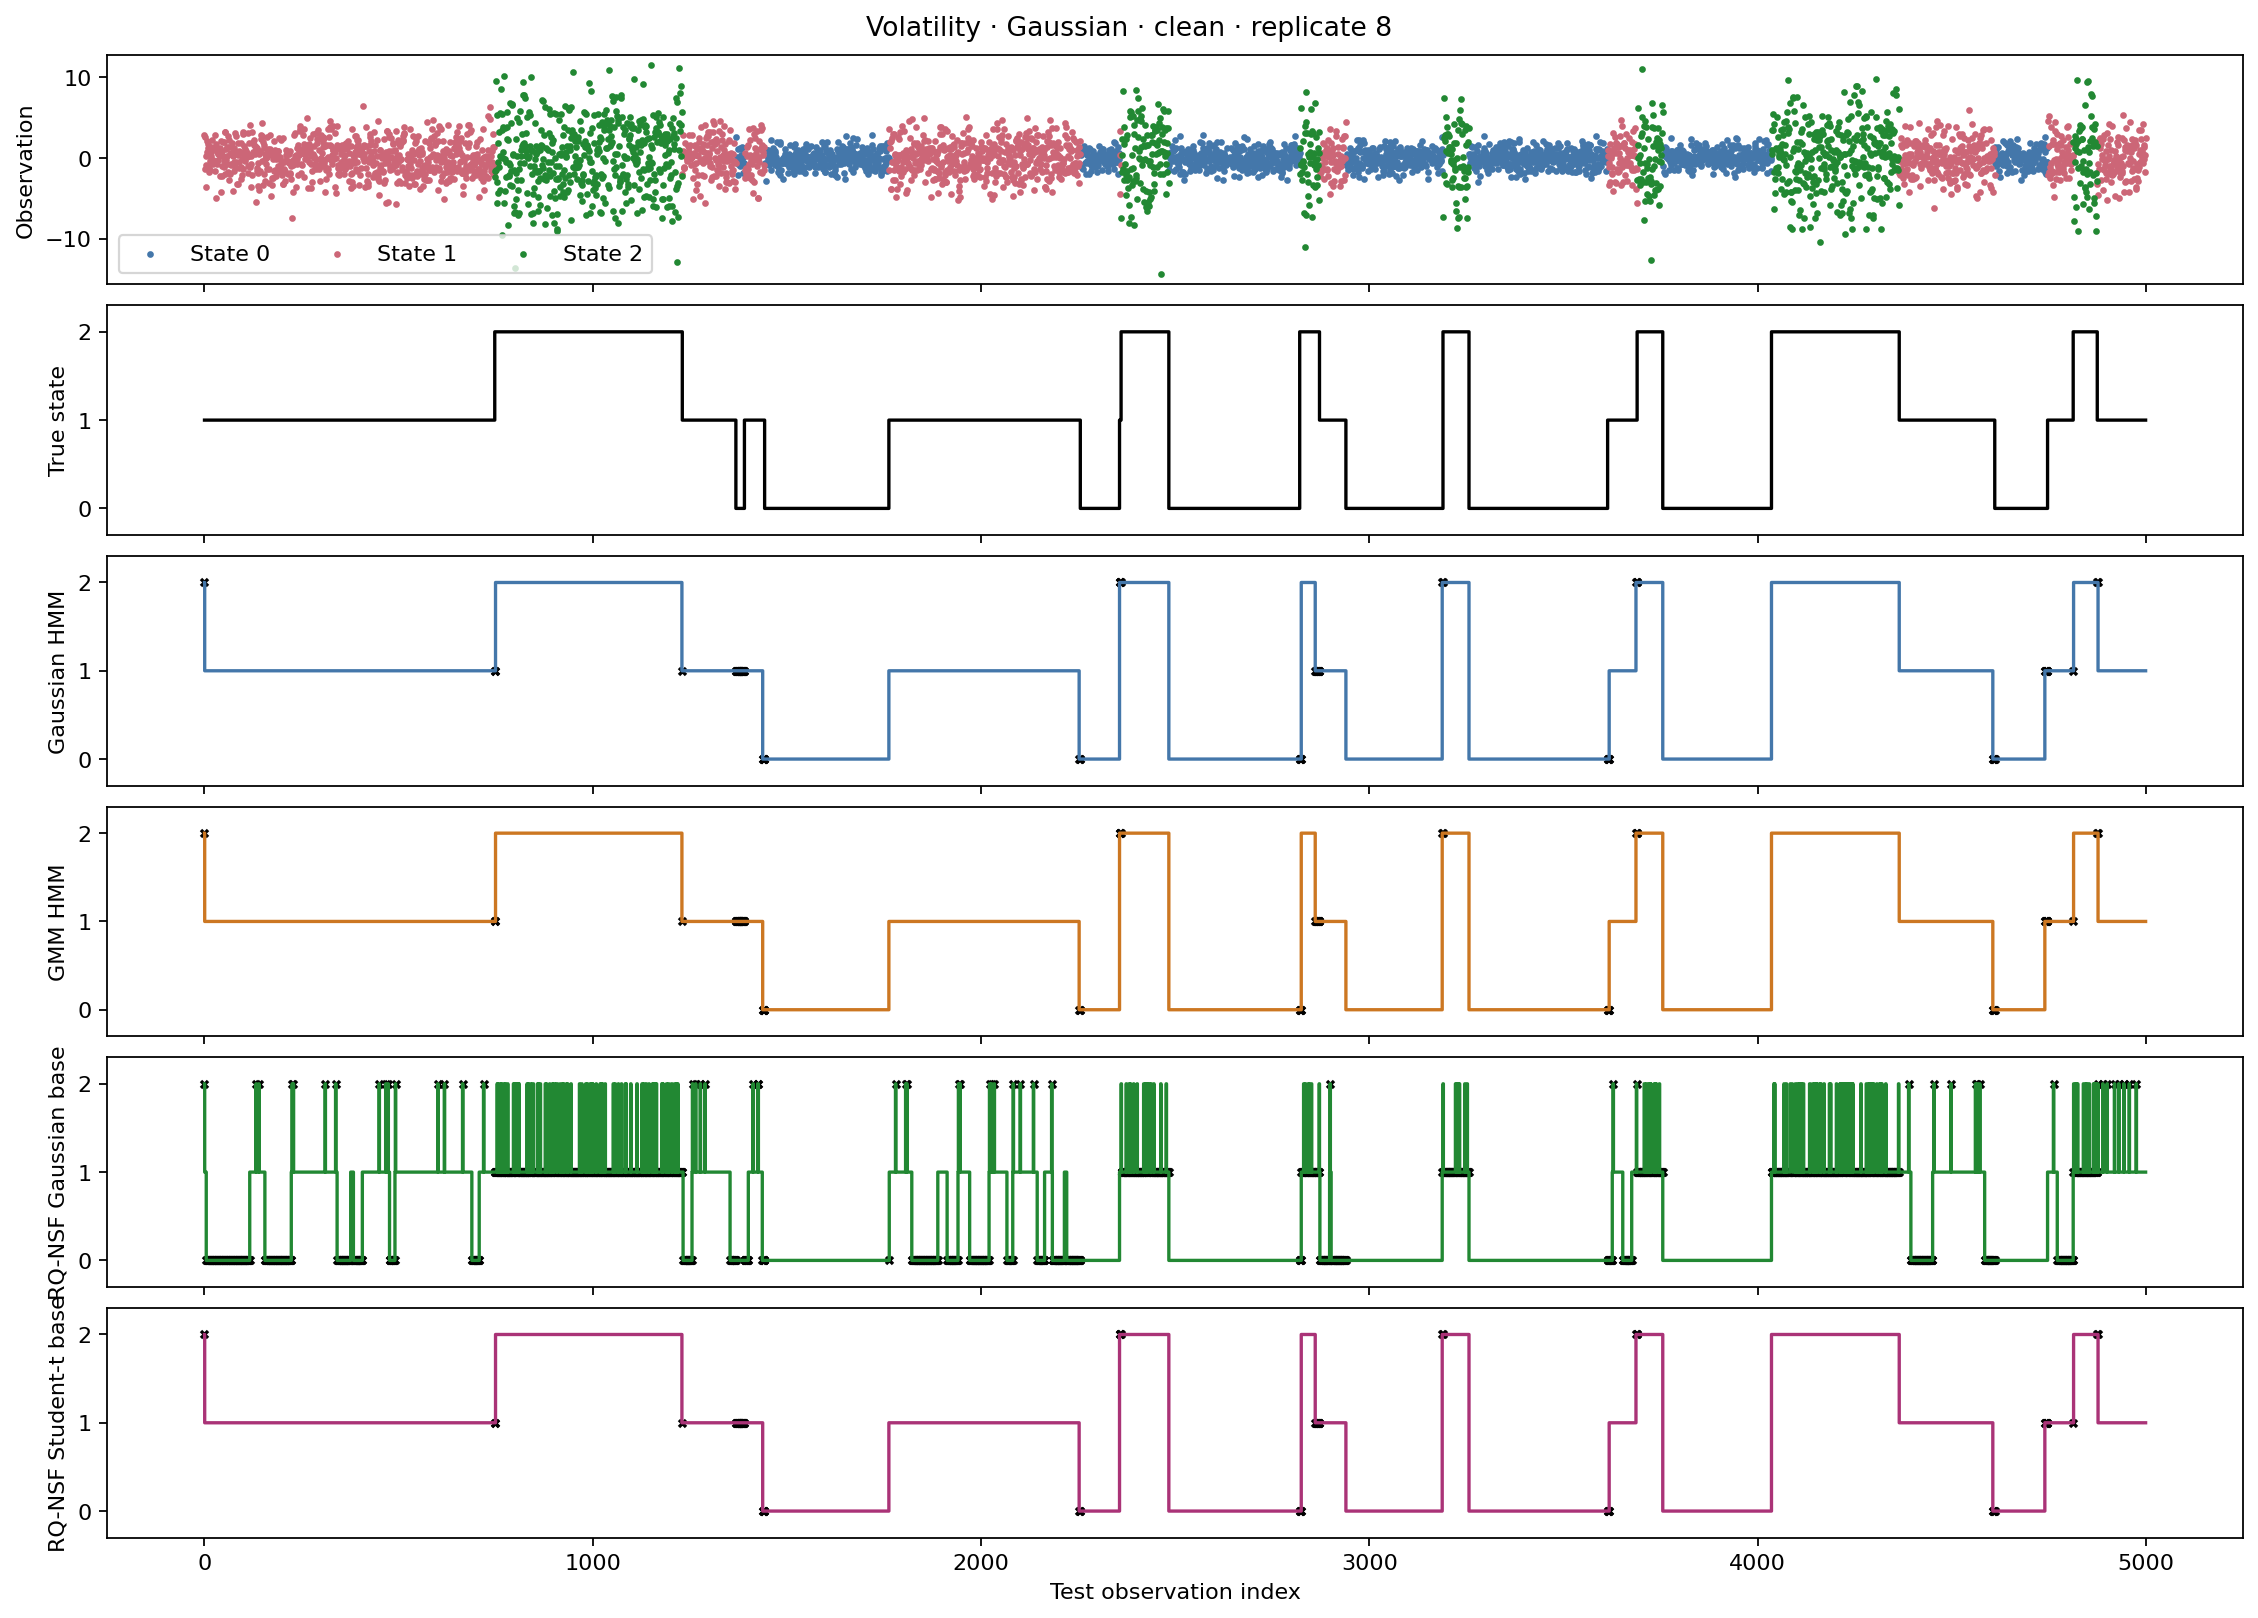

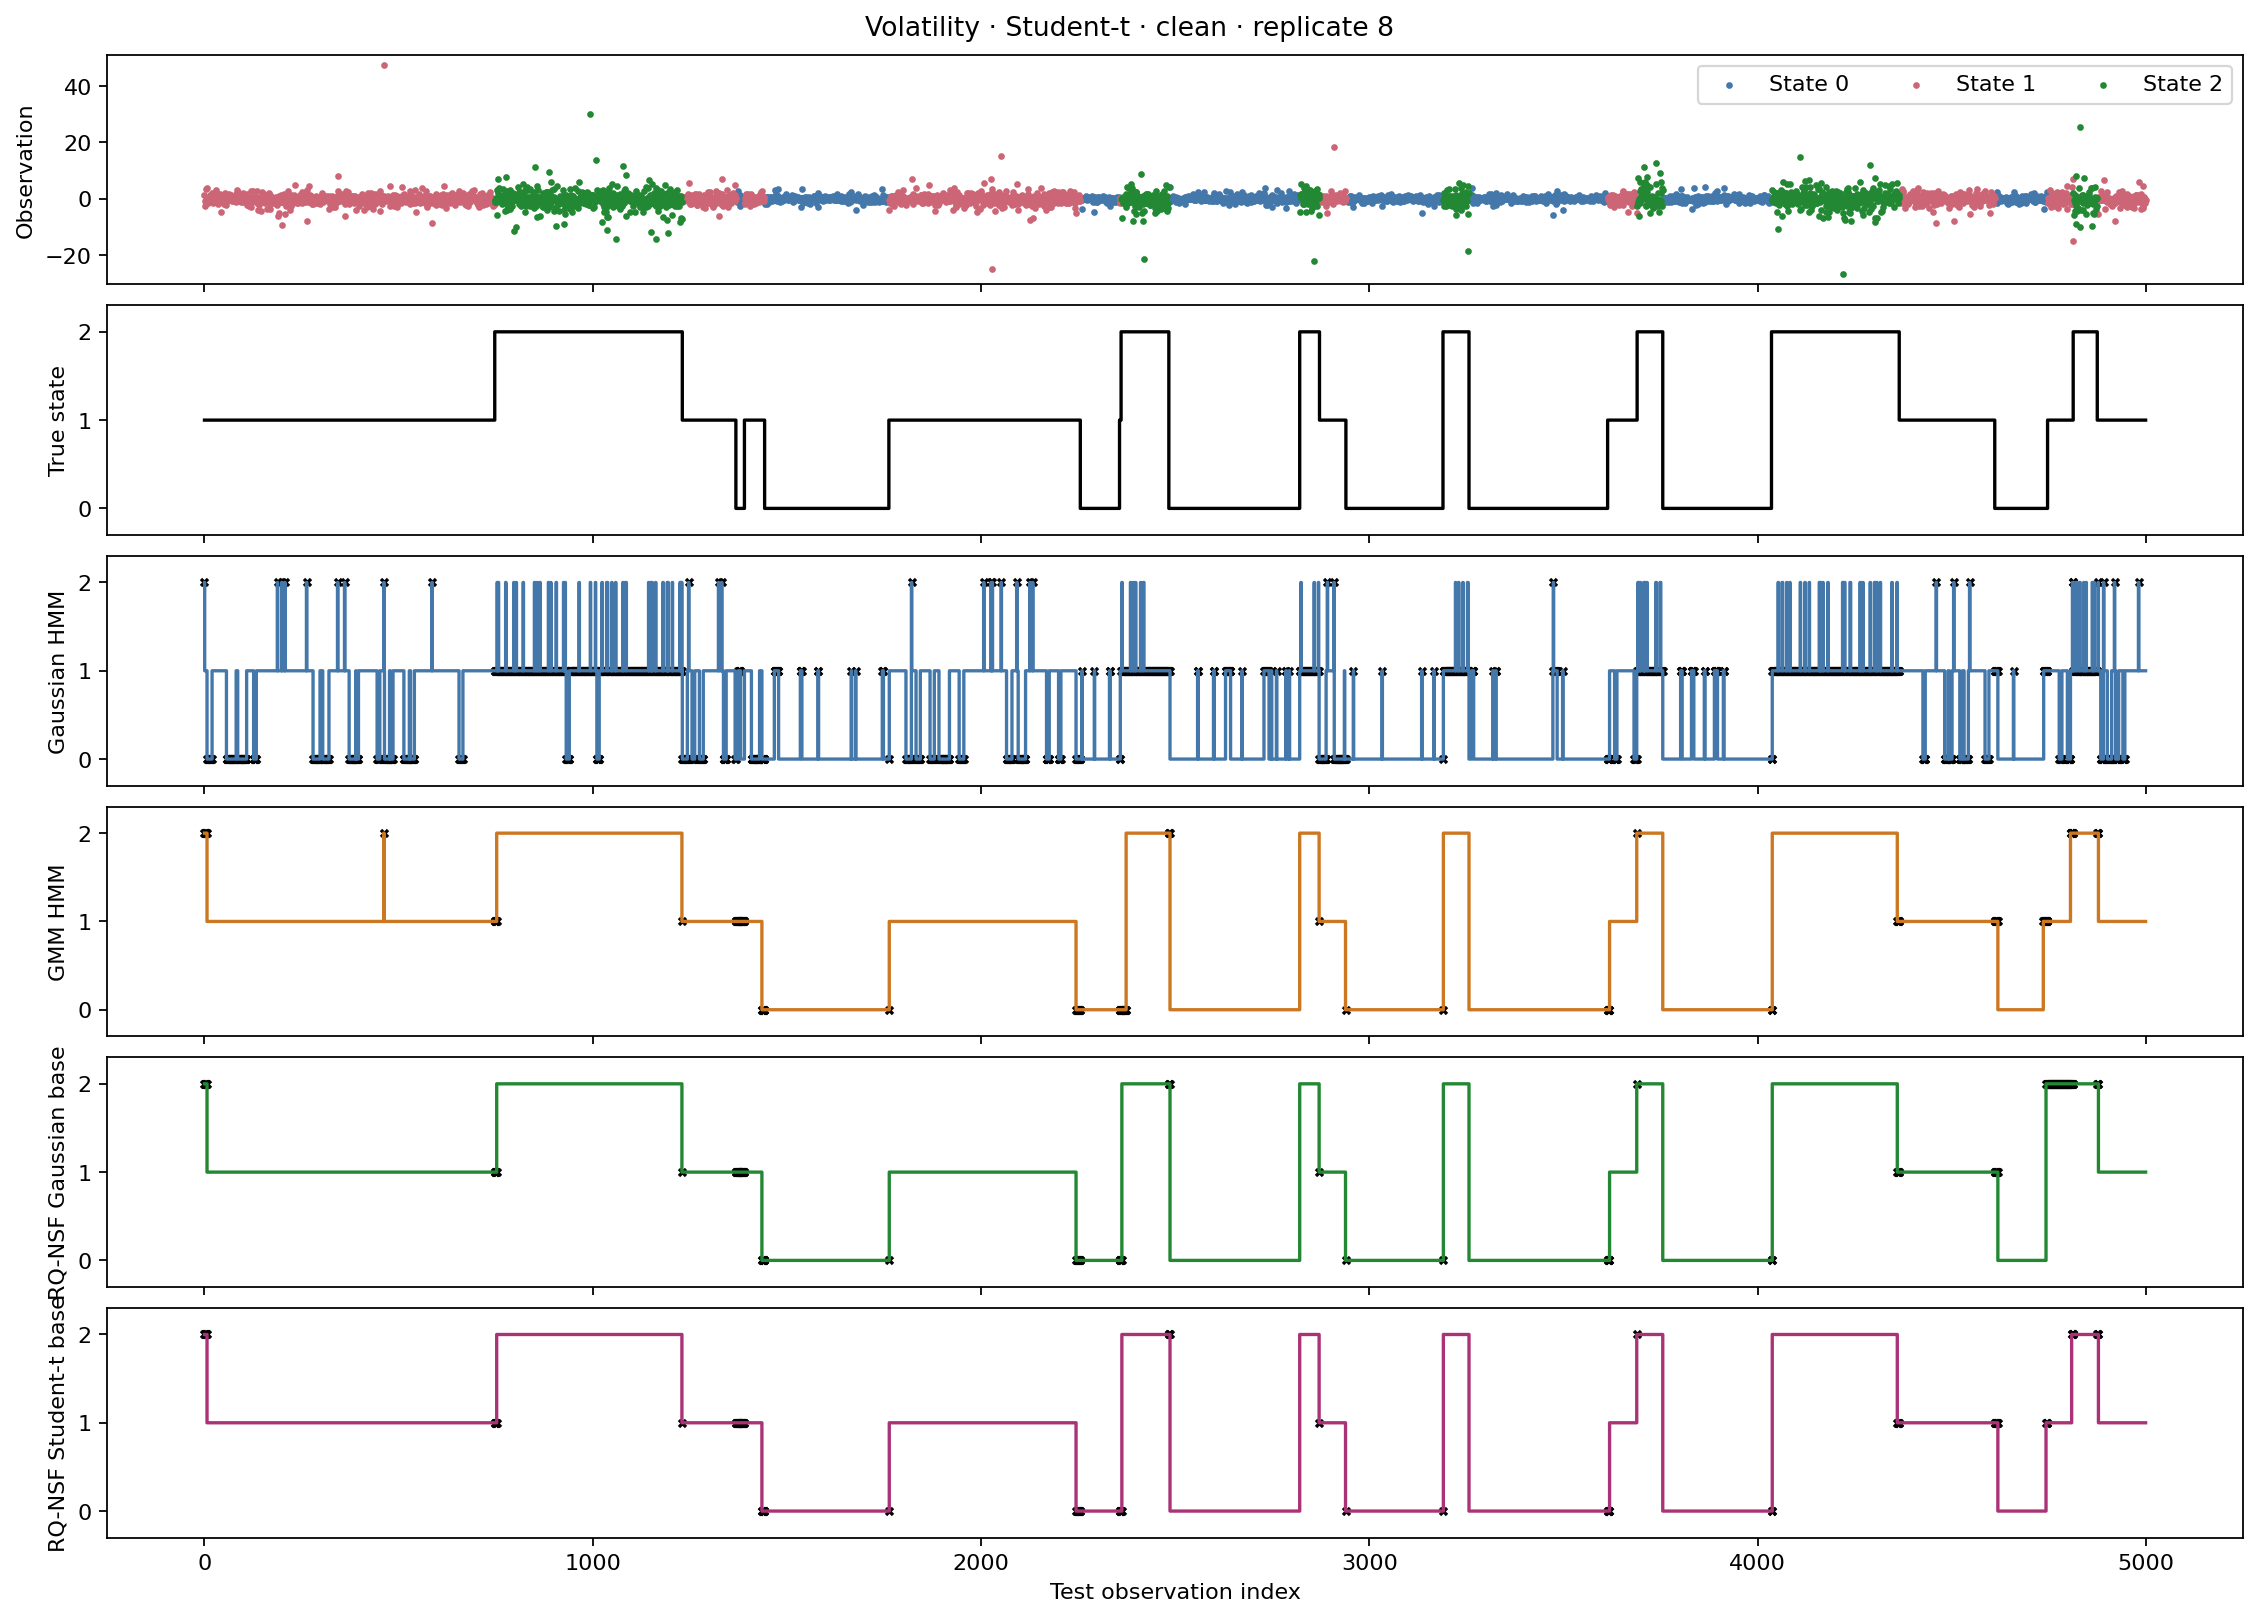

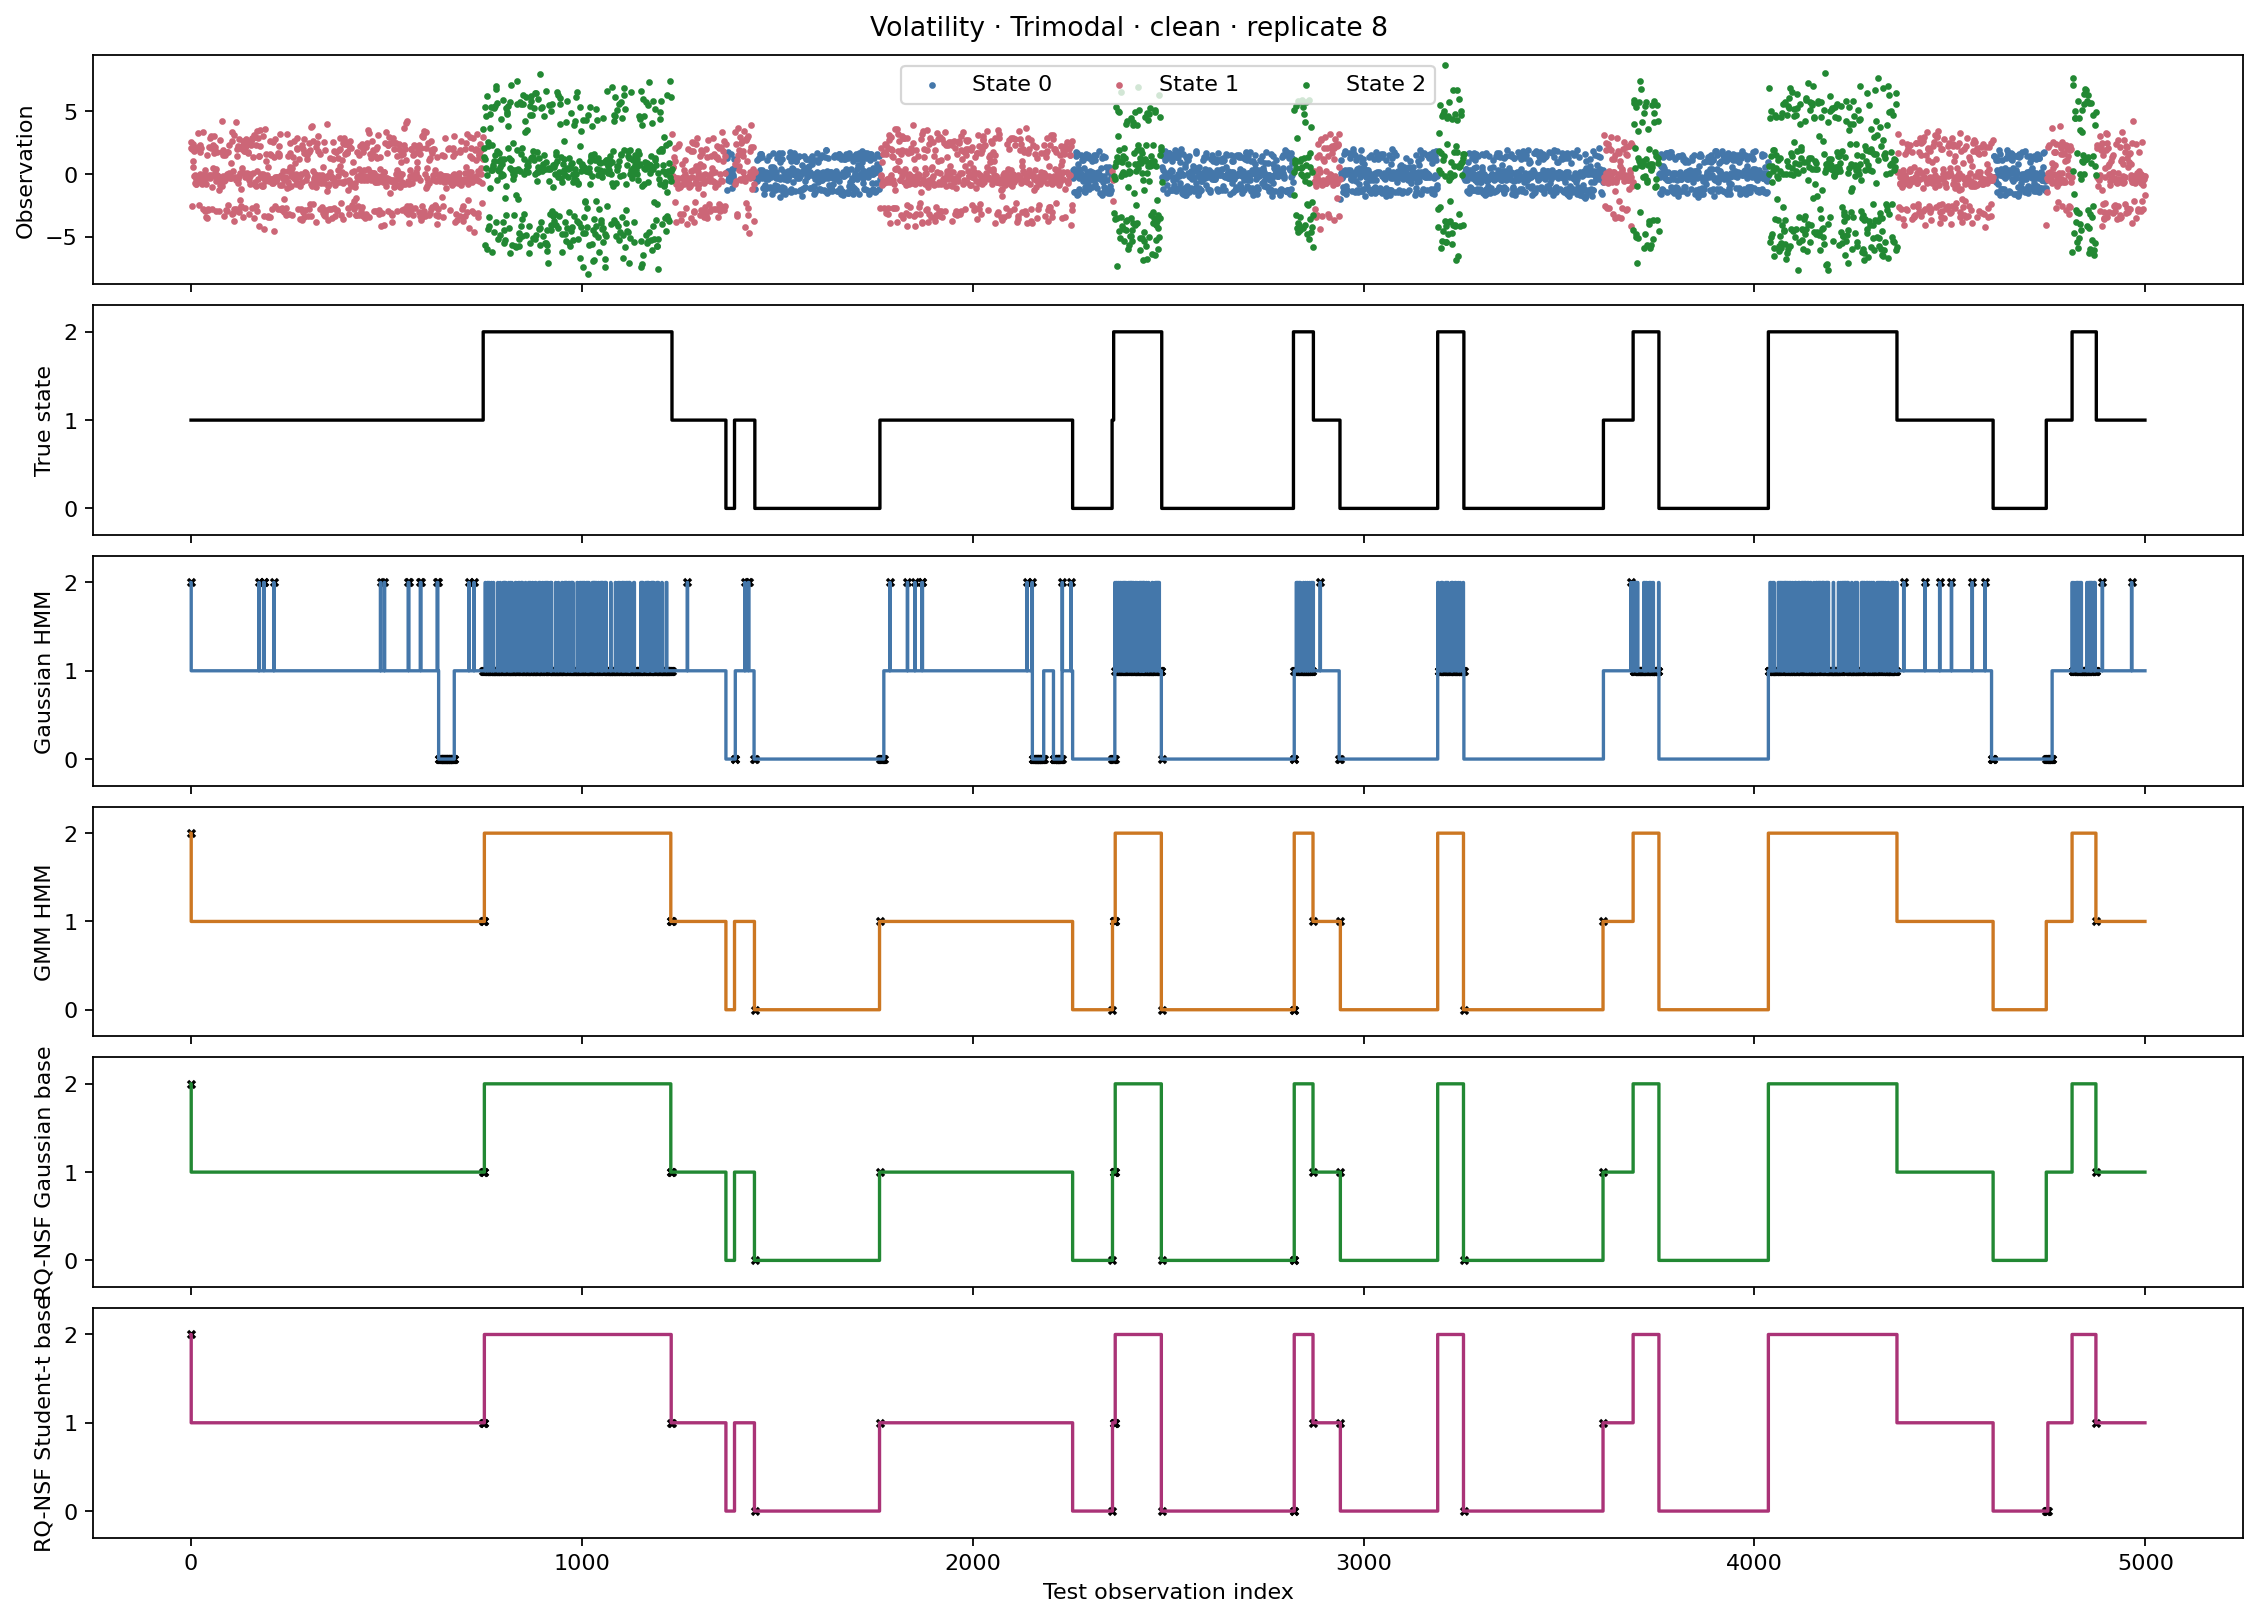

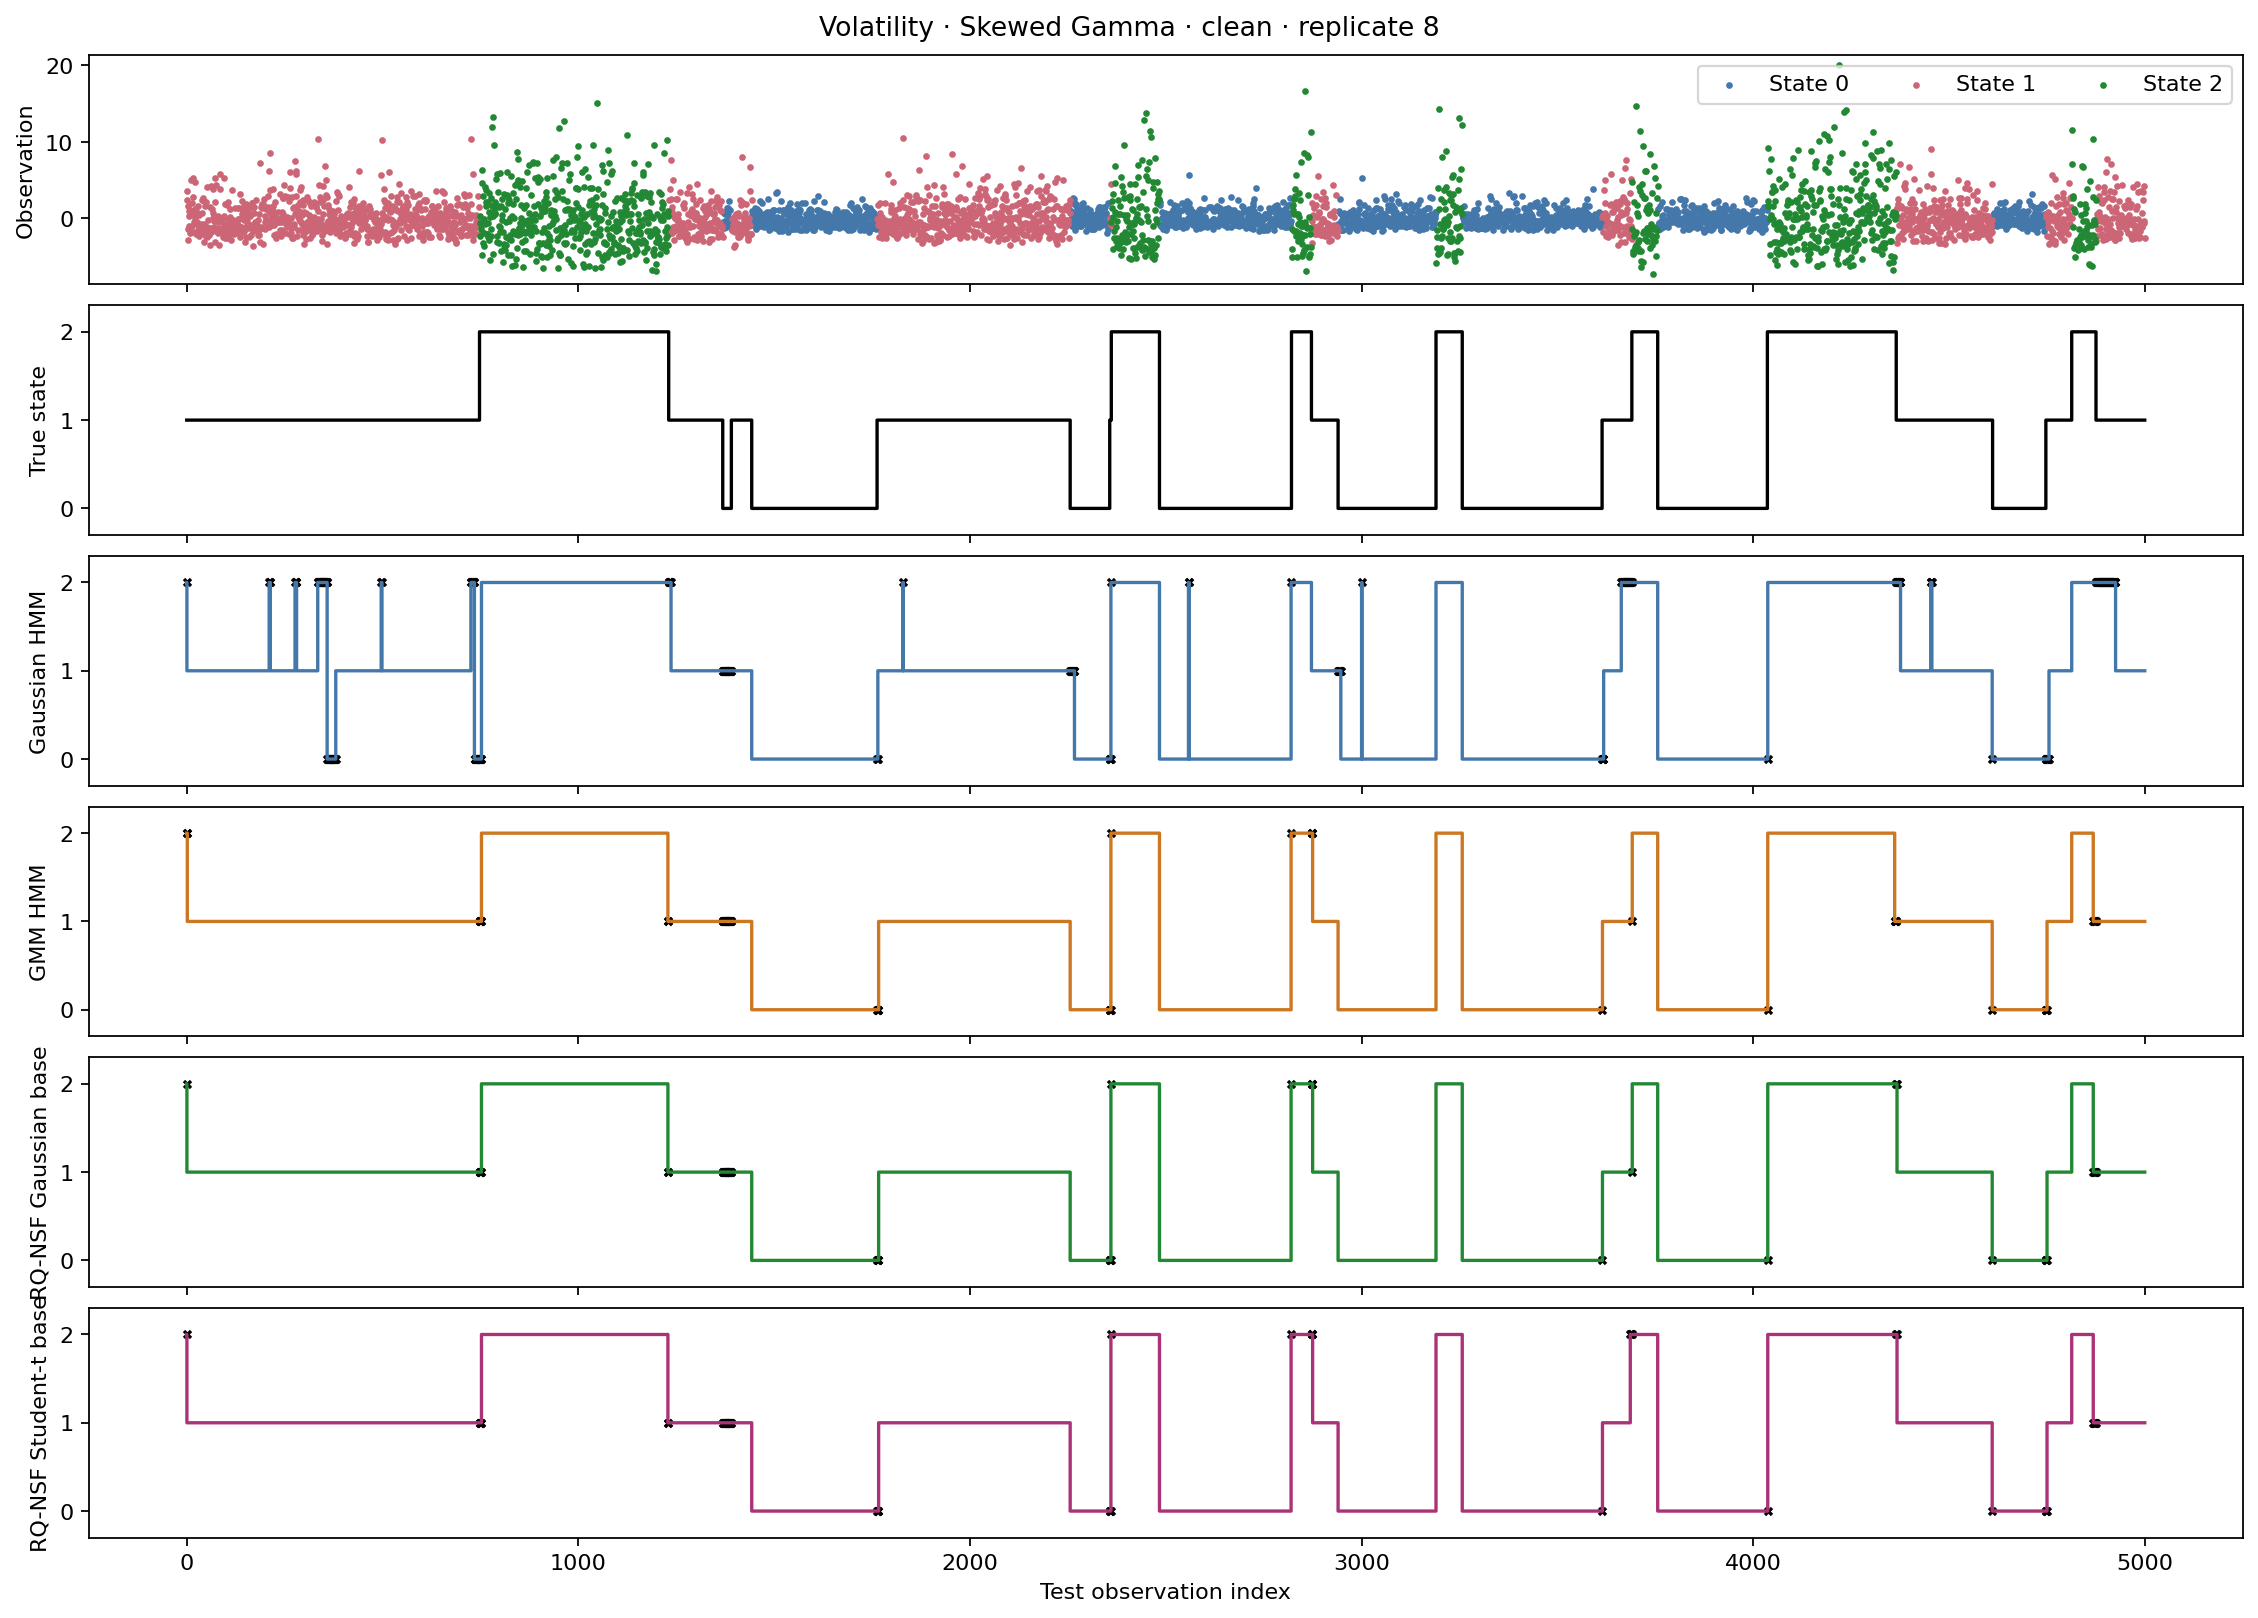

In [ ]:
if report_ready:
    for family in volatility_source.families:
        fig = experiment.plot_decoding(
            volatility_source, run_dir, family=family,
            condition="clean", points=5000, replicate=representative_replicate,
        )
        show_and_save(
            fig,
            f"volatility_{family}_replicate_{representative_replicate}"
            "_representative_decoded_paths",
        )


## Thirty initializations diagnostics: volatility Trimodal replicate 0

In [2]:
import importlib
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# This cell can run first in a fresh kernel, without the main experiment setup.
diagnostic_project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src/flexible_emission_hmm").is_dir()
)
for path in (diagnostic_project_root / "src", diagnostic_project_root / "notebooks"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import nf_hmmlearn_comparison as experiment
import nf_initialization_diagnostics as initialization_diagnostic

initialization_diagnostic = importlib.reload(initialization_diagnostic)
INITIALIZATION_EXPERIMENT_NAME = (
    "four_emissions_p995_hmmlearn_m10_l2_b8-16_s2_i150"
    "_batch2048_float64_cpu8x1_v2_patience5_v2"
)
INITIALIZATION_STARTS = 30
INITIALIZATION_WORKERS = 8
INITIALIZATION_THREADS = 1
RUN_INITIALIZATION_DIAGNOSTIC = False  # Load saved fits
initialization_run_dir = (
    diagnostic_project_root / "data/synthetic/nf_spline_experiments"
    / INITIALIZATION_EXPERIMENT_NAME
)
initialization_dir = (
    initialization_run_dir / "initialization_diagnostics"
    / f"volatility_Trimodal_rep0_gaussian_{INITIALIZATION_STARTS}starts_v1"
)

if RUN_INITIALIZATION_DIAGNOSTIC:
    diagnostic_source = experiment.load_sources(
        diagnostic_project_root, experiment.SOURCES,
    )["volatility"]
    initialization_summary = initialization_diagnostic.run_initialization_diagnostic(
        diagnostic_source, initialization_run_dir, initialization_dir,
        n_starts=INITIALIZATION_STARTS, n_jobs=INITIALIZATION_WORKERS,
        torch_threads=INITIALIZATION_THREADS,
    )
elif (initialization_dir / "summary.csv").exists():
    initialization_summary = pd.read_csv(initialization_dir / "summary.csv")
else:
    raise FileNotFoundError(
        f"No saved diagnostic summary at {initialization_dir}. "
        "Check INITIALIZATION_EXPERIMENT_NAME, or enable diagnostic fitting."
    )

diagnostic_request = experiment.read_json(initialization_dir / "request.json")
print("Diagnostic output:", initialization_dir)
print("Selected emission settings:", diagnostic_request["settings"])
print("Saved initialization fits:", len(initialization_summary))


Diagnostic output: /Users/leoyang/Desktop/School/CSCD94/data/synthetic/nf_spline_experiments/four_emissions_p995_hmmlearn_m10_l2_b8-16_s2_i150_batch2048_float64_cpu8x1_v2_patience5_v2/initialization_diagnostics/volatility_Trimodal_rep0_gaussian_30starts_v1
Selected emission settings: {'count_bins': 16, 'num_layers': 1, 'm_step_steps': 20, 'batch_size': 2048, 'learning_rate': 0.001, 'bound': 5.0, 'device': 'cpu', 'dtype': 'float64', 'base_distribution': 'normal', 'base_df': 5.0, 'convergence_patience': 5}
Saved initialization fits: 30


### Initialization outcomes

Compare training likelihood, convergence, regime recovery, and switch counts across all 30 starts. Start IDs are zero-based, from 0 to 29.

,start,seed,selected,status,train_ll,iterations,converged,stop_reason,fit_seconds,f1_macro,test_nll,inferred_switches,true_switches,transition_rmse
25,25,2078858383,True,ok,-37126.491,289,True,tolerance,26.69,0.9949,1.88452,30,30,0.000818
29,29,1067671922,False,ok,-37139.391,317,True,tolerance,28.75,0.9937,1.88534,30,30,0.000810
4,4,1940265320,False,ok,-37142.928,278,True,tolerance,30.66,0.9949,1.88482,30,30,0.000821
28,28,2357217143,False,ok,-37151.282,413,True,tolerance,37.18,0.9927,1.88543,30,30,0.000816
6,6,874656713,False,ok,-37156.545,331,True,tolerance,35.54,0.9949,1.88535,30,30,0.000824
22,22,1506230249,False,ok,-37932.403,314,True,tolerance,30.30,0.9946,1.93474,30,30,0.000819
19,19,946882203,False,ok,-39918.747,251,True,tolerance,26.98,0.4804,2.03415,817,30,0.334316
17,17,91359913,False,ok,-39930.135,291,True,tolerance,30.94,0.4767,2.03430,839,30,0.335450
14,14,811318815,False,ok,-39932.052,258,True,tolerance,27.64,0.4427,2.03419,904,30,0.335363
21,21,1026232420,False,ok,-39941.783,176,True,tolerance,18.40,0.4620,2.03548,869,30,0.335149


Best start by training likelihood: 25
Converged fits: 30 of 30


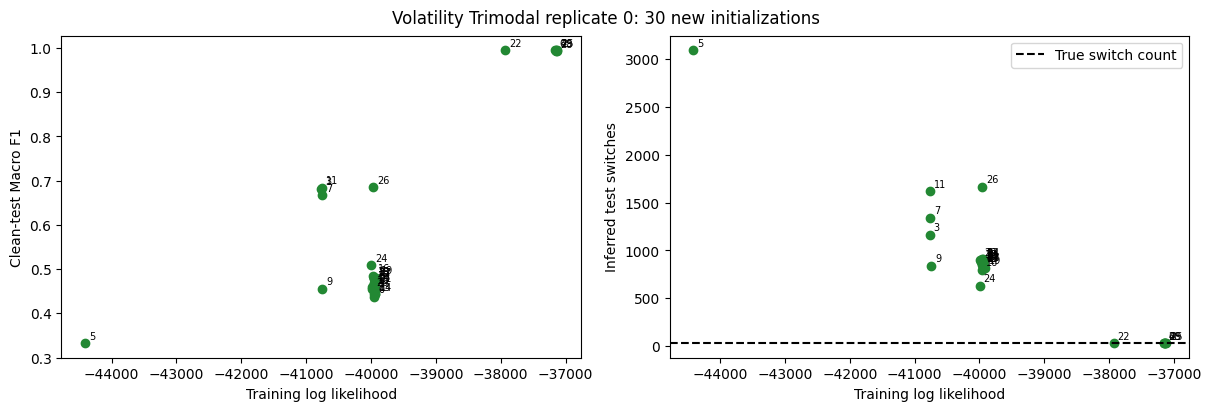

In [3]:
if not initialization_summary.empty:
    diagnostic_columns = [
        "start", "seed", "selected", "status", "train_ll", "iterations",
        "converged", "stop_reason", "fit_seconds", "f1_macro", "test_nll",
        "inferred_switches", "true_switches", "transition_rmse",
    ]
    display(initialization_summary[diagnostic_columns].sort_values(
        "train_ll", ascending=False,
    ).round({
        "train_ll": 3, "fit_seconds": 2, "f1_macro": 4,
        "test_nll": 5, "transition_rmse": 6,
    }))
    valid_initializations = initialization_summary[
        initialization_summary.status == "ok"
    ]
    diagnostic_best_start = int(valid_initializations.loc[
        valid_initializations.train_ll.idxmax(), "start",
    ])
    print("Best start by training likelihood:", diagnostic_best_start)
    print("Converged fits:", int(valid_initializations.converged.sum()),
          "of", len(valid_initializations))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for ax, metric, label in zip(
        axes, ("f1_macro", "inferred_switches"),
        ("Clean-test Macro F1", "Inferred test switches"),
    ):
        ax.scatter(valid_initializations.train_ll, valid_initializations[metric],
                   color="#228833")
        for row in valid_initializations.itertuples(index=False):
            ax.annotate(str(row.start), (row.train_ll, getattr(row, metric)),
                        fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax.set(xlabel="Training log likelihood", ylabel=label)
    axes[1].axhline(valid_initializations.true_switches.iloc[0], color="black",
                    linestyle="--", label="True switch count")
    axes[1].legend()
    fig.suptitle("Volatility Trimodal replicate 0: 30 new initializations")
    fig.savefig(initialization_dir / "initialization_outcomes.png", dpi=160,
                bbox_inches="tight")
    display(fig)
    plt.close(fig)


### Chosen initialization

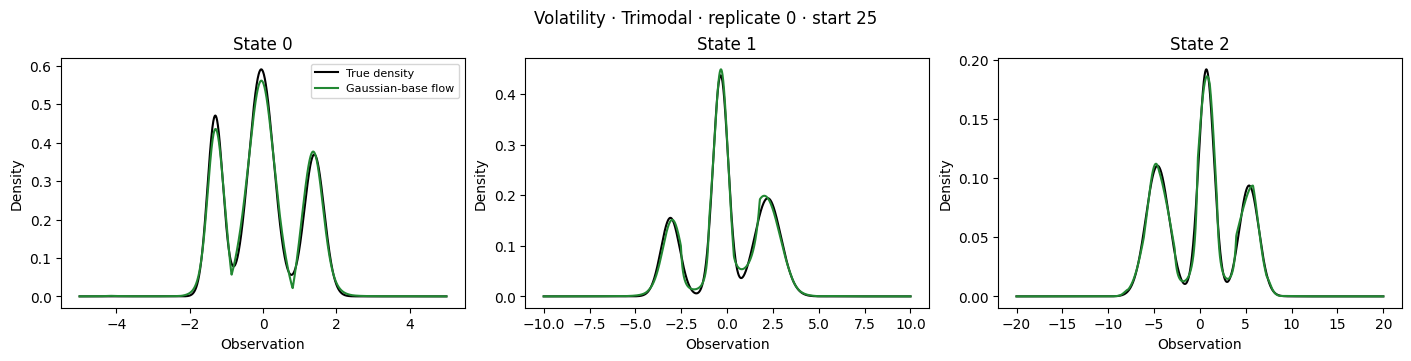

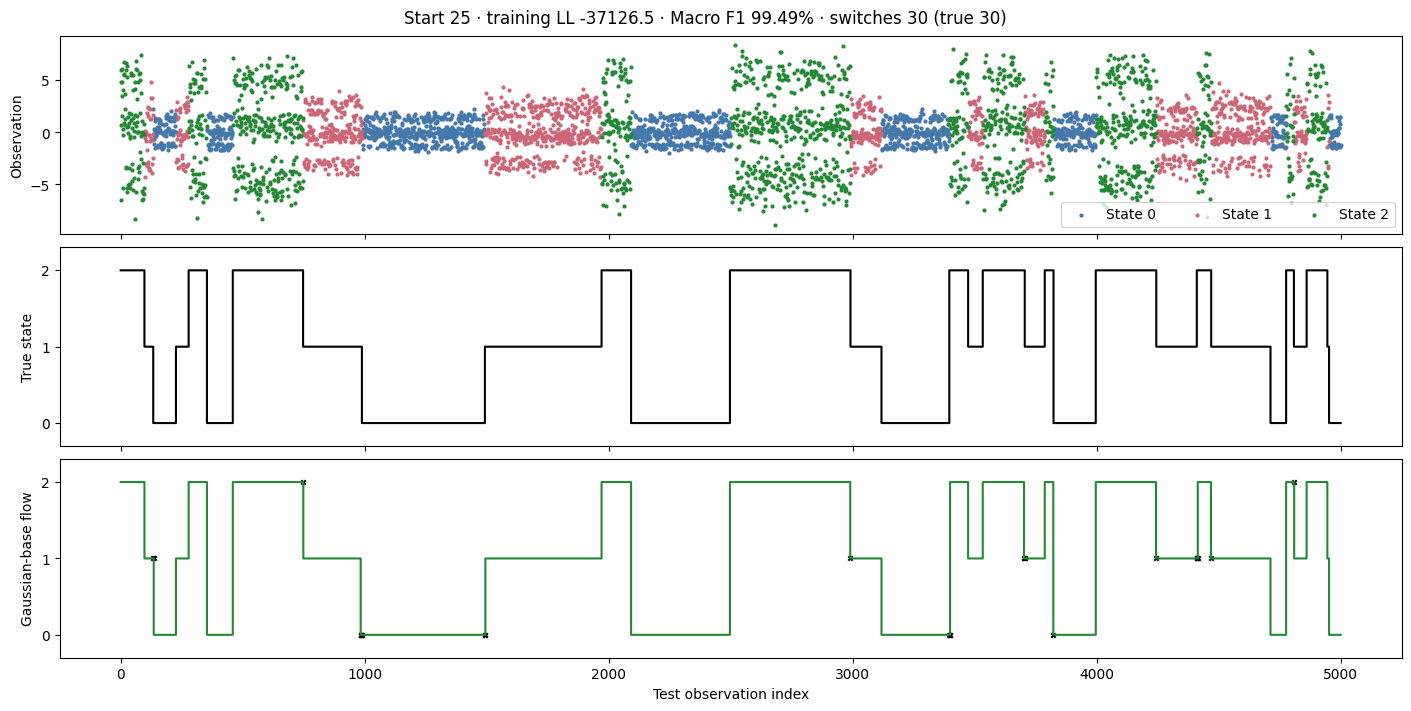

In [14]:
if not initialization_summary.empty:
    INITIALIZATION_VIEW_START = 25  # 0 to 29.
    INITIALIZATION_VIEW_WINDOW = (0, 5000)
    initialization_figures = initialization_diagnostic.plot_initialization(
        initialization_dir, INITIALIZATION_VIEW_START,
        window=INITIALIZATION_VIEW_WINDOW,
    )
    for suffix, fig in zip(("emissions", "decoded_paths"), initialization_figures):
        fig.savefig(
            initialization_dir / f"start_{INITIALIZATION_VIEW_START}_{suffix}.png",
            dpi=160, bbox_inches="tight",
        )
        display(fig)
        plt.close(fig)
